# 03a — Object detection benchmark (D-A LVVO, D-B COCO subset)

Notebook chạy **cả smoke test và full run** cho 03a. Đổi `MODE` ở cell cấu hình: `'smoke'` (20 ảnh mỗi track, kiểm tra pipeline, đo latency/VRAM, **không công bố điểm**) hoặc `'full'` (toàn bộ cohort đã đóng băng).

| Track | Cohort (đã đóng băng) | Ứng viên |
|---|---|---|
| D-B closed | COCO val2017 subset, 2.000 ảnh, 10 lớp | YOLOv8n, YOLO11n, RT-DETR-R18vd |
| D-B open | cùng cohort | Florence-2-base `<OD>` (score-less), GroundingDINO-base |
| D-A open (zero-shot) | LVVO 1.000 ảnh, 4 lớp | Florence-2-base `<OD>`, Florence-2-base `<OPEN_VOCABULARY_DETECTION>` *(bổ sung, cần duyệt)*, GroundingDINO-base |

Mô hình COCO-pretrained **không có lớp table/chart/photo/illustration** nên không chấm trên D-A (`no_corresponding_class`, không ép ánh xạ). D-A và D-B, closed và open luôn báo riêng, không gộp xếp hạng.

**Quy tắc đã đóng băng:** metric = COCO mAP@[.50:.95] (pycocotools 2.0.11); conf = 0.001 cho mAP (0.25 chỉ cho P/R chẩn đoán); NMS IoU 0.7; max 100 box/ảnh; batch 1; ngưỡng thực tế ΔmAP = 0.02; bootstrap theo ảnh (D-B) hoặc nhóm nguồn (D-A), 10.000 lần, cùng lần lấy mẫu cho mọi hệ thống; ảnh lỗi (decode, OOM, timeout, sai kích thước) được **đếm riêng** và chấm như không có dự đoán. Florence-2 **không có score** (mọi box = 1.0): mAP của nó bị chặn trên, chỉ là baseline, không xếp hạng tuyệt đối với mô hình có score.

**Ngân sách:** trần ~15 GPU-giờ cho 03a+03b. Sau smoke, notebook ước tính GPU-giờ của full run từ latency đo thật; nếu vượt trần, **dừng và hỏi** (không tự cắt phạm vi). Full run từ chối chạy nếu chưa có smoke trong cùng `RUN_ID`.

**Giấy phép phần mềm/mô hình (nghiên cứu):** Ultralytics (code + trọng số YOLO) là AGPL-3.0; RT-DETR-R18vd, GroundingDINO: Apache-2.0; Florence-2: MIT. Dữ liệu: COCO ảnh theo điều khoản Flickr, LVVO CC BY 4.0. Không phát hành lại ảnh.

Kết quả ghi vào Drive `MyDrive/DetTrack/<RUN_ID>/`: dự đoán thô (`preds/*.jsonl`), manifest, bảng, hình, `bundle.zip`.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, subprocess, time, shutil, zipfile, re, platform, traceback
from datetime import datetime, timezone

# ============================ CẤU HÌNH ============================
MODE = 'smoke'            # 'smoke' = 20 ảnh/track, không công bố; 'full' = toàn cohort (cần smoke trước)
N_SMOKE = 20
RUN_ID = 'det-03a-261026-v1'
GPU_BUDGET_HOURS = 15.0   # trần chung 03a + 03b; vượt thì dừng và hỏi
ALLOW_OVER_BUDGET = False # chỉ đặt True sau khi người duyệt ngân sách đồng ý
RUN_ABLATION = False      # imgsz 416 cho mô hình closed (tách khỏi xếp hạng chính), chỉ ở full
# ===================================================================

IN_COLAB = Path('/content').exists()
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
WORK = Path('/content/det03a') if IN_COLAB else Path.cwd() / 'det03a-work'
PERSIST = Path('/content/drive/MyDrive/DetTrack') if IN_COLAB else WORK / 'persistent'
PRIOR = Path(os.environ.get('DT_PRIOR', PERSIST / 'det-track-qualification-261026-v3'))
OUT = PERSIST / RUN_ID
for p in (WORK, OUT, OUT / 'preds', OUT / 'figures', OUT / 'tables'):
    p.mkdir(parents=True, exist_ok=True)
if not PRIOR.exists():
    raise FileNotFoundError(f'Thiếu {PRIOR}: cần kết quả qualification đã đóng băng.')
assert MODE in ('smoke', 'full')
if os.environ.get('DT_SKIP_PIP') != '1':
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.190', 'pycocotools==2.0.11',
                    'transformers==4.57.6', 'timm', 'einops', 'gdown', 'huggingface_hub', 'safetensors', 'scipy'], check=True)
import torch
GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
print('MODE:', MODE, '| GPU:', GPU, '| torch', torch.__version__)
if GPU is None:
    print('CẢNH BÁO: không có GPU; latency/VRAM đo trên CPU không dùng được để ước tính ngân sách.')

Mounted at /content/drive
MODE: smoke | GPU: Tesla T4 | torch 2.11.0+cu130


In [2]:
SOURCES = {'experiments/scripts/detection_tracking_qualification.py': '"""Dataset qualification helpers for detection (03a) and tracking (03b).\n\nPure functions so the Colab notebook and the unit tests share one implementation.\nNothing here downloads data or runs a model.\n"""\n\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport re\nimport zipfile\nfrom pathlib import Path\nfrom typing import Any, Callable, Iterable\n\nimport numpy as np\n\n# Frozen by the claim-freeze decision report (2026-10-26).\nCOCO_TAXONOMY = {  # COCO category id -> name\n    1: "person", 44: "bottle", 62: "chair", 72: "tv", 73: "laptop",\n    74: "mouse", 76: "keyboard", 77: "cell phone", 84: "book", 85: "clock",\n}\nPRACTICAL_THRESHOLDS = {"delta_map_50_95": 0.02, "delta_hota": 2.0}\nBOOTSTRAP = {"resamples": 10000, "ci": 0.95, "method": "paired_percentile"}\nCOCO_SIZE_EDGES = (32 ** 2, 96 ** 2)  # COCO small/medium/large area edges\n\n\n# --------------------------------------------------------------------------\n# Hashing, archives\n# --------------------------------------------------------------------------\ndef sha256_file(path: Path, chunk: int = 1 << 20) -> str:\n    digest = hashlib.sha256()\n    with Path(path).open("rb") as handle:\n        for block in iter(lambda: handle.read(chunk), b""):\n            digest.update(block)\n    return digest.hexdigest()\n\n\ndef canonical_json_sha256(value: Any) -> str:\n    return hashlib.sha256(\n        json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode("utf-8")\n    ).hexdigest()\n\n\ndef safe_extract(archive: Path, destination: Path,\n                 keep: Callable[[str], bool] = lambda name: True) -> list[str]:\n    """Extract members accepted by `keep`; reject traversal and symlinks. CRC checked."""\n    destination = Path(destination).resolve()\n    extracted: list[str] = []\n    with zipfile.ZipFile(archive) as zf:\n        for info in zf.infolist():\n            name = info.filename\n            if info.is_dir() or name.startswith("__MACOSX/") or name.endswith(".DS_Store"):\n                continue\n            if not keep(name):\n                continue\n            target = (destination / name).resolve()\n            if not target.is_relative_to(destination):\n                raise ValueError(f"Unsafe archive path: {name}")\n            if (info.external_attr >> 16) & 0o170000 == 0o120000:\n                raise ValueError(f"Symlink in archive: {name}")\n            if target.exists() and target.stat().st_size == info.file_size:\n                extracted.append(name)\n                continue\n            target.parent.mkdir(parents=True, exist_ok=True)\n            with zf.open(info) as src, target.open("wb") as dst:\n                dst.write(src.read())\n            extracted.append(name)\n    return extracted\n\n\ndef reconcile(raw: int, eligible: int, excluded: int, unresolved: int) -> dict[str, int]:\n    """Enforce raw = eligible + excluded + unresolved; never drop units silently."""\n    if raw != eligible + excluded + unresolved:\n        raise ValueError(\n            f"Denominator mismatch: raw={raw} eligible={eligible} "\n            f"excluded={excluded} unresolved={unresolved}")\n    return dict(raw=raw, eligible=eligible, excluded=excluded, unresolved=unresolved)\n\n\ndef exact_overlap(left: Iterable[str], right: Iterable[str]) -> list[str]:\n    return sorted(set(left) & set(right))\n\n\n# --------------------------------------------------------------------------\n# Box helpers\n# --------------------------------------------------------------------------\ndef size_stratum(area: float) -> str:\n    small, medium = COCO_SIZE_EDGES\n    return "small" if area < small else "medium" if area < medium else "large"\n\n\ndef iou_matrix_xywh(boxes: np.ndarray) -> np.ndarray:\n    """Pairwise IoU for an (n,4) xywh array; diagonal set to 0."""\n    n = len(boxes)\n    if n == 0:\n        return np.zeros((0, 0))\n    x1, y1 = boxes[:, 0], boxes[:, 1]\n    x2, y2 = x1 + boxes[:, 2], y1 + boxes[:, 3]\n    iw = np.clip(np.minimum(x2[:, None], x2[None]) - np.maximum(x1[:, None], x1[None]), 0, None)\n    ih = np.clip(np.minimum(y2[:, None], y2[None]) - np.maximum(y1[:, None], y1[None]), 0, None)\n    inter = iw * ih\n    area = boxes[:, 2] * boxes[:, 3]\n    union = area[:, None] + area[None] - inter\n    iou = np.divide(inter, union, out=np.zeros_like(inter, dtype=float), where=union > 0)\n    np.fill_diagonal(iou, 0.0)\n    return iou\n\n\n# --------------------------------------------------------------------------\n# Detection A: LVVO -> COCO\n# --------------------------------------------------------------------------\ndef lvvo_to_coco(dataset_root: Path) -> dict[str, Any]:\n    """Convert the released LVVO 1k four-class labels to COCO JSON.\n\n    Image ids are 1-based over sorted file stems (stable). Invalid boxes and\n    unreadable pairs go to `excluded`, never silently dropped. Images with zero\n    valid boxes stay in the image list as valid negatives.\n    """\n    from PIL import Image\n\n    root = Path(dataset_root)\n    meta = json.loads((root / "dataset_info.json").read_text(encoding="utf-8"))\n    categories = [{"id": int(v), "name": k} for k, v in sorted(meta["categories"].items(), key=lambda kv: int(kv[1]))]\n    class_names = {c["id"]: c["name"] for c in categories}\n    image_paths = {p.stem: p for p in (root / "images").glob("*.jpg")}\n    label_paths = {p.stem: p for p in (root / "labels").glob("*.json")}\n    images, annotations, excluded, ledger = [], [], [], []\n    next_ann = 1\n    for index, stem in enumerate(sorted(image_paths.keys() | label_paths.keys()), start=1):\n        ip, lp = image_paths.get(stem), label_paths.get(stem)\n        if ip is None or lp is None:\n            excluded.append(dict(stem=stem, reason="missing_pair"))\n            continue\n        try:\n            with Image.open(ip) as im:\n                im.load()\n                width, height = im.size\n            labels = json.loads(lp.read_text(encoding="utf-8"))\n        except Exception as exc:  # decode/parse failure is counted, not hidden\n            excluded.append(dict(stem=stem, reason=f"read_error:{type(exc).__name__}"))\n            continue\n        valid_boxes = 0\n        for obj in labels.get("objects", []):\n            b = obj.get("boundingBox", {})\n            x1, y1, x2, y2 = (b.get(k) for k in ("xmin", "ymin", "xmax", "ymax"))\n            numeric = all(isinstance(v, (int, float)) for v in (x1, y1, x2, y2))\n            cid = obj.get("class")\n            if not (numeric and 0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height) or cid not in class_names:\n                excluded.append(dict(stem=stem, reason="invalid_box_or_class", box=[x1, y1, x2, y2], cls=cid))\n                continue\n            w, h = x2 - x1, y2 - y1\n            annotations.append(dict(id=next_ann, image_id=index, category_id=int(cid),\n                                    bbox=[float(x1), float(y1), float(w), float(h)],\n                                    area=float(w * h), iscrowd=0))\n            next_ann += 1\n            valid_boxes += 1\n        images.append(dict(id=index, file_name=ip.name, width=width, height=height))\n        inst = re.match(r"i(\\d+)_", stem)\n        course = re.search(r"_c(\\d+)_", stem)\n        video = re.search(r"_v(\\d+)_", stem)\n        ledger.append(dict(image_id=index, stem=stem, file_name=ip.name, width=width, height=height,\n                           n_boxes=valid_boxes,\n                           group="/".join(f"{k}{m.group(1)}" for k, m in\n                                          (("i", inst), ("c", course), ("v", video)) if m),\n                           sha256=sha256_file(ip)))\n    return dict(coco=dict(images=images, annotations=annotations, categories=categories),\n                excluded=excluded, ledger=ledger, class_names=class_names,\n                stems_total=len(image_paths.keys() | label_paths.keys()),\n                released_images=len(image_paths), released_labels=len(label_paths))\n\n\ndef dhash64(path: Path) -> int:\n    from PIL import Image\n    with Image.open(path) as im:\n        arr = np.asarray(im.convert("L").resize((9, 8), Image.Resampling.LANCZOS))\n    bits = (arr[:, 1:] > arr[:, :-1]).ravel()\n    value = 0\n    for bit in bits:\n        value = (value << 1) | int(bit)\n    return value\n\n\ndef near_duplicate_pairs(hashes: dict[str, int], groups: dict[str, str],\n                         sha: dict[str, str], max_distance: int = 4) -> list[dict[str, Any]]:\n    """All non-identical pairs within dHash Hamming distance; review flags only."""\n    keys = sorted(hashes)\n    values = np.array([hashes[k] for k in keys], dtype=np.uint64)\n    pairs = []\n    for i in range(len(keys) - 1):\n        xor = values[i] ^ values[i + 1:]\n        dist = np.array([int(v).bit_count() for v in xor])\n        for j in np.nonzero(dist <= max_distance)[0]:\n            other = keys[i + 1 + int(j)]\n            if sha[keys[i]] == sha[other]:\n                continue\n            pairs.append(dict(left=keys[i], right=other, distance=int(dist[j]),\n                              same_group=groups[keys[i]] == groups[other]))\n    return pairs\n\n\n# --------------------------------------------------------------------------\n# Detection B: COCO subset\n# --------------------------------------------------------------------------\ndef select_coco_subset(coco: dict[str, Any], n_images: int, seed: int,\n                       taxonomy: dict[int, str] = COCO_TAXONOMY) -> dict[str, Any]:\n    """Seeded subset: per-class quota of images, balanced over box-size strata, then fill.\n\n    Eligible image = at least one non-crowd taxonomy box. Result is deterministic\n    for (coco, n_images, seed).\n    """\n    rng = np.random.default_rng(seed)\n    by_image: dict[int, list[dict]] = {}\n    for ann in coco["annotations"]:\n        if ann["category_id"] in taxonomy and not ann.get("iscrowd", 0):\n            by_image.setdefault(ann["image_id"], []).append(ann)\n    eligible = sorted(by_image)\n    # (class, stratum) -> sorted candidate image ids\n    cell: dict[tuple[int, str], list[int]] = {}\n    for image_id in eligible:\n        for ann in by_image[image_id]:\n            cell.setdefault((ann["category_id"], size_stratum(ann["area"])), []).append(image_id)\n    cell = {k: sorted(set(v)) for k, v in cell.items()}\n    class_images = {c: sorted({i for (cc, _), v in cell.items() if cc == c for i in v}) for c in taxonomy}\n    quota = max(1, n_images // len(taxonomy))\n    selected: set[int] = set()\n    for cid in sorted(taxonomy, key=lambda c: (len(class_images[c]), c)):  # rarest first\n        members = set(class_images[cid])\n        have = lambda: len(selected & members)\n        strata = [s for s in ("small", "medium", "large") if cell.get((cid, s))]\n        pools = {s: list(rng.permutation(cell[(cid, s)])) for s in strata}\n        while strata and have() < quota and len(selected) < n_images:\n            for s in list(strata):\n                while pools[s] and pools[s][-1] in selected:\n                    pools[s].pop()\n                if not pools[s]:\n                    strata.remove(s)\n                    continue\n                selected.add(int(pools[s].pop()))\n                if have() >= quota or len(selected) >= n_images:\n                    break\n    remaining = [i for i in eligible if i not in selected]\n    need = min(n_images, len(eligible)) - len(selected)\n    if need > 0:\n        selected.update(int(i) for i in rng.permutation(remaining)[:need])\n    ids = sorted(selected)\n    keep = set(ids)\n    anns = [a for a in coco["annotations"] if a["image_id"] in keep and a["category_id"] in taxonomy]\n    return dict(image_ids=ids, annotations=anns,\n                eligible_images=len(eligible), seed=seed, n_images=n_images,\n                quota_per_class=quota)\n\n\n# --------------------------------------------------------------------------\n# Tracking: MOT-format GT\n# --------------------------------------------------------------------------\nMOT_MEMBER = re.compile(\n    r"(?:^|.*/)(?P<split>train|val|test)/(?P<seq>[^/]+)/"\n    r"(?P<kind>seqinfo\\.ini|gt/gt\\.txt|img1/(?P<frame>\\d+)\\.jpg)$")\n\n\n_MEMBER_TAIL = re.compile(\n    r"(?:^|.*/)(?P<seq>[^/]+)/(?P<kind>seqinfo\\.ini|gt/gt\\.txt|img1/(?P<frame>\\d+)\\.jpg)$")\n_SPLIT_DIR = re.compile(r"^(train|val|test)\\d*$", re.I)\n\n\ndef parse_mot_member(name: str, default_split: str | None = None) -> dict[str, str] | None:\n    """Classify an archive member of a MOT-style dataset.\n\n    The split is the nearest ancestor directory named train*/val*/test* (so `train1/seq/...`\n    counts as train), else `default_split` (typically taken from the archive file name).\n    """\n    m = _MEMBER_TAIL.match(name)\n    if not m or m["seq"] in (".", ".."):\n        return None\n    dirs = name.split("/")\n    ancestors = dirs[: -(2 if m["kind"] == "seqinfo.ini" else 3)]  # drop seq dir (+ gt/img1) and file\n    split = next((_SPLIT_DIR.match(p).group(1).lower() for p in reversed(ancestors) if _SPLIT_DIR.match(p)),\n                 default_split)\n    if split is None:\n        return None\n    return dict(split=split, seq=m["seq"], kind=m["kind"], frame=m["frame"])\n\n\ndef parse_seqinfo(text: str) -> dict[str, str]:\n    out = {}\n    for line in text.splitlines():\n        if "=" in line:\n            key, value = line.split("=", 1)\n            out[key.strip()] = value.strip()\n    return out\n\n\ndef sample_frame_indices(seq_length: int, pairs: int = 8) -> list[int]:\n    """Frame numbers (1-based): first, last, and `pairs` consecutive pairs spread over the video."""\n    if seq_length <= 0:\n        return []\n    picks = {1, seq_length}\n    for k in range(pairs):\n        t = 1 + int(round(k * max(seq_length - 2, 0) / max(pairs, 1)))\n        picks.update({t, min(t + 1, seq_length)})\n    return sorted(picks)\n\n\ndef parse_mot_gt(text: str) -> np.ndarray:\n    rows = [r for r in (line.strip().split(",") for line in text.splitlines()) if len(r) >= 6]\n    if not rows:\n        return np.zeros((0, 9))\n    width = max(len(r) for r in rows)\n    arr = np.full((len(rows), max(width, 9)), np.nan)\n    for i, r in enumerate(rows):\n        arr[i, :len(r)] = [float(v) for v in r]\n    return arr\n\n\ndef mot_sequence_stats(gt: np.ndarray, seq_length: int, im_width: int, im_height: int) -> dict[str, Any]:\n    """Per-sequence EDA: density, track lengths, ID integrity, occlusion proxy."""\n    if len(gt) == 0:\n        return dict(boxes=0, tracks=0, issues=["empty_gt"])\n    frames, ids = gt[:, 0].astype(int), gt[:, 1].astype(int)\n    boxes = gt[:, 2:6]\n    dup_frame_id = len(gt) - len({(f, i) for f, i in zip(frames, ids)})\n    bad_size = int(((boxes[:, 2] <= 0) | (boxes[:, 3] <= 0)).sum())\n    out_of_range = int(((frames < 1) | (frames > seq_length)).sum())\n    off_image = int(((boxes[:, 0] + boxes[:, 2] < 0) | (boxes[:, 1] + boxes[:, 3] < 0) |\n                     (boxes[:, 0] > im_width) | (boxes[:, 1] > im_height)).sum())\n    track_len, gap_tracks = [], 0\n    for tid in np.unique(ids):\n        f = np.sort(frames[ids == tid])\n        track_len.append(len(f))\n        if f[-1] - f[0] + 1 != len(f):\n            gap_tracks += 1\n    per_frame = np.bincount(frames[(frames >= 1) & (frames <= seq_length)], minlength=seq_length + 1)[1:]\n    occluded = 0\n    for f in np.unique(frames):\n        b = boxes[frames == f]\n        if len(b) > 1:\n            occluded += int((iou_matrix_xywh(b).max(axis=1) > 0.3).sum())\n    conf = gt[:, 6] if gt.shape[1] > 6 else np.ones(len(gt))\n    return dict(\n        boxes=int(len(gt)), tracks=int(len(track_len)), frames_with_boxes=int((per_frame > 0).sum()),\n        seq_length=int(seq_length), boxes_per_frame_mean=float(per_frame.mean()),\n        boxes_per_frame_max=int(per_frame.max()),\n        track_len_min=int(min(track_len)), track_len_median=float(np.median(track_len)),\n        track_len_max=int(max(track_len)), tracks_with_gaps=int(gap_tracks),\n        duplicate_frame_id_rows=int(dup_frame_id), nonpositive_size_rows=bad_size,\n        frame_out_of_range_rows=out_of_range, off_image_rows=off_image,\n        ignored_conf0_rows=int((np.nan_to_num(conf, nan=1.0) == 0).sum()),\n        occluded_box_fraction=float(occluded / len(gt)),\n        box_height_median=float(np.median(boxes[:, 3])),\n        ids_valid=bool((ids >= 0).all() and (gt[:, 1] == ids).all()),  # DanceTrack ids start at 0\n    )\n\n\ndef mot_blocking_issues(stats: dict[str, Any]) -> int:\n    return int(stats.get("duplicate_frame_id_rows", 0) + stats.get("nonpositive_size_rows", 0)\n               + stats.get("frame_out_of_range_rows", 0) + (0 if stats.get("ids_valid", True) else 1)\n               + (1 if "empty_gt" in stats.get("issues", []) else 0))\n\n\ndef camera_motion_pixels(gray_pairs: list[tuple[np.ndarray, np.ndarray]]) -> float:\n    """Median global shift (px) between consecutive frames via phase correlation.\n\n    A descriptive proxy for static vs moving camera, not a ground-truth label.\n    """\n    import cv2\n\n    shifts = []\n    for a, b in gray_pairs:\n        (dx, dy), _ = cv2.phaseCorrelate(np.float32(a), np.float32(b))\n        shifts.append(float(np.hypot(dx, dy)))\n    return float(np.median(shifts)) if shifts else float("nan")\n\n\n# --------------------------------------------------------------------------\n# Decision\n# --------------------------------------------------------------------------\ndef qualification_decision(*, license_verified: bool, license_ack: bool, blocking_qa: int,\n                           exact_leakage: int, acquired: bool, claim_scope_ok: bool = True) -> dict[str, str]:\n    """keep / repair / restrict / reject for one dataset, with the reason."""\n    if not acquired:\n        return dict(decision="HOLD", reason="data not acquired in this run")\n    if not license_verified:\n        return dict(decision="REJECT", reason="license not verified from official source (plan rule)")\n    if not license_ack:\n        return dict(decision="HOLD", reason="license text shown but not acknowledged by the user")\n    if exact_leakage:\n        return dict(decision="REPAIR", reason=f"{exact_leakage} exact dev/eval overlaps")\n    if blocking_qa:\n        return dict(decision="REPAIR", reason=f"{blocking_qa} blocking QA issues")\n    if not claim_scope_ok:\n        return dict(decision="RESTRICT", reason="claim scope narrower than requested")\n    return dict(decision="KEEP", reason="all gates passed for the scoped protocol")\n', 'experiments/scripts/detection_scoring.py': '"""Detection scoring for benchmark 03a: pycocotools mAP@[.50:.95] plus a paired-bootstrap-ready cache.\n\nPrimary numbers always come from pycocotools (`coco_summary`). `DetectionCache` re-derives the\nsame AP from the per-image matches pycocotools already computed, so the bootstrap can resample\nimages/groups without re-running matching. Equality with pycocotools (and with a physically\nreplicated dataset) is unit-tested.\n"""\n\nfrom __future__ import annotations\n\nimport contextlib\nimport io\nimport re\nfrom typing import Any, Iterable, Sequence\n\nimport numpy as np\n\nSTAT_NAMES = ["ap_50_95", "ap50", "ap75", "ap_small", "ap_medium", "ap_large",\n              "ar_1", "ar_10", "ar_100", "ar_small", "ar_medium", "ar_large"]\n\n\ndef _coco(gt: dict[str, Any]):\n    from pycocotools.coco import COCO\n    coco = COCO()\n    coco.dataset = {k: v for k, v in gt.items()}\n    coco.dataset.setdefault("info", {})\n    coco.dataset.setdefault("licenses", [])\n    with contextlib.redirect_stdout(io.StringIO()):\n        coco.createIndex()\n    return coco\n\n\ndef _load_res(coco, preds: list[dict]):\n    with contextlib.redirect_stdout(io.StringIO()):\n        return coco.loadRes(preds)\n\n\ndef clean_predictions(preds: Iterable[dict], image_ids: set[int] | None = None,\n                      cat_ids: set[int] | None = None) -> list[dict]:\n    """Keep only predictions for evaluated images/classes; normalise to COCO result format."""\n    out = []\n    for p in preds:\n        if image_ids is not None and p["image_id"] not in image_ids:\n            continue\n        if cat_ids is not None and p["category_id"] not in cat_ids:\n            continue\n        out.append(dict(image_id=int(p["image_id"]), category_id=int(p["category_id"]),\n                        bbox=[float(v) for v in p["bbox"]], score=float(p["score"])))\n    return out\n\n\ndef is_score_less(preds: Sequence[dict]) -> bool:\n    """True when every box carries the same score (e.g. Florence-2 <OD>): AP is then bounded."""\n    return len(preds) > 0 and len({round(float(p["score"]), 9) for p in preds}) == 1\n\n\ndef apply_failure_policy(preds: Iterable[dict], image_ids: Sequence[int], failed: Iterable[int]) -> dict[str, Any]:\n    """Failed images keep their GT but contribute no predictions (counted as misses).\n\n    Returns the predictions to score on all images and the list of successful image ids, so both\n    \'all images, failures = misses\' and \'successful images only\' can be reported.\n    """\n    failed = set(failed)\n    all_ids = [i for i in image_ids]\n    preds_all = [p for p in preds if p["image_id"] not in failed]\n    ok = [i for i in all_ids if i not in failed]\n    return dict(preds=preds_all, image_ids_all=all_ids, image_ids_success=ok, n_failed=len(failed & set(all_ids)))\n\n\ndef coco_summary(gt: dict[str, Any], preds: list[dict], image_ids: Sequence[int] | None = None,\n                 cat_ids: Sequence[int] | None = None) -> dict[str, float]:\n    """Standard pycocotools bbox evaluation; returns the 12 summary statistics (-1 where undefined)."""\n    from pycocotools.cocoeval import COCOeval\n    coco = _coco(gt)\n    image_ids = list(image_ids) if image_ids is not None else sorted(coco.getImgIds())\n    cat_ids = list(cat_ids) if cat_ids is not None else sorted(coco.getCatIds())\n    preds = clean_predictions(preds, set(image_ids), set(cat_ids))\n    if not preds:\n        return {name: 0.0 for name in STAT_NAMES}\n    dt = _load_res(coco, preds)\n    ev = COCOeval(coco, dt, "bbox")\n    ev.params.imgIds, ev.params.catIds = image_ids, cat_ids\n    with contextlib.redirect_stdout(io.StringIO()):\n        ev.evaluate()\n        ev.accumulate()\n        ev.summarize()\n    return dict(zip(STAT_NAMES, (float(s) for s in ev.stats)))\n\n\nclass DetectionCache:\n    """Per-image match results from pycocotools, re-aggregated under image multiplicities.\n\n    Only the headline setting is cached (area range \'all\', maxDets = 100, IoU .50:.05:.95).\n    """\n\n    def __init__(self, gt: dict[str, Any], preds: list[dict], image_ids: Sequence[int] | None = None,\n                 cat_ids: Sequence[int] | None = None, max_dets: int = 100):\n        from pycocotools.cocoeval import COCOeval\n        coco = _coco(gt)\n        self.image_ids = list(image_ids) if image_ids is not None else sorted(coco.getImgIds())\n        self.cat_ids = list(cat_ids) if cat_ids is not None else sorted(coco.getCatIds())\n        self.cat_names = {c["id"]: c["name"] for c in gt["categories"] if c["id"] in set(self.cat_ids)}\n        preds = clean_predictions(preds, set(self.image_ids), set(self.cat_ids))\n        self.rec_thrs = np.linspace(0.0, 1.0, 101)\n        n_img = len(self.image_ids)\n        T = 10\n        self.per_cat: dict[int, dict[str, np.ndarray]] = {}\n        if preds:\n            dt = _load_res(coco, preds)\n        else:   # no detections at all: only the GT counts matter\n            dt = _load_res(coco, [dict(image_id=self.image_ids[0], category_id=self.cat_ids[0], bbox=[0, 0, 1, 1], score=0.0)])\n            dt.dataset["annotations"] = []\n            dt.anns, dt.imgToAnns = {}, {}\n        ev = COCOeval(coco, dt, "bbox")\n        ev.params.imgIds, ev.params.catIds = self.image_ids, self.cat_ids\n        ev.params.areaRng, ev.params.areaRngLbl = [[0 ** 2, 1e5 ** 2]], ["all"]\n        ev.params.maxDets = [max_dets]\n        with contextlib.redirect_stdout(io.StringIO()):\n            ev.evaluate()\n        for k, cid in enumerate(self.cat_ids):\n            scores, tp, ign, img_idx = [], [], [], []\n            npig_img = np.zeros(n_img, dtype=np.int64)\n            for i in range(n_img):\n                e = ev.evalImgs[k * n_img + i]\n                if e is None:\n                    continue\n                npig_img[i] = int((np.asarray(e["gtIgnore"]) == 0).sum())\n                d = len(e["dtScores"])\n                if d:\n                    scores.append(np.asarray(e["dtScores"], dtype=float))\n                    tp.append(np.asarray(e["dtMatches"]) > 0)\n                    ign.append(np.asarray(e["dtIgnore"], dtype=bool))\n                    img_idx.append(np.full(d, i, dtype=np.int64))\n            self.per_cat[cid] = dict(\n                scores=np.concatenate(scores) if scores else np.zeros(0),\n                tp=np.concatenate(tp, axis=1) if tp else np.zeros((T, 0), dtype=bool),\n                ign=np.concatenate(ign, axis=1) if ign else np.zeros((T, 0), dtype=bool),\n                img_idx=np.concatenate(img_idx) if img_idx else np.zeros(0, dtype=np.int64),\n                npig_img=npig_img)\n\n    def _class_ap(self, c: dict[str, np.ndarray], w: np.ndarray) -> np.ndarray | None:\n        """AP per IoU threshold for one class under integer image weights; None if no GT."""\n        npig = int((w * c["npig_img"]).sum())\n        if npig == 0:\n            return None\n        reps = w[c["img_idx"]]\n        idx = np.repeat(np.arange(len(reps)), reps)\n        if len(idx) == 0:\n            return np.zeros(c["tp"].shape[0])\n        order = np.argsort(-c["scores"][idx], kind="mergesort")\n        sel = idx[order]\n        tp, ign = c["tp"][:, sel], c["ign"][:, sel]\n        tps = tp & ~ign\n        fps = ~tp & ~ign\n        tp_sum = np.cumsum(tps, axis=1).astype(float)\n        fp_sum = np.cumsum(fps, axis=1).astype(float)\n        ap = np.zeros(tp.shape[0])\n        nd = tp.shape[1]\n        for t in range(tp.shape[0]):\n            rc = tp_sum[t] / npig\n            pr = tp_sum[t] / (fp_sum[t] + tp_sum[t] + np.spacing(1))\n            pr = np.maximum.accumulate(pr[::-1])[::-1]\n            inds = np.searchsorted(rc, self.rec_thrs, side="left")\n            q = np.where(inds < nd, pr[np.minimum(inds, nd - 1)], 0.0)\n            ap[t] = q.mean()\n        return ap\n\n    def metrics(self, weights: np.ndarray | None = None) -> dict[str, Any]:\n        n = len(self.image_ids)\n        w = np.ones(n, dtype=np.int64) if weights is None else np.asarray(weights, dtype=np.int64)\n        per_class = {}\n        for cid, c in self.per_cat.items():\n            ap = self._class_ap(c, w)\n            if ap is not None:\n                per_class[self.cat_names.get(cid, cid)] = ap\n        if not per_class:\n            return dict(map_50_95=float("nan"), ap50=float("nan"), per_class_ap={})\n        mat = np.stack(list(per_class.values()))\n        return dict(map_50_95=float(mat.mean()), ap50=float(mat[:, 0].mean()), ap75=float(mat[:, 5].mean()),\n                    per_class_ap={k: float(v.mean()) for k, v in per_class.items()},\n                    per_class_ap50={k: float(v[0]) for k, v in per_class.items()})\n\n    def map_fn(self, key: str = "map_50_95"):\n        return lambda w: self.metrics(w)[key]\n\n    def precision_recall(self, conf: float, weights: np.ndarray | None = None) -> dict[str, float]:\n        """Diagnostic only: pooled precision/recall at IoU 0.5 for detections with score >= conf."""\n        n = len(self.image_ids)\n        w = np.ones(n, dtype=np.int64) if weights is None else np.asarray(weights, dtype=np.int64)\n        tp_tot = fp_tot = gt_tot = 0\n        for c in self.per_cat.values():\n            keep = (c["scores"] >= conf) & ~c["ign"][0]\n            wt = w[c["img_idx"]][keep]\n            tp_tot += int((wt * c["tp"][0][keep]).sum())\n            fp_tot += int((wt * ~c["tp"][0][keep]).sum())\n            gt_tot += int((w * c["npig_img"]).sum())\n        p = tp_tot / (tp_tot + fp_tot) if tp_tot + fp_tot else 0.0\n        r = tp_tot / gt_tot if gt_tot else 0.0\n        return dict(precision=p, recall=r, tp=tp_tot, fp=fp_tot, fn=gt_tot - tp_tot)\n\n\n# --------------------------------------------------------------------------\n# Open-vocabulary label mapping (frozen taxonomy map)\n# --------------------------------------------------------------------------\n_ARTICLES = re.compile(r"^(a|an|the)\\s+", re.I)\n\n\ndef normalise_label(label: str) -> str:\n    return re.sub(r"\\s+", " ", _ARTICLES.sub("", label.strip().lower()))\n\n\ndef map_open_vocab(preds: Iterable[dict], taxonomy_map: dict[str, list[str]],\n                   name_to_id: dict[str, int]) -> dict[str, Any]:\n    """Map free-text `label` of each prediction to a taxonomy category id.\n\n    Unmapped labels are kept out of scoring but counted (`unknown_concept_rate`); the reported\n    `taxonomy_mapping_coverage` is the share of predicted boxes whose label was mapped.\n    """\n    lookup = {normalise_label(s): cat for cat, syns in taxonomy_map.items() for s in syns}\n    lookup.update({normalise_label(cat): cat for cat in taxonomy_map})\n    mapped, unknown, total = [], 0, 0\n    for p in preds:\n        total += 1\n        cat = lookup.get(normalise_label(p["label"]))\n        if cat is None:\n            unknown += 1\n            continue\n        mapped.append(dict(image_id=p["image_id"], category_id=name_to_id[cat], bbox=p["bbox"], score=p["score"]))\n    return dict(preds=mapped, unknown_concept_rate=unknown / total if total else 0.0,\n                taxonomy_mapping_coverage=(total - unknown) / total if total else 0.0, n_boxes=total)\n', 'experiments/scripts/paired_bootstrap.py': '"""Paired cluster bootstrap and the pre-registered decision rule (shared by detection and tracking).\n\nUnits are images or videos; `groups` lets dependent units (LVVO source groups) be resampled together.\nThe same multiplicity matrix is applied to every compared system, so differences are paired.\n"""\n\nfrom __future__ import annotations\n\nfrom typing import Callable, Sequence\n\nimport numpy as np\n\n\ndef cluster_multiplicities(n_units: int, groups: Sequence | None, resamples: int, seed: int) -> np.ndarray:\n    """(resamples, n_units) integer matrix: how often each unit appears in each bootstrap sample.\n\n    Whole groups are drawn with replacement; every unit of a drawn group is included.\n    With `groups=None` each unit is its own group (plain bootstrap).\n    """\n    rng = np.random.default_rng(seed)\n    if groups is None:\n        labels = np.arange(n_units)\n    else:\n        labels = np.asarray(groups)\n        assert len(labels) == n_units\n    uniq, inv = np.unique(labels, return_inverse=True)\n    k = len(uniq)\n    draws = rng.integers(0, k, size=(resamples, k))\n    group_counts = np.stack([np.bincount(row, minlength=k) for row in draws])      # (R, k)\n    return group_counts[:, inv].astype(np.int64)\n\n\ndef paired_bootstrap(metric_a: Callable[[np.ndarray], float], metric_b: Callable[[np.ndarray], float],\n                     multiplicities: np.ndarray, level: float = 0.95) -> dict[str, float]:\n    """Bootstrap the paired difference a - b. Metrics take a per-unit multiplicity vector."""\n    n = multiplicities.shape[1]\n    ones = np.ones(n, dtype=np.int64)\n    a_hat, b_hat = float(metric_a(ones)), float(metric_b(ones))\n    a = np.array([metric_a(m) for m in multiplicities], dtype=float)\n    b = np.array([metric_b(m) for m in multiplicities], dtype=float)\n    d = a - b\n    lo_q, hi_q = (1 - level) / 2, 1 - (1 - level) / 2\n    return dict(a=a_hat, b=b_hat, delta=a_hat - b_hat,\n                delta_lo=float(np.nanquantile(d, lo_q)), delta_hi=float(np.nanquantile(d, hi_q)),\n                a_lo=float(np.nanquantile(a, lo_q)), a_hi=float(np.nanquantile(a, hi_q)),\n                b_lo=float(np.nanquantile(b, lo_q)), b_hi=float(np.nanquantile(b, hi_q)),\n                resamples=int(len(d)), nan_resamples=int(np.isnan(d).sum()))\n\n\ndef decide_difference(result: dict[str, float], practical_threshold: float) -> str:\n    """Pre-registered rule: \'a_better\' / \'b_better\' needs the paired CI to exclude 0 AND |delta| >= threshold."""\n    d, lo, hi = result["delta"], result["delta_lo"], result["delta_hi"]\n    if lo > 0 and d >= practical_threshold:\n        return "a_better"\n    if hi < 0 and -d >= practical_threshold:\n        return "b_better"\n    return "indistinguishable"\n', 'experiments/scripts/detection_runner.py': '"""Runner for benchmark 03a (object detection): adapters, resumable inference, scoring and budget gate.\n\nModel-specific imports are lazy, so the scoring/bookkeeping logic is importable and unit-testable\nwithout a GPU. All adapters share one decoding path (PIL RGB, no EXIF rotation) and one output\ncontract: a list of {label, bbox=[x, y, w, h] in pixels, score}.\n"""\n\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport os\nimport time\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\nfrom typing import Any, Callable, Iterable, Sequence\n\nimport numpy as np\n\nfrom experiments.scripts import detection_scoring as ds\n\n# SHA-256 of the vendored Florence-2 checkout used by the product (florence_runtime.py).\nFLORENCE_ASSET_SHA256 = {\n    "model.safetensors": "03075d2d2d2bbd3e180b9ba0afae4aa8563226e2d32911656966e05b2f2ee060",\n    "config.json": "c666d0fe0172d46e115e8fba6cd93cd83714575b33a73005cab8d24ce2a3aa8f",\n    "configuration_florence2.py": "4b351d78012df1bcd0f21ce8b8cb3a82fa6f1790a65b2985d21d6e626f76b603",\n    "modeling_florence2.py": "d0bd64290a87a46cbb9f4eccfa8c58227b1fd301b9039b1b687d413ead6effac",\n    "preprocessor_config.json": "2f5921bbc53c7cc04251e1027b45b1cec726276be6db23d1bb40641bfbe2cf29",\n    "processing_florence2.py": "f146023a507c009f425a49ee39aa037f4f25c64e14336e3e4f3f1d7377a68e98",\n    "tokenizer.json": "847bbeab6174d66a88898f729d52fa8d355fafe1bea101cf960dd404581df70e",\n    "tokenizer_config.json": "79ffcf43af8ebda99d165f61d243180da2e2639952e41e71e11611c18770489c",\n    "vocab.json": "394fdc63c71aabe0a9b97117f5d62fb5fcc4d59b2b3ea929a3929e6a53217b3c",\n}\n\n# Fixed inference settings (registered before any score is seen).\nDEFAULTS = dict(\n    conf=0.001,         # mAP needs the full precision-recall curve; 0.25 is only for P/R diagnostics\n    iou_nms=0.7,        # ultralytics default NMS IoU\n    max_det=100,\n    diag_conf=0.25,\n    imgsz=640,\n    gdino_box_threshold=0.01,\n    florence_task="<OD>",\n    florence_num_beams=3,\n    florence_max_new_tokens=1024,\n    warmup_images=3,\n    max_seconds_per_image=120.0,\n)\n\n\n@dataclass\nclass Candidate:\n    id: str\n    display: str\n    family: str\n    vocabulary: str               # \'closed\' (COCO-80 names) or \'open\' (free text mapped to the taxonomy)\n    adapter: str\n    params: dict[str, Any] = field(default_factory=dict)\n    score_less: bool = False\n    tracks: tuple[str, ...] = ("D-A", "D-B")   # closed COCO models have no LVVO classes: D-B only\n\n\nCANDIDATES: list[Candidate] = [\n    Candidate("yolov8n", "YOLOv8n (COCO-80)", "cnn_realtime", "closed", "yolo", dict(weights="yolov8n.pt"), tracks=("D-B",)),\n    Candidate("yolo11n", "YOLO11n (COCO-80)", "cnn_realtime", "closed", "yolo", dict(weights="yolo11n.pt"), tracks=("D-B",)),\n    Candidate("rtdetr_r18", "RT-DETR-R18vd (COCO-80, HF PekingU/rtdetr_r18vd)", "detr_realtime", "closed", "rtdetr_hf",\n              dict(repo="PekingU/rtdetr_r18vd"), tracks=("D-B",)),\n    Candidate("florence2_base", "Florence-2-base <OD> (open, score-less)", "vlm", "open", "florence",\n              dict(task=DEFAULTS["florence_task"]), score_less=True),\n    # Extra D-A baseline: <OD> has a fixed vocabulary without table/chart/photo/illustration (smoke shows 0 mapped\n    # boxes), so prompted detection is added for D-A only. It deviates from the registered <OD>-only decision and\n    # must be approved before it enters any ranking.\n    Candidate("florence2_base_ovd", "Florence-2-base <OPEN_VOCABULARY_DETECTION> (open, score-less)", "vlm", "open",\n              "florence", dict(task="<OPEN_VOCABULARY_DETECTION>"), score_less=True, tracks=("D-A",)),\n    Candidate("grounding_dino_base", "GroundingDINO-base (open)", "open_vocab_detector", "open", "gdino",\n              dict(repo="IDEA-Research/grounding-dino-base")),\n]\n\n\n# --------------------------------------------------------------------------\n# Image decoding shared by all adapters\n# --------------------------------------------------------------------------\ndef load_rgb(path: str | Path) -> np.ndarray:\n    from PIL import Image\n    with Image.open(path) as im:\n        return np.asarray(im.convert("RGB"))\n\n\ndef xyxy_to_xywh(box: Sequence[float]) -> list[float]:\n    x1, y1, x2, y2 = (float(v) for v in box)\n    return [round(x1, 2), round(y1, 2), round(x2 - x1, 2), round(y2 - y1, 2)]\n\n\n# --------------------------------------------------------------------------\n# Adapters\n# --------------------------------------------------------------------------\nclass Adapter:\n    """predict(rgb) -> list[{label, bbox, score}]; load() may be slow; close() frees memory."""\n    device = "cpu"\n\n    def load(self) -> None: ...\n\n    def predict(self, rgb: np.ndarray) -> list[dict]:\n        raise NotImplementedError\n\n    def close(self) -> None:\n        import gc\n        for attr in ("model", "processor"):\n            if hasattr(self, attr):\n                setattr(self, attr, None)\n        gc.collect()\n        try:\n            import torch\n            if torch.cuda.is_available():\n                torch.cuda.empty_cache()\n        except ImportError:\n            pass\n\n\nclass YoloAdapter(Adapter):\n    def __init__(self, weights: str, device: str = "cuda", half: bool = True, imgsz: int = DEFAULTS["imgsz"], **_):\n        self.weights, self.device, self.half, self.imgsz = weights, device, half and device == "cuda", imgsz\n\n    def load(self):\n        from ultralytics import YOLO\n        self.model = YOLO(self.weights)\n\n    def predict(self, rgb):\n        bgr = np.ascontiguousarray(rgb[:, :, ::-1])          # ultralytics treats ndarrays as BGR\n        r = self.model.predict(bgr, imgsz=self.imgsz, conf=DEFAULTS["conf"], iou=DEFAULTS["iou_nms"],\n                               max_det=DEFAULTS["max_det"], half=self.half, device=self.device, verbose=False)[0]\n        names = r.names\n        return [dict(label=names[int(c)], bbox=xyxy_to_xywh(b), score=float(s))\n                for b, s, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy())]\n\n\nclass RtDetrHfAdapter(Adapter):\n    def __init__(self, repo: str, device: str = "cuda", half: bool = True, **_):\n        self.repo, self.device, self.half = repo, device, half and device == "cuda"\n\n    def load(self):\n        import torch\n        from transformers import RTDetrForObjectDetection, RTDetrImageProcessor\n        self.processor = RTDetrImageProcessor.from_pretrained(self.repo)\n        self.model = RTDetrForObjectDetection.from_pretrained(self.repo).to(self.device).eval()\n        if self.half:\n            self.model = self.model.half()\n        self.id2label = self.model.config.id2label\n        self._torch = torch\n\n    def predict(self, rgb):\n        torch = self._torch\n        h, w = rgb.shape[:2]\n        inputs = self.processor(images=rgb, return_tensors="pt").to(self.device)\n        if self.half:\n            inputs["pixel_values"] = inputs["pixel_values"].half()\n        with torch.no_grad():\n            out = self.model(**inputs)\n        res = self.processor.post_process_object_detection(out, target_sizes=[(h, w)], threshold=DEFAULTS["conf"])[0]\n        order = np.argsort(-res["scores"].float().cpu().numpy())[:DEFAULTS["max_det"]]\n        return [dict(label=self.id2label[int(res["labels"][i])], bbox=xyxy_to_xywh(res["boxes"][i].float().cpu().numpy()),\n                     score=float(res["scores"][i])) for i in order]\n\n\ndef find_phrase_spans(prompt_ids: Sequence[int], phrase_ids: Sequence[Sequence[int]]) -> list[tuple[int, int]]:\n    """Token span of each phrase inside the tokenised prompt, searched left to right in prompt order.\n\n    The prompt is "p1. p2. p3." so phrases appear in the order given; a phrase that cannot be found\n    raises, because a silently missing class would change the benchmark.\n    """\n    spans, pos = [], 0\n    for k, ids in enumerate(phrase_ids):\n        ids = list(ids)\n        for start in range(pos, len(prompt_ids) - len(ids) + 1):\n            if list(prompt_ids[start:start + len(ids)]) == ids:\n                spans.append((start, start + len(ids)))\n                pos = start + len(ids)\n                break\n        else:\n            raise ValueError(f"phrase #{k} not found in the tokenised prompt")\n    return spans\n\n\nclass GroundingDinoAdapter(Adapter):\n    """Open-vocabulary detector. `phrases` are joined into one prompt ("a. b. c.").\n\n    Each of the 900 queries is assigned the prompt phrase with the highest token score (max over the phrase\'s\n    tokens); queries below `gdino_box_threshold` are dropped. Phrase-level assignment replaces the library\'s\n    text-threshold labels, which at a low threshold concatenate many phrases into one unusable label.\n    """\n\n    def __init__(self, repo: str, phrases: Sequence[str], device: str = "cuda", half: bool = False, **_):\n        self.repo, self.phrases, self.device, self.half = repo, list(phrases), device, half and device == "cuda"\n\n    def load(self):\n        import torch\n        from transformers import AutoModelForZeroShotObjectDetection, AutoProcessor\n        self.processor = AutoProcessor.from_pretrained(self.repo)\n        self.model = AutoModelForZeroShotObjectDetection.from_pretrained(self.repo).to(self.device).eval()\n        if self.half:\n            self.model = self.model.half()\n        self._torch = torch\n        self.prompt = ". ".join(self.phrases) + "."\n        tok = self.processor.tokenizer\n        prompt_ids = tok(self.prompt)["input_ids"]\n        self.spans = find_phrase_spans(prompt_ids, [tok(p, add_special_tokens=False)["input_ids"] for p in self.phrases])\n\n    def predict(self, rgb):\n        torch = self._torch\n        h, w = rgb.shape[:2]\n        inputs = self.processor(images=rgb, text=self.prompt, return_tensors="pt").to(self.device)\n        if self.half:\n            inputs["pixel_values"] = inputs["pixel_values"].half()\n        with torch.no_grad():\n            out = self.model(**inputs)\n        prob = out.logits[0].float().sigmoid()                                   # (queries, tokens)\n        phrase_score = torch.stack([prob[:, a:b].max(dim=1).values for a, b in self.spans], dim=1)\n        best, which = phrase_score.max(dim=1)\n        keep = torch.nonzero(best >= DEFAULTS["gdino_box_threshold"]).flatten()\n        order = keep[torch.argsort(-best[keep])][:DEFAULTS["max_det"]]\n        boxes = out.pred_boxes[0].float()[order].cpu().numpy()                    # normalised cx, cy, w, h\n        scores, idx = best[order].cpu().numpy(), which[order].cpu().numpy()\n        res = []\n        for (cx, cy, bw, bh), s, k in zip(boxes, scores, idx):\n            x1, y1, x2, y2 = (cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h\n            x1, x2 = float(np.clip(x1, 0, w)), float(np.clip(x2, 0, w))\n            y1, y2 = float(np.clip(y1, 0, h)), float(np.clip(y2, 0, h))\n            if x2 > x1 and y2 > y1:\n                res.append(dict(label=self.phrases[int(k)], bbox=xyxy_to_xywh((x1, y1, x2, y2)), score=float(s)))\n        return res\n\n\nclass FlorenceAdapter(Adapter):\n    """Vendored Florence-2-base, `<OD>` task, same loading path as the product (fp32, eager attention).\n\n    Frames are padded to a square with black bars (the vendored model needs square feature maps) and the\n    boxes are mapped back. Florence-2 returns no confidence: every box gets score 1.0 (score-less AP).\n    """\n\n    def __init__(self, model_dir: str | Path, device: str = "cuda", task: str = DEFAULTS["florence_task"],\n                 phrases: Sequence[str] | None = None, **_):\n        self.model_dir, self.device, self.task = str(model_dir), device, task\n        self.phrases = list(phrases or [])      # only used by <OPEN_VOCABULARY_DETECTION>: one prompt per phrase\n\n    def load(self):\n        import torch\n        import transformers\n        from transformers import AutoModelForCausalLM, AutoProcessor\n        for cls in (getattr(transformers, "PreTrainedTokenizer", None), getattr(transformers, "PreTrainedTokenizerFast", None)):\n            if cls is not None and not hasattr(cls, "additional_special_tokens"):\n                cls.additional_special_tokens = property(lambda s: [str(t) for t in getattr(s, "added_tokens_encoder", {}).keys()])\n        self._torch = torch\n        self.processor = AutoProcessor.from_pretrained(self.model_dir, trust_remote_code=True, use_fast=True)\n        self.model = AutoModelForCausalLM.from_pretrained(self.model_dir, dtype=torch.float32, trust_remote_code=True,\n                                                          attn_implementation="eager").to(self.device).eval()\n        if hasattr(self.model, "language_model") and hasattr(self.model.language_model, "tie_weights"):\n            self.model.language_model.tie_weights()\n\n    def _generate(self, canvas, text: str, side: int):\n        torch = self._torch\n        inputs = self.processor(text=text, images=canvas, return_tensors="pt")\n        inputs = {k: v.to(self.device) for k, v in inputs.items()}\n        with torch.no_grad():\n            ids = self.model.generate(input_ids=inputs["input_ids"], pixel_values=inputs["pixel_values"],\n                                      max_new_tokens=DEFAULTS["florence_max_new_tokens"],\n                                      num_beams=DEFAULTS["florence_num_beams"], do_sample=False,\n                                      eos_token_id=self.processor.tokenizer.eos_token_id,\n                                      pad_token_id=self.processor.tokenizer.pad_token_id)\n        decoded = self.processor.batch_decode(ids, skip_special_tokens=False)[0]\n        return self.processor.post_process_generation(decoded, task=self.task, image_size=(side, side))[self.task]\n\n    def predict(self, rgb):\n        from PIL import Image\n        h, w = rgb.shape[:2]\n        side = max(h, w)\n        ox, oy = (side - w) // 2, (side - h) // 2\n        canvas = Image.new("RGB", (side, side), (0, 0, 0))\n        canvas.paste(Image.fromarray(rgb), (ox, oy))\n        if self.task == "<OPEN_VOCABULARY_DETECTION>":\n            runs = [(self._generate(canvas, self.task + phrase, side), phrase) for phrase in self.phrases]\n        else:\n            runs = [(self._generate(canvas, self.task, side), None)]\n        out = []\n        for parsed, phrase in runs:\n            boxes = parsed.get("bboxes", [])\n            labels = [phrase] * len(boxes) if phrase is not None else parsed.get("labels", [])\n            for box, label in zip(boxes, labels):\n                x1, x2 = (float(v) for v in np.clip([box[0] - ox, box[2] - ox], 0, w))\n                y1, y2 = (float(v) for v in np.clip([box[1] - oy, box[3] - oy], 0, h))\n                if x2 > x1 and y2 > y1:\n                    out.append(dict(label=str(label), bbox=xyxy_to_xywh((x1, y1, x2, y2)), score=1.0))\n        return out\n\n\ndef build_adapter(c: Candidate, device: str, florence_dir: str | Path | None = None,\n                  phrases: Sequence[str] | None = None) -> Adapter:\n    if c.adapter == "yolo":\n        return YoloAdapter(device=device, **c.params)\n    if c.adapter == "rtdetr_hf":\n        return RtDetrHfAdapter(device=device, **c.params)\n    if c.adapter == "gdino":\n        return GroundingDinoAdapter(device=device, phrases=phrases or [], **c.params)\n    if c.adapter == "florence":\n        if florence_dir is None:\n            raise ValueError("Florence-2 needs the verified vendored directory")\n        return FlorenceAdapter(florence_dir, device=device, phrases=phrases, **c.params)\n    raise ValueError(c.adapter)\n\n\n# --------------------------------------------------------------------------\n# Florence asset verification (same rule as florence_runtime.verify_florence_model)\n# --------------------------------------------------------------------------\ndef florence_asset_digest(path: Path, name: str) -> str:\n    digest = hashlib.sha256()\n    if name != "model.safetensors":                       # text assets are hashed with normalised newlines\n        digest.update(Path(path).read_bytes().replace(b"\\r\\n", b"\\n").replace(b"\\r", b"\\n"))\n    else:\n        with open(path, "rb") as fh:\n            for chunk in iter(lambda: fh.read(1 << 20), b""):\n                digest.update(chunk)\n    return digest.hexdigest()\n\n\ndef verify_florence_assets(model_dir: str | Path) -> dict[str, bool]:\n    root = Path(model_dir)\n    return {name: (root / name).is_file() and florence_asset_digest(root / name, name) == expected\n            for name, expected in FLORENCE_ASSET_SHA256.items()}\n\n\n# --------------------------------------------------------------------------\n# Resumable inference with failure bookkeeping\n# --------------------------------------------------------------------------\ndef _cuda_sync():\n    try:\n        import torch\n        if torch.cuda.is_available():\n            torch.cuda.synchronize()\n    except ImportError:\n        pass\n\n\ndef read_rows(path: Path) -> list[dict]:\n    if not Path(path).exists():\n        return []\n    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines() if line.strip()]\n\n\ndef run_track(adapter: Adapter, items: Sequence[tuple[int, Path, tuple[int, int]]], out_path: Path,\n              warmup: int = DEFAULTS["warmup_images"], max_seconds: float = DEFAULTS["max_seconds_per_image"],\n              progress: Callable[[int, int], None] | None = None) -> dict[str, Any]:\n    """Run `adapter` on (image_id, path, (width, height)) items, appending one JSON line per image.\n\n    Resumable: ids already present in `out_path` are skipped. Failures (decode error, size mismatch,\n    exception, OOM, soft timeout) are recorded with a reason and never dropped.\n    """\n    out_path = Path(out_path)\n    out_path.parent.mkdir(parents=True, exist_ok=True)\n    done = {r["image_id"] for r in read_rows(out_path)}\n    todo = [it for it in items if it[0] not in done]\n    peak_mb = None\n    try:\n        import torch\n        if torch.cuda.is_available():\n            torch.cuda.reset_peak_memory_stats()\n    except ImportError:\n        torch = None\n    # warm-up on the first images (results discarded) so latency excludes one-off compilation/cache effects\n    for _, path, _size in todo[:warmup]:\n        try:\n            adapter.predict(load_rgb(path))\n        except Exception:\n            break\n    with open(out_path, "a", encoding="utf-8") as fh:\n        for n, (image_id, path, (w, h)) in enumerate(todo):\n            row: dict[str, Any] = dict(image_id=image_id, ok=False, reason=None, latency_ms=None, dets=[])\n            try:\n                rgb = load_rgb(path)\n                if rgb.shape[1] != w or rgb.shape[0] != h:\n                    row["reason"] = f"size_mismatch:{rgb.shape[1]}x{rgb.shape[0]}!={w}x{h}"\n                else:\n                    _cuda_sync()\n                    t0 = time.perf_counter()\n                    dets = adapter.predict(rgb)\n                    _cuda_sync()\n                    dt = time.perf_counter() - t0\n                    row["latency_ms"] = round(dt * 1000, 2)\n                    if dt > max_seconds:\n                        row["reason"] = "timeout"\n                    else:\n                        row.update(ok=True, dets=dets)\n            except Exception as exc:  # noqa: BLE001 - every failure is recorded, none hidden\n                row["reason"] = f"{type(exc).__name__}:{str(exc)[:160]}"\n                if "out of memory" in str(exc).lower():\n                    row["reason"] = "oom"\n                    try:\n                        import torch as _t\n                        _t.cuda.empty_cache()\n                    except Exception:\n                        pass\n            fh.write(json.dumps(row) + "\\n")\n            fh.flush()\n            if progress and (n % 50 == 0):\n                progress(n, len(todo))\n    try:\n        import torch as _t\n        if _t.cuda.is_available():\n            peak_mb = round(_t.cuda.max_memory_allocated() / 1e6, 1)\n    except ImportError:\n        pass\n    rows = read_rows(out_path)\n    return dict(n_items=len(items), n_rows=len(rows), n_ok=sum(r["ok"] for r in rows), peak_vram_mb=peak_mb)\n\n\n# --------------------------------------------------------------------------\n# Scoring one candidate on one track\n# --------------------------------------------------------------------------\ndef latency_stats(rows: Sequence[dict]) -> dict[str, float]:\n    v = np.array([r["latency_ms"] for r in rows if r.get("ok") and r.get("latency_ms") is not None], dtype=float)\n    if len(v) == 0:\n        return dict(n=0)\n    return dict(n=int(len(v)), median_ms=float(np.median(v)), mean_ms=float(v.mean()), p95_ms=float(np.quantile(v, .95)),\n                total_s=float(v.sum() / 1000))\n\n\ndef score_track(gt: dict[str, Any], rows: Sequence[dict], vocabulary: str, taxonomy_map: dict[str, list[str]],\n                image_ids: Sequence[int] | None = None, score_less: bool = False) -> dict[str, Any]:\n    """Score raw rows against `gt`.\n\n    Closed vocabularies are matched by exact class name; open vocabularies go through the frozen taxonomy\n    map. Failed images keep their GT and count as misses (\'all images\'); \'successful only\' is reported too.\n    """\n    name_to_id = {c["name"]: c["id"] for c in gt["categories"]}\n    image_ids = list(image_ids) if image_ids is not None else [im["id"] for im in gt["images"]]\n    idset = set(image_ids)\n    failed = {r["image_id"] for r in rows if not r["ok"] and r["image_id"] in idset}\n    seen = {r["image_id"] for r in rows}\n    missing = idset - seen                                   # never attempted: also counted, not dropped\n    raw = [dict(image_id=r["image_id"], label=d["label"], bbox=d["bbox"], score=d["score"])\n           for r in rows if r["ok"] and r["image_id"] in idset for d in r["dets"]]\n    tmap = {n: [n] for n in name_to_id} if vocabulary == "closed" else taxonomy_map\n    if vocabulary == "closed":\n        keep = [p for p in raw if p["label"] in name_to_id]\n        outside = len(raw) - len(keep)\n        mapped = dict(preds=[dict(image_id=p["image_id"], category_id=name_to_id[p["label"]], bbox=p["bbox"], score=p["score"]) for p in keep],\n                      unknown_concept_rate=outside / len(raw) if raw else 0.0,\n                      taxonomy_mapping_coverage=(len(raw) - outside) / len(raw) if raw else 1.0, n_boxes=len(raw))\n        mapped["outside_taxonomy_boxes"] = outside          # closed models also predict COCO classes outside the 10\n    else:\n        mapped = ds.map_open_vocab(raw, tmap, name_to_id)\n    policy = ds.apply_failure_policy(mapped["preds"], image_ids, failed | missing)\n    all_stats = ds.coco_summary(gt, policy["preds"], policy["image_ids_all"])\n    ok_stats = ds.coco_summary(gt, policy["preds"], policy["image_ids_success"]) if policy["image_ids_success"] else None\n    cache = ds.DetectionCache(gt, policy["preds"], policy["image_ids_all"])\n    m = cache.metrics()\n    return dict(\n        n_images=len(image_ids), n_failed=len(failed), n_not_attempted=len(missing),\n        failure_reasons={k: sum(1 for r in rows if not r["ok"] and (r["reason"] or "").split(":")[0] == k)\n                         for k in {(r["reason"] or "").split(":")[0] for r in rows if not r["ok"]}},\n        scored=all_stats, scored_success_only=ok_stats, per_class_ap=m["per_class_ap"], per_class_ap50=m.get("per_class_ap50", {}),\n        diagnostic_at_conf=dict(conf=DEFAULTS["diag_conf"], **cache.precision_recall(DEFAULTS["diag_conf"])),\n        mapping=dict(coverage=mapped["taxonomy_mapping_coverage"], unknown_rate=mapped["unknown_concept_rate"],\n                     n_boxes=mapped["n_boxes"], outside_taxonomy=mapped.get("outside_taxonomy_boxes")),\n        score_less=bool(score_less or ds.is_score_less(mapped["preds"])), latency=latency_stats(rows),\n        n_predictions=len(mapped["preds"]))\n\n\n# --------------------------------------------------------------------------\n# Budget gate (registered rule: stop and ask when the measured estimate exceeds the budget)\n# --------------------------------------------------------------------------\ndef estimate_gpu_hours(median_ms: dict[str, float], n_images: dict[str, int], overhead: float = 1.3,\n                       load_minutes: float = 3.0) -> dict[str, Any]:\n    """median_ms keys \'candidate|track\'; n_images keys by track. Returns per-job and total GPU hours."""\n    jobs = {}\n    for key, ms in median_ms.items():\n        track = key.split("|")[1]\n        jobs[key] = (ms / 1000 * n_images[track] * overhead + load_minutes * 60) / 3600\n    return dict(per_job_hours=jobs, total_hours=float(sum(jobs.values())))\n'}
VENDOR_CODE = {'configuration_florence2.py': '# coding=utf-8\r\n# Copyright 2024 Microsoft and the HuggingFace Inc. team. All rights reserved.\r\n# Licensed under the Apache License, Version 2.0 (the "License");\r\n# you may not use this file except in compliance with the License.\r\n# You may obtain a copy of the License at\r\n#\r\n#     http://www.apache.org/licenses/LICENSE-2.0\r\n#\r\n# Unless required by applicable law or agreed to in writing, software\r\n# distributed under the License is distributed on an "AS IS" BASIS,\r\n# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\r\n# See the License for the specific language governing permissions and\r\n# limitations under the License.\r\nimport warnings\r\n""" Florence-2 configuration"""\r\n\r\nfrom typing import Optional\r\n\r\nfrom transformers import AutoConfig\r\nfrom transformers.configuration_utils import PretrainedConfig\r\nfrom transformers.utils import logging\r\n\r\nlogger = logging.get_logger(__name__)\r\n\r\nclass Florence2VisionConfig(PretrainedConfig):\r\n    r"""\r\n    This is the configuration class to store the configuration of a [`Florence2VisionModel`]. It is used to instantiate a Florence2VisionModel\r\n    according to the specified arguments, defining the model architecture. Instantiating a configuration with the \r\n    defaults will yield a similar configuration to that of the Florence2VisionModel architecture.\r\n\r\n    Configuration objects inherit from [`PretrainedConfig`] and can be used to control the model outputs. Read the\r\n    documentation from [`PretrainedConfig`] for more information.\r\n\r\n    Args:\r\n        drop_path_rate (`float`, *optional*, defaults to 0.1):\r\n            The dropout rate of the drop path layer.\r\n        patch_size (`List[int]`, *optional*, defaults to [7, 3, 3, 3]):\r\n            The patch size of the image.\r\n        patch_stride (`List[int]`, *optional*, defaults to [4, 2, 2, 2]):\r\n            The patch stride of the image.\r\n        patch_padding (`List[int]`, *optional*, defaults to [3, 1, 1, 1]):\r\n            The patch padding of the image.\r\n        patch_prenorm (`List[bool]`, *optional*, defaults to [false, true, true, true]):\r\n            Whether to apply layer normalization before the patch embedding layer.\r\n        enable_checkpoint (`bool`, *optional*, defaults to False):\r\n            Whether to enable checkpointing.\r\n        dim_embed (`List[int]`, *optional*, defaults to [256, 512, 1024, 2048]):\r\n            The dimension of the embedding layer.\r\n        num_heads (`List[int]`, *optional*, defaults to [8, 16, 32, 64]):\r\n            The number of attention heads.\r\n        num_groups (`List[int]`, *optional*, defaults to [8, 16, 32, 64]):\r\n            The number of groups.\r\n        depths (`List[int]`, *optional*, defaults to [1, 1, 9, 1]):\r\n            The depth of the model.\r\n        window_size (`int`, *optional*, defaults to 12):\r\n            The window size of the model.\r\n        projection_dim (`int`, *optional*, defaults to 1024):\r\n            The dimension of the projection layer.\r\n        visual_temporal_embedding (`dict`, *optional*):\r\n            The configuration of the visual temporal embedding.\r\n        image_pos_embed (`dict`, *optional*):\r\n            The configuration of the image position embedding.\r\n        image_feature_source (`List[str]`, *optional*, defaults to ["spatial_avg_pool", "temporal_avg_pool"]):\r\n            The source of the image feature.\r\n    Example:\r\n\r\n    ```python\r\n    >>> from transformers import Florence2VisionConfig, Florence2VisionModel\r\n\r\n    >>> # Initializing a Florence2 Vision style configuration\r\n    >>> configuration = Florence2VisionConfig()\r\n\r\n    >>> # Initializing a model (with random weights)\r\n    >>> model = Florence2VisionModel(configuration)\r\n\r\n    >>> # Accessing the model configuration\r\n    >>> configuration = model.config\r\n    ```"""\r\n\r\n    model_type = "davit"\r\n    keys_to_ignore_at_inference = ["past_key_values"]\r\n\r\n    def __init__(\r\n        self,\r\n        drop_path_rate=0.1,\r\n        patch_size=[7, 3, 3, 3],\r\n        patch_stride=[4, 2, 2, 2],\r\n        patch_padding=[3, 1, 1, 1],\r\n        patch_prenorm=[False, True, True, True],\r\n        enable_checkpoint=False,\r\n        dim_embed=[256, 512, 1024, 2048],\r\n        num_heads=[8, 16, 32, 64],\r\n        num_groups=[8, 16, 32, 64],\r\n        depths=[1, 1, 9, 1],\r\n        window_size=12,\r\n        projection_dim=1024,\r\n        visual_temporal_embedding=None,\r\n        image_pos_embed=None,\r\n        image_feature_source=["spatial_avg_pool", "temporal_avg_pool"],\r\n        **kwargs,\r\n    ):\r\n        self.drop_path_rate = drop_path_rate\r\n        self.patch_size = patch_size\r\n        self.patch_stride = patch_stride\r\n        self.patch_padding = patch_padding\r\n        self.patch_prenorm = patch_prenorm\r\n        self.enable_checkpoint = enable_checkpoint\r\n        self.dim_embed = dim_embed\r\n        self.num_heads = num_heads\r\n        self.num_groups = num_groups\r\n        self.depths = depths\r\n        self.window_size = window_size\r\n        self.projection_dim = projection_dim\r\n        self.visual_temporal_embedding = visual_temporal_embedding\r\n        self.image_pos_embed = image_pos_embed\r\n        self.image_feature_source = image_feature_source\r\n\r\n        super().__init__(**kwargs)\r\n\r\n\r\n\r\nclass Florence2LanguageConfig(PretrainedConfig):\r\n    r"""\r\n    This is the configuration class to store the configuration of a [`Florence2LanguagePreTrainedModel`]. It is used to instantiate a BART\r\n    model according to the specified arguments, defining the model architecture. Instantiating a configuration with the\r\n    defaults will yield a similar configuration to that of the BART\r\n    [facebook/bart-large](https://huggingface.co/facebook/bart-large) architecture.\r\n\r\n    Configuration objects inherit from [`PretrainedConfig`] and can be used to control the model outputs. Read the\r\n    documentation from [`PretrainedConfig`] for more information.\r\n\r\n\r\n    Args:\r\n        vocab_size (`int`, *optional*, defaults to 51289):\r\n            Vocabulary size of the Florence2Language model. Defines the number of different tokens that can be represented by the\r\n            `inputs_ids` passed when calling [`Florence2LanguageModel`].\r\n        d_model (`int`, *optional*, defaults to 1024):\r\n            Dimensionality of the layers and the pooler layer.\r\n        encoder_layers (`int`, *optional*, defaults to 12):\r\n            Number of encoder layers.\r\n        decoder_layers (`int`, *optional*, defaults to 12):\r\n            Number of decoder layers.\r\n        encoder_attention_heads (`int`, *optional*, defaults to 16):\r\n            Number of attention heads for each attention layer in the Transformer encoder.\r\n        decoder_attention_heads (`int`, *optional*, defaults to 16):\r\n            Number of attention heads for each attention layer in the Transformer decoder.\r\n        decoder_ffn_dim (`int`, *optional*, defaults to 4096):\r\n            Dimensionality of the "intermediate" (often named feed-forward) layer in decoder.\r\n        encoder_ffn_dim (`int`, *optional*, defaults to 4096):\r\n            Dimensionality of the "intermediate" (often named feed-forward) layer in decoder.\r\n        activation_function (`str` or `function`, *optional*, defaults to `"gelu"`):\r\n            The non-linear activation function (function or string) in the encoder and pooler. If string, `"gelu"`,\r\n            `"relu"`, `"silu"` and `"gelu_new"` are supported.\r\n        dropout (`float`, *optional*, defaults to 0.1):\r\n            The dropout probability for all fully connected layers in the embeddings, encoder, and pooler.\r\n        attention_dropout (`float`, *optional*, defaults to 0.0):\r\n            The dropout ratio for the attention probabilities.\r\n        activation_dropout (`float`, *optional*, defaults to 0.0):\r\n            The dropout ratio for activations inside the fully connected layer.\r\n        classifier_dropout (`float`, *optional*, defaults to 0.0):\r\n            The dropout ratio for classifier.\r\n        max_position_embeddings (`int`, *optional*, defaults to 1024):\r\n            The maximum sequence length that this model might ever be used with. Typically set this to something large\r\n            just in case (e.g., 512 or 1024 or 2048).\r\n        init_std (`float`, *optional*, defaults to 0.02):\r\n            The standard deviation of the truncated_normal_initializer for initializing all weight matrices.\r\n        encoder_layerdrop (`float`, *optional*, defaults to 0.0):\r\n            The LayerDrop probability for the encoder. See the [LayerDrop paper](see https://arxiv.org/abs/1909.11556)\r\n            for more details.\r\n        decoder_layerdrop (`float`, *optional*, defaults to 0.0):\r\n            The LayerDrop probability for the decoder. See the [LayerDrop paper](see https://arxiv.org/abs/1909.11556)\r\n            for more details.\r\n        scale_embedding (`bool`, *optional*, defaults to `False`):\r\n            Scale embeddings by diving by sqrt(d_model).\r\n        use_cache (`bool`, *optional*, defaults to `True`):\r\n            Whether or not the model should return the last key/values attentions (not used by all models).\r\n        num_labels (`int`, *optional*, defaults to 3):\r\n            The number of labels to use in [`Florence2LanguageForSequenceClassification`].\r\n        forced_eos_token_id (`int`, *optional*, defaults to 2):\r\n            The id of the token to force as the last generated token when `max_length` is reached. Usually set to\r\n            `eos_token_id`.\r\n\r\n    Example:\r\n\r\n    ```python\r\n    >>> from transformers import Florence2LanguageConfig, Florence2LanguageModel\r\n\r\n    >>> # Initializing a Florence2 Language style configuration\r\n    >>> configuration = Florence2LanguageConfig()\r\n\r\n    >>> # Initializing a model (with random weights)\r\n    >>> model = Florence2LangaugeModel(configuration)\r\n\r\n    >>> # Accessing the model configuration\r\n    >>> configuration = model.config\r\n    ```"""\r\n\r\n    model_type = "florence2_language"\r\n    keys_to_ignore_at_inference = ["past_key_values"]\r\n    attribute_map = {"num_attention_heads": "encoder_attention_heads", "hidden_size": "d_model"}\r\n\r\n    def __init__(\r\n        self,\r\n        vocab_size=51289,\r\n        max_position_embeddings=1024,\r\n        encoder_layers=12,\r\n        encoder_ffn_dim=4096,\r\n        encoder_attention_heads=16,\r\n        decoder_layers=12,\r\n        decoder_ffn_dim=4096,\r\n        decoder_attention_heads=16,\r\n        encoder_layerdrop=0.0,\r\n        decoder_layerdrop=0.0,\r\n        activation_function="gelu",\r\n        d_model=1024,\r\n        dropout=0.1,\r\n        attention_dropout=0.0,\r\n        activation_dropout=0.0,\r\n        init_std=0.02,\r\n        classifier_dropout=0.0,\r\n        scale_embedding=False,\r\n        use_cache=True,\r\n        num_labels=3,\r\n        pad_token_id=1,\r\n        bos_token_id=0,\r\n        eos_token_id=2,\r\n        is_encoder_decoder=True,\r\n        decoder_start_token_id=2,\r\n        forced_eos_token_id=2,\r\n        **kwargs,\r\n    ):\r\n        self.vocab_size = vocab_size\r\n        self.max_position_embeddings = max_position_embeddings\r\n        self.d_model = d_model\r\n        self.encoder_ffn_dim = encoder_ffn_dim\r\n        self.encoder_layers = encoder_layers\r\n        self.encoder_attention_heads = encoder_attention_heads\r\n        self.decoder_ffn_dim = decoder_ffn_dim\r\n        self.decoder_layers = decoder_layers\r\n        self.decoder_attention_heads = decoder_attention_heads\r\n        self.dropout = dropout\r\n        self.attention_dropout = attention_dropout\r\n        self.activation_dropout = activation_dropout\r\n        self.activation_function = activation_function\r\n        self.init_std = init_std\r\n        self.encoder_layerdrop = encoder_layerdrop\r\n        self.decoder_layerdrop = decoder_layerdrop\r\n        self.classifier_dropout = classifier_dropout\r\n        self.use_cache = use_cache\r\n        self.num_hidden_layers = encoder_layers\r\n        self.scale_embedding = scale_embedding  # scale factor will be sqrt(d_model) if True\r\n\r\n        super().__init__(\r\n            num_labels=num_labels,\r\n            pad_token_id=pad_token_id,\r\n            bos_token_id=bos_token_id,\r\n            eos_token_id=eos_token_id,\r\n            is_encoder_decoder=is_encoder_decoder,\r\n            decoder_start_token_id=decoder_start_token_id,\r\n            forced_eos_token_id=forced_eos_token_id,\r\n            **kwargs,\r\n        )\r\n\r\n        # ensure backward compatibility for BART CNN models\r\n        if getattr(self, \'forced_bos_token_id\', None) is None and kwargs.get("force_bos_token_to_be_generated", False):\r\n            self.forced_bos_token_id = self.bos_token_id\r\n            warnings.warn(\r\n                f"Please make sure the config includes `forced_bos_token_id={self.bos_token_id}` in future versions. "\r\n                "The config can simply be saved and uploaded again to be fixed."\r\n            )\r\n\r\nclass Florence2Config(PretrainedConfig):\r\n    r"""\r\n    This is the configuration class to store the configuration of a [`Florence2ForConditionalGeneration`]. It is used to instantiate an\r\n    Florence-2 model according to the specified arguments, defining the model architecture. \r\n\r\n    Configuration objects inherit from [`PretrainedConfig`] and can be used to control the model outputs. Read the\r\n    documentation from [`PretrainedConfig`] for more information.\r\n\r\n    Args:\r\n        vision_config (`Florence2VisionConfig`,  *optional*):\r\n            Custom vision config or dict\r\n        text_config (`Union[AutoConfig, dict]`, *optional*):\r\n            The config object of the text backbone. \r\n        ignore_index (`int`, *optional*, defaults to -100):\r\n            The ignore index for the loss function.\r\n        vocab_size (`int`, *optional*, defaults to 51289):\r\n            Vocabulary size of the Florence2model. Defines the number of different tokens that can be represented by the\r\n            `inputs_ids` passed when calling [`~Florence2ForConditionalGeneration`]\r\n        projection_dim (`int`, *optional*, defaults to 1024):\r\n            Dimension of the multimodal projection space.\r\n\r\n    Example:\r\n\r\n    ```python\r\n    >>> from transformers import Florence2ForConditionalGeneration, Florence2Config, CLIPVisionConfig, BartConfig\r\n\r\n    >>> # Initializing a clip-like vision config\r\n    >>> vision_config = CLIPVisionConfig()\r\n\r\n    >>> # Initializing a Bart config\r\n    >>> text_config = BartConfig()\r\n\r\n    >>> # Initializing a Florence-2 configuration\r\n    >>> configuration = Florence2Config(vision_config, text_config)\r\n\r\n    >>> # Initializing a model from the florence-2 configuration\r\n    >>> model = Florence2ForConditionalGeneration(configuration)\r\n\r\n    >>> # Accessing the model configuration\r\n    >>> configuration = model.config\r\n    ```"""\r\n\r\n    model_type = "florence2"\r\n    is_composition = False\r\n\r\n    def __init__(\r\n        self,\r\n        vision_config=None,\r\n        text_config=None,\r\n        ignore_index=-100,\r\n        vocab_size=51289,\r\n        projection_dim=1024,\r\n        **kwargs,\r\n    ):\r\n        self.ignore_index = ignore_index\r\n        self.vocab_size = vocab_size\r\n        self.projection_dim = projection_dim\r\n        if vision_config is not None:\r\n            vision_config = Florence2VisionConfig(**vision_config)\r\n        self.vision_config = vision_config\r\n        self.vocab_size = self.vocab_size\r\n\r\n        self.text_config = text_config\r\n        if text_config is not None:\r\n            self.text_config = Florence2LanguageConfig(**text_config)\r\n\r\n\r\n        super().__init__(**kwargs)\r\n\r\n', 'modeling_florence2.py': '# coding=utf-8\r\n# Copyright 2024 Microsoft and the HuggingFace Inc. team. All rights reserved.\r\n#\r\n# Licensed under the Apache License, Version 2.0 (the "License");\r\n# you may not use this file except in compliance with the License.\r\n# You may obtain a copy of the License at\r\n#\r\n#     http://www.apache.org/licenses/LICENSE-2.0\r\n#\r\n# Unless required by applicable law or agreed to in writing, software\r\n# distributed under the License is distributed on an "AS IS" BASIS,\r\n# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\r\n# See the License for the specific language governing permissions and\r\n# limitations under the License.\r\n\r\n""" PyTorch Florence-2 model."""\r\nfrom dataclasses import dataclass\r\nfrom typing import List, Optional, Tuple, Union\r\n\r\nimport math\r\nimport torch\r\nimport torch.utils.checkpoint\r\nfrom torch import nn\r\nimport torch.nn.functional as F\r\nimport torch.utils.checkpoint as checkpoint\r\nfrom torch.nn import CrossEntropyLoss \r\nfrom collections import OrderedDict\r\nfrom einops import rearrange\r\nfrom timm.layers import DropPath, trunc_normal_\r\n\r\nfrom transformers.modeling_utils import PreTrainedModel\r\nfrom transformers.generation.utils import GenerationMixin\r\nfrom transformers.utils import (\r\n    ModelOutput,\r\n    add_start_docstrings,\r\n    add_start_docstrings_to_model_forward,\r\n    is_flash_attn_2_available,\r\n    logging,\r\n    replace_return_docstrings,\r\n    is_flash_attn_2_available,\r\n    is_flash_attn_greater_or_equal_2_10,\r\n)\r\nfrom .configuration_florence2 import Florence2Config \r\nfrom .configuration_florence2 import Florence2LanguageConfig\r\nfrom .configuration_florence2 import Florence2VisionConfig\r\n\r\n\r\nfrom transformers.activations import ACT2FN\r\nfrom transformers.modeling_attn_mask_utils import (\r\n    _prepare_4d_attention_mask,\r\n    _prepare_4d_attention_mask_for_sdpa,\r\n    _prepare_4d_causal_attention_mask,\r\n    _prepare_4d_causal_attention_mask_for_sdpa,\r\n)\r\nfrom transformers.modeling_outputs import (\r\n    BaseModelOutput,\r\n    BaseModelOutputWithPastAndCrossAttentions,\r\n    Seq2SeqLMOutput,\r\n    Seq2SeqModelOutput,\r\n)\r\n\r\n\r\nif False: # is_flash_attn_2_available(): patched\r\n    pass\r\n    # patched out flash_attn  # noqa\r\n\r\nlogger = logging.get_logger(__name__)\r\n\r\n_CONFIG_FOR_DOC = "Florence2Config"\r\n\r\nclass LearnedAbsolutePositionEmbedding2D(nn.Module):\r\n    """\r\n    This module learns positional embeddings up to a fixed maximum size.\r\n    """\r\n\r\n    def __init__(self, embedding_dim=256, num_pos=50):\r\n        super().__init__()\r\n        self.row_embeddings = nn.Embedding(num_pos, embedding_dim // 2)\r\n        self.column_embeddings = nn.Embedding(num_pos, embedding_dim - (embedding_dim // 2))\r\n\r\n    def forward(self, pixel_values):\r\n        """\r\n        pixel_values: (batch_size, height, width, num_channels) \r\n        returns: (batch_size, height, width, embedding_dim * 2)\r\n        """\r\n        if len(pixel_values.shape) != 4:\r\n            raise ValueError(\'pixel_values must be a 4D tensor\')\r\n        height, width = pixel_values.shape[1:3]\r\n        width_values = torch.arange(width, device=pixel_values.device)\r\n        height_values = torch.arange(height, device=pixel_values.device)\r\n        x_emb = self.column_embeddings(width_values)\r\n        y_emb = self.row_embeddings(height_values)\r\n        # (height, width, embedding_dim * 2)\r\n        pos = torch.cat([x_emb.unsqueeze(0).repeat(height, 1, 1), y_emb.unsqueeze(1).repeat(1, width, 1)], dim=-1)\r\n        # (embedding_dim * 2, height, width)\r\n        pos = pos.permute(2, 0, 1)\r\n        pos = pos.unsqueeze(0)\r\n        # (batch_size, embedding_dim * 2, height, width)\r\n        pos = pos.repeat(pixel_values.shape[0], 1, 1, 1)\r\n        # (batch_size, height, width, embedding_dim * 2)\r\n        pos = pos.permute(0, 2, 3, 1)\r\n        return pos\r\n\r\nclass PositionalEmbeddingCosine1D(nn.Module):\r\n    """\r\n    This class implements a very simple positional encoding. It follows closely\r\n    the encoder from the link below:\r\n    https://pytorch.org/tutorials/beginner/translation_transformer.html\r\n\r\n    Args:\r\n        embed_dim: The dimension of the embeddings.\r\n        dropout_prob: The dropout probability.\r\n        max_seq_len: The maximum length to precompute the positional encodings.\r\n    """\r\n    def __init__(\r\n            self,\r\n            embed_dim: int = 512,\r\n            max_seq_len: int = 1024) -> None:\r\n        super(PositionalEmbeddingCosine1D, self).__init__()\r\n        self.embed_dim = embed_dim\r\n        self.max_seq_len = max_seq_len\r\n        # Generate the sinusoidal arrays.\r\n        factor = math.log(10000)\r\n        denominator = torch.exp(\r\n            -factor * torch.arange(0, self.embed_dim, 2) / self.embed_dim)\r\n        # Matrix where rows correspond to a positional embedding as a function\r\n        # of the position index (i.e., the row index).\r\n        frequencies = \\\r\n            torch.arange(0, self.max_seq_len) \\\r\n            .reshape(self.max_seq_len, 1) * denominator\r\n        pos_idx_to_embed = torch.zeros((self.max_seq_len, self.embed_dim))\r\n        # Populate uneven entries.\r\n        pos_idx_to_embed[:, 0::2] = torch.sin(frequencies)\r\n        pos_idx_to_embed[:, 1::2] = torch.cos(frequencies)\r\n        # Save the positional embeddings in a constant buffer.\r\n        self.register_buffer("pos_idx_to_embed", pos_idx_to_embed)\r\n\r\n    def forward(self, seq_embeds: torch.Tensor) -> torch.Tensor:\r\n        """\r\n        Args:\r\n            seq_embeds: The sequence embeddings in order. Allowed size:\r\n                1. [T, D], where T is the length of the sequence, and D is the\r\n                frame embedding dimension.\r\n                2. [B, T, D], where B is the batch size and T and D are the\r\n                same as above.\r\n\r\n        Returns a tensor of with the same dimensions as the input: i.e.,\r\n        [1, T, D] or [T, D].\r\n        """\r\n        shape_len = len(seq_embeds.shape)\r\n        assert 2 <= shape_len <= 3\r\n        len_seq = seq_embeds.size(-2)\r\n        assert len_seq <= self.max_seq_len\r\n        pos_embeds = self.pos_idx_to_embed[0:seq_embeds.size(-2), :]\r\n        # Adapt pre-computed positional embeddings to the input.\r\n        if shape_len == 3:\r\n            pos_embeds = pos_embeds.view(\r\n                (1, pos_embeds.size(0), pos_embeds.size(1)))\r\n        return pos_embeds\r\n\r\n\r\nclass LearnedAbsolutePositionEmbedding1D(nn.Module):\r\n    """\r\n    Learnable absolute positional embeddings for 1D sequences.\r\n\r\n    Args:\r\n        embed_dim: The dimension of the embeddings.\r\n        max_seq_len: The maximum length to precompute the positional encodings.\r\n    """\r\n    def __init__(\r\n            self,\r\n            embedding_dim: int = 512,\r\n            num_pos: int = 1024) -> None:\r\n        super(LearnedAbsolutePositionEmbedding1D, self).__init__()\r\n        self.embeddings = nn.Embedding(num_pos, embedding_dim)\r\n        self.num_pos = num_pos\r\n\r\n    def forward(self, seq_embeds: torch.Tensor) -> torch.Tensor:\r\n        """\r\n        Args:\r\n            seq_embeds: The sequence embeddings in order. Allowed size:\r\n                1. [T, D], where T is the length of the sequence, and D is the\r\n                frame embedding dimension.\r\n                2. [B, T, D], where B is the batch size and T and D are the\r\n                same as above.\r\n\r\n        Returns a tensor of with the same dimensions as the input: i.e.,\r\n        [1, T, D] or [T, D].\r\n        """\r\n        shape_len = len(seq_embeds.shape)\r\n        assert 2 <= shape_len <= 3\r\n        len_seq = seq_embeds.size(-2)\r\n        assert len_seq <= self.num_pos\r\n        # [T, D]\r\n        pos_embeds = self.embeddings(torch.arange(len_seq).to(seq_embeds.device))\r\n        # Adapt pre-computed positional embeddings to the input.\r\n        if shape_len == 3:\r\n            pos_embeds = pos_embeds.view(\r\n                (1, pos_embeds.size(0), pos_embeds.size(1)))\r\n        return pos_embeds\r\n\r\n\r\n\r\nclass MySequential(nn.Sequential):\r\n    def forward(self, *inputs):\r\n        for module in self._modules.values():\r\n            if type(inputs) == tuple:\r\n                inputs = module(*inputs)\r\n            else:\r\n                inputs = module(inputs)\r\n        return inputs\r\n\r\n\r\nclass PreNorm(nn.Module):\r\n    def __init__(self, norm, fn, drop_path=None):\r\n        super().__init__()\r\n        self.norm = norm\r\n        self.fn = fn\r\n        self.drop_path = drop_path\r\n\r\n    def forward(self, x, *args, **kwargs):\r\n        shortcut = x\r\n        if self.norm != None:\r\n            x, size = self.fn(self.norm(x), *args, **kwargs)\r\n        else:\r\n            x, size = self.fn(x, *args, **kwargs)\r\n\r\n        if self.drop_path:\r\n            x = self.drop_path(x)\r\n\r\n        x = shortcut + x\r\n\r\n        return x, size\r\n\r\n\r\nclass Mlp(nn.Module):\r\n    def __init__(\r\n        self,\r\n        in_features,\r\n        hidden_features=None,\r\n        out_features=None,\r\n        act_layer=nn.GELU,\r\n    ):\r\n        super().__init__()\r\n        out_features = out_features or in_features\r\n        hidden_features = hidden_features or in_features\r\n        self.net = nn.Sequential(OrderedDict([\r\n            ("fc1", nn.Linear(in_features, hidden_features)),\r\n            ("act", act_layer()),\r\n            ("fc2", nn.Linear(hidden_features, out_features))\r\n        ]))\r\n\r\n    def forward(self, x, size):\r\n        return self.net(x), size\r\n\r\n\r\nclass DepthWiseConv2d(nn.Module):\r\n    def __init__(\r\n        self,\r\n        dim_in,\r\n        kernel_size,\r\n        padding,\r\n        stride,\r\n        bias=True,\r\n    ):\r\n        super().__init__()\r\n        self.dw = nn.Conv2d(\r\n            dim_in, dim_in,\r\n            kernel_size=kernel_size,\r\n            padding=padding,\r\n            groups=dim_in,\r\n            stride=stride,\r\n            bias=bias\r\n        )\r\n\r\n    def forward(self, x, size):\r\n        B, N, C = x.shape\r\n        H, W = size\r\n        assert N == H * W\r\n\r\n        x = self.dw(x.transpose(1, 2).view(B, C, H, W))\r\n        size = (x.size(-2), x.size(-1))\r\n        x = x.flatten(2).transpose(1, 2)\r\n        return x, size\r\n\r\n\r\nclass ConvEmbed(nn.Module):\r\n    """ Image to Patch Embedding\r\n    """\r\n\r\n    def __init__(\r\n        self,\r\n        patch_size=7,\r\n        in_chans=3,\r\n        embed_dim=64,\r\n        stride=4,\r\n        padding=2,\r\n        norm_layer=None,\r\n        pre_norm=True\r\n    ):\r\n        super().__init__()\r\n        self.patch_size = patch_size\r\n\r\n        self.proj = nn.Conv2d(\r\n            in_chans, embed_dim,\r\n            kernel_size=patch_size,\r\n            stride=stride,\r\n            padding=padding\r\n        )\r\n\r\n        dim_norm = in_chans if pre_norm else embed_dim\r\n        self.norm = norm_layer(dim_norm) if norm_layer else None\r\n\r\n        self.pre_norm = pre_norm\r\n\r\n    def forward(self, x, size):\r\n        H, W = size\r\n        if len(x.size()) == 3:\r\n            if self.norm and self.pre_norm:\r\n                x = self.norm(x)\r\n            x = rearrange(\r\n                x, \'b (h w) c -> b c h w\',\r\n                h=H, w=W\r\n            )\r\n\r\n        x = self.proj(x)\r\n\r\n        _, _, H, W = x.shape\r\n        x = rearrange(x, \'b c h w -> b (h w) c\')\r\n        if self.norm and not self.pre_norm:\r\n            x = self.norm(x)\r\n\r\n        return x, (H, W)\r\n\r\n\r\nclass ChannelAttention(nn.Module):\r\n\r\n    def __init__(self, dim, groups=8, qkv_bias=True):\r\n        super().__init__()\r\n\r\n        self.groups = groups\r\n        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)\r\n        self.proj = nn.Linear(dim, dim)\r\n\r\n    def forward(self, x, size):\r\n        B, N, C = x.shape\r\n\r\n        qkv = self.qkv(x).reshape(B, N, 3, self.groups, C // self.groups).permute(2, 0, 3, 1, 4)\r\n        q, k, v = qkv[0], qkv[1], qkv[2]\r\n\r\n        q = q * (float(N) ** -0.5)\r\n        attention = q.transpose(-1, -2) @ k\r\n        attention = attention.softmax(dim=-1)\r\n        x = (attention @ v.transpose(-1, -2)).transpose(-1, -2)\r\n        x = x.transpose(1, 2).reshape(B, N, C)\r\n        x = self.proj(x)\r\n        return x, size\r\n\r\n\r\nclass ChannelBlock(nn.Module):\r\n\r\n    def __init__(self, dim, groups, mlp_ratio=4., qkv_bias=True,\r\n                 drop_path_rate=0., act_layer=nn.GELU, norm_layer=nn.LayerNorm,\r\n                 conv_at_attn=True, conv_at_ffn=True):\r\n        super().__init__()\r\n\r\n        drop_path = DropPath(drop_path_rate) if drop_path_rate > 0. else nn.Identity()\r\n\r\n        self.conv1 = PreNorm(None, DepthWiseConv2d(dim, 3, 1, 1)) if conv_at_attn else None\r\n        self.channel_attn = PreNorm(\r\n            norm_layer(dim),\r\n            ChannelAttention(dim, groups=groups, qkv_bias=qkv_bias),\r\n            drop_path\r\n        )\r\n        self.conv2 = PreNorm(None, DepthWiseConv2d(dim, 3, 1, 1)) if conv_at_ffn else None\r\n        self.ffn = PreNorm(\r\n            norm_layer(dim),\r\n            Mlp(in_features=dim, hidden_features=int(dim*mlp_ratio), act_layer=act_layer),\r\n            drop_path\r\n        )\r\n\r\n    def forward(self, x, size):\r\n        if self.conv1:\r\n            x, size = self.conv1(x, size)\r\n        x, size = self.channel_attn(x, size)\r\n\r\n        if self.conv2:\r\n            x, size = self.conv2(x, size)\r\n        x, size = self.ffn(x, size)\r\n\r\n        return x, size\r\n\r\n\r\ndef window_partition(x, window_size: int):\r\n    B, H, W, C = x.shape\r\n    x = x.view(B, H // window_size, window_size, W // window_size, window_size, C)\r\n    windows = x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, window_size, window_size, C)\r\n    return windows\r\n\r\n\r\ndef window_reverse(windows, batch_size: int, window_size: int, H: int, W: int):\r\n    B = batch_size \r\n    # this will cause onnx conversion failed for dynamic axis, because treated as constant\r\n    # int(windows.shape[0] / (H * W / window_size / window_size)) \r\n    x = windows.view(B, H // window_size, W // window_size, window_size, window_size, -1)\r\n    x = x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)\r\n    return x\r\n\r\n\r\nclass WindowAttention(nn.Module):\r\n    def __init__(self, dim, num_heads, window_size, qkv_bias=True):\r\n\r\n        super().__init__()\r\n        self.dim = dim\r\n        self.window_size = window_size\r\n        self.num_heads = num_heads\r\n        head_dim = dim // num_heads\r\n        self.scale = float(head_dim) ** -0.5\r\n\r\n        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)\r\n        self.proj = nn.Linear(dim, dim)\r\n\r\n        self.softmax = nn.Softmax(dim=-1)\r\n\r\n    def forward(self, x, size):\r\n\r\n        H, W = size\r\n        B, L, C = x.shape\r\n        assert L == H * W, "input feature has wrong size"\r\n\r\n        x = x.view(B, H, W, C)\r\n\r\n        pad_l = pad_t = 0\r\n        pad_r = (self.window_size - W % self.window_size) % self.window_size\r\n        pad_b = (self.window_size - H % self.window_size) % self.window_size\r\n        x = F.pad(x, (0, 0, pad_l, pad_r, pad_t, pad_b))\r\n        _, Hp, Wp, _ = x.shape\r\n\r\n        x = window_partition(x, self.window_size)\r\n        x = x.view(-1, self.window_size * self.window_size, C)\r\n\r\n        # W-MSA/SW-MSA\r\n        # attn_windows = self.attn(x_windows)\r\n\r\n        B_, N, C = x.shape\r\n        qkv = self.qkv(x).reshape(B_, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)\r\n        q, k, v = qkv[0], qkv[1], qkv[2]\r\n\r\n        q = q * self.scale\r\n        attn = (q @ k.transpose(-2, -1))\r\n        attn = self.softmax(attn)\r\n\r\n        x = (attn @ v).transpose(1, 2).reshape(B_, N, C)\r\n        x = self.proj(x)\r\n\r\n        # merge windows\r\n        x = x.view(\r\n            -1, self.window_size, self.window_size, C\r\n        )\r\n        x = window_reverse(x, B, self.window_size, Hp, Wp)\r\n\r\n        if pad_r > 0 or pad_b > 0:\r\n            x = x[:, :H, :W, :].contiguous()\r\n\r\n        x = x.view(B, H * W, C)\r\n\r\n        return x, size\r\n\r\n\r\nclass SpatialBlock(nn.Module):\r\n\r\n    def __init__(self, dim, num_heads, window_size,\r\n                 mlp_ratio=4., qkv_bias=True, drop_path_rate=0., act_layer=nn.GELU,\r\n                 norm_layer=nn.LayerNorm, conv_at_attn=True, conv_at_ffn=True):\r\n        super().__init__()\r\n\r\n        drop_path = DropPath(drop_path_rate) if drop_path_rate > 0. else nn.Identity()\r\n\r\n        self.conv1 = PreNorm(None, DepthWiseConv2d(dim, 3, 1, 1)) if conv_at_attn else None\r\n        self.window_attn = PreNorm(\r\n            norm_layer(dim),\r\n            WindowAttention(dim, num_heads, window_size, qkv_bias=qkv_bias),\r\n            drop_path\r\n        )\r\n        self.conv2 = PreNorm(None, DepthWiseConv2d(dim, 3, 1, 1)) if conv_at_ffn else None\r\n        self.ffn = PreNorm(\r\n            norm_layer(dim),\r\n            Mlp(in_features=dim, hidden_features=int(dim*mlp_ratio), act_layer=act_layer),\r\n            drop_path\r\n        )\r\n\r\n    def forward(self, x, size):\r\n        if self.conv1:\r\n            x, size = self.conv1(x, size)\r\n        x, size = self.window_attn(x, size)\r\n\r\n        if self.conv2:\r\n            x, size = self.conv2(x, size)\r\n        x, size = self.ffn(x, size)\r\n        return x, size\r\n\r\n\r\nclass DaViT(nn.Module):\r\n    """ DaViT: Dual-Attention Transformer\r\n\r\n    Args:\r\n        in_chans (int): Number of input image channels. Default: 3.\r\n        num_classes (int): Number of classes for classification head. Default: 1000.\r\n        patch_size (tuple(int)): Patch size of convolution in different stages. Default: (7, 2, 2, 2).\r\n        patch_stride (tuple(int)): Patch stride of convolution in different stages. Default: (4, 2, 2, 2).\r\n        patch_padding (tuple(int)): Patch padding of convolution in different stages. Default: (3, 0, 0, 0).\r\n        patch_prenorm (tuple(bool)): If True, perform norm before convlution layer. Default: (True, False, False, False).\r\n        embed_dims (tuple(int)): Patch embedding dimension in different stages. Default: (64, 128, 192, 256).\r\n        num_heads (tuple(int)): Number of spatial attention heads in different stages. Default: (4, 8, 12, 16).\r\n        num_groups (tuple(int)): Number of channel groups in different stages. Default: (4, 8, 12, 16).\r\n        window_size (int): Window size. Default: 7.\r\n        mlp_ratio (float): Ratio of mlp hidden dim to embedding dim. Default: 4.\r\n        qkv_bias (bool): If True, add a learnable bias to query, key, value. Default: True.\r\n        drop_path_rate (float): Stochastic depth rate. Default: 0.1.\r\n        norm_layer (nn.Module): Normalization layer. Default: nn.LayerNorm.\r\n        enable_checkpoint (bool): If True, enable checkpointing. Default: False.\r\n        conv_at_attn (bool): If True, performe depthwise convolution before attention layer. Default: True.\r\n        conv_at_ffn (bool): If True, performe depthwise convolution before ffn layer. Default: True.\r\n    """\r\n\r\n    def __init__(\r\n        self,\r\n        in_chans=3,\r\n        num_classes=1000,\r\n        depths=(1, 1, 3, 1),\r\n        patch_size=(7, 2, 2, 2),\r\n        patch_stride=(4, 2, 2, 2),\r\n        patch_padding=(3, 0, 0, 0),\r\n        patch_prenorm=(False, False, False, False),\r\n        embed_dims=(64, 128, 192, 256),\r\n        num_heads=(3, 6, 12, 24),\r\n        num_groups=(3, 6, 12, 24),\r\n        window_size=7,\r\n        mlp_ratio=4.,\r\n        qkv_bias=True,\r\n        drop_path_rate=0.1,\r\n        norm_layer=nn.LayerNorm,\r\n        enable_checkpoint=False,\r\n        conv_at_attn=True,\r\n        conv_at_ffn=True,\r\n     ):\r\n        super().__init__()\r\n\r\n        self.num_classes = num_classes\r\n        self.embed_dims = embed_dims\r\n        self.num_heads = num_heads\r\n        self.num_groups = num_groups\r\n        self.num_stages = len(self.embed_dims)\r\n        self.enable_checkpoint = enable_checkpoint\r\n        assert self.num_stages == len(self.num_heads) == len(self.num_groups)\r\n\r\n        num_stages = len(embed_dims)\r\n        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, sum(depths)*2)]\r\n\r\n        depth_offset = 0\r\n        convs = []\r\n        blocks = []\r\n        for i in range(num_stages):\r\n            conv_embed = ConvEmbed(\r\n                patch_size=patch_size[i],\r\n                stride=patch_stride[i],\r\n                padding=patch_padding[i],\r\n                in_chans=in_chans if i == 0 else self.embed_dims[i - 1],\r\n                embed_dim=self.embed_dims[i],\r\n                norm_layer=norm_layer,\r\n                pre_norm=patch_prenorm[i]\r\n            )\r\n            convs.append(conv_embed)\r\n\r\n            block = MySequential(\r\n                *[\r\n                    MySequential(OrderedDict([\r\n                        (\r\n                            \'spatial_block\', SpatialBlock(\r\n                                embed_dims[i],\r\n                                num_heads[i],\r\n                                window_size,\r\n                                drop_path_rate=dpr[depth_offset+j*2],\r\n                                qkv_bias=qkv_bias,\r\n                                mlp_ratio=mlp_ratio,\r\n                                conv_at_attn=conv_at_attn,\r\n                                conv_at_ffn=conv_at_ffn,\r\n                            )\r\n                        ),\r\n                        (\r\n                            \'channel_block\', ChannelBlock(\r\n                                embed_dims[i],\r\n                                num_groups[i],\r\n                                drop_path_rate=dpr[depth_offset+j*2+1],\r\n                                qkv_bias=qkv_bias,\r\n                                mlp_ratio=mlp_ratio,\r\n                                conv_at_attn=conv_at_attn,\r\n                                conv_at_ffn=conv_at_ffn,\r\n                            )\r\n                        )\r\n                    ])) for j in range(depths[i])\r\n                ]\r\n            )\r\n            blocks.append(block)\r\n            depth_offset += depths[i]*2\r\n\r\n        self.convs = nn.ModuleList(convs)\r\n        self.blocks = nn.ModuleList(blocks)\r\n\r\n        self.norms = norm_layer(self.embed_dims[-1])\r\n        self.avgpool = nn.AdaptiveAvgPool1d(1)\r\n        self.head = nn.Linear(self.embed_dims[-1], num_classes) if num_classes > 0 else nn.Identity()\r\n\r\n    @property\r\n    def dim_out(self):\r\n        return self.embed_dims[-1]\r\n\r\n    def forward_features_unpool(self, x):\r\n        """\r\n        forward until avg pooling \r\n        Args:\r\n            x (_type_): input image tensor\r\n        """\r\n        input_size = (x.size(2), x.size(3))\r\n        for conv, block in zip(self.convs, self.blocks):\r\n            x, input_size = conv(x, input_size)\r\n            if self.enable_checkpoint:\r\n                x, input_size = checkpoint.checkpoint(block, x, input_size)\r\n            else:\r\n                x, input_size = block(x, input_size)\r\n        return x\r\n\r\n    def forward_features(self, x):\r\n        x = self.forward_features_unpool(x)\r\n\r\n        # (batch_size, num_tokens, token_dim)\r\n        x = self.avgpool(x.transpose(1, 2))\r\n        # (batch_size, 1, num_tokens)\r\n        x = torch.flatten(x, 1)\r\n        x = self.norms(x)\r\n\r\n        return x\r\n\r\n    def forward(self, x):\r\n        x = self.forward_features(x)\r\n        x = self.head(x)\r\n        return x\r\n    \r\n    @classmethod\r\n    def from_config(cls, config):\r\n        return cls(\r\n            depths=config.depths,\r\n            embed_dims=config.dim_embed,\r\n            num_heads=config.num_heads,\r\n            num_groups=config.num_groups,\r\n            patch_size=config.patch_size,\r\n            patch_stride=config.patch_stride,\r\n            patch_padding=config.patch_padding,\r\n            patch_prenorm=config.patch_prenorm,\r\n            drop_path_rate=config.drop_path_rate,\r\n            window_size=config.window_size,\r\n        )\r\n\r\n\r\n\r\n\r\nif False: # is_flash_attn_2_available(): patched\r\n    pass\r\n    # patched out flash_attn\r\n    # patched out flash_attn  # noqa\r\n\r\n# Copied from transformers.models.llama.modeling_llama._get_unpad_data\r\ndef _get_unpad_data(attention_mask):\r\n    seqlens_in_batch = attention_mask.sum(dim=-1, dtype=torch.int32)\r\n    indices = torch.nonzero(attention_mask.flatten(), as_tuple=False).flatten()\r\n    max_seqlen_in_batch = seqlens_in_batch.max().item()\r\n    cu_seqlens = F.pad(torch.cumsum(seqlens_in_batch, dim=0, dtype=torch.int32), (1, 0))\r\n    return (\r\n        indices,\r\n        cu_seqlens,\r\n        max_seqlen_in_batch,\r\n    )\r\n\r\n\r\ndef shift_tokens_right(input_ids: torch.Tensor, pad_token_id: int, decoder_start_token_id: int):\r\n    """\r\n    Shift input ids one token to the right.\r\n    """\r\n    shifted_input_ids = input_ids.new_zeros(input_ids.shape)\r\n    shifted_input_ids[:, 1:] = input_ids[:, :-1].clone()\r\n    shifted_input_ids[:, 0] = decoder_start_token_id\r\n\r\n    if pad_token_id is None:\r\n        raise ValueError("self.model.config.pad_token_id has to be defined.")\r\n    # replace possible -100 values in labels by `pad_token_id`\r\n    shifted_input_ids.masked_fill_(shifted_input_ids == -100, pad_token_id)\r\n\r\n    return shifted_input_ids\r\n\r\n\r\nclass Florence2LearnedPositionalEmbedding(nn.Embedding):\r\n    """\r\n    This module learns positional embeddings up to a fixed maximum size.\r\n    """\r\n\r\n    def __init__(self, num_embeddings: int, embedding_dim: int):\r\n        # Florence2 is set up so that if padding_idx is specified then offset the embedding ids by 2\r\n        # and adjust num_embeddings appropriately. Other models don\'t have this hack\r\n        self.offset = 2\r\n        super().__init__(num_embeddings + self.offset, embedding_dim)\r\n\r\n    def forward(self, input_ids: torch.Tensor, past_key_values_length: int = 0):\r\n        """`input_ids\' shape is expected to be [bsz x seqlen]."""\r\n\r\n        bsz, seq_len = input_ids.shape[:2]\r\n        positions = torch.arange(\r\n            past_key_values_length, past_key_values_length + seq_len, dtype=torch.long, device=self.weight.device\r\n        ).expand(bsz, -1)\r\n\r\n        return super().forward(positions + self.offset)\r\n\r\n\r\nclass Florence2ScaledWordEmbedding(nn.Embedding):\r\n    """\r\n    This module overrides nn.Embeddings\' forward by multiplying with embeddings scale.\r\n    """\r\n\r\n    def __init__(self, num_embeddings: int, embedding_dim: int, padding_idx: int, embed_scale: Optional[float] = 1.0):\r\n        super().__init__(num_embeddings, embedding_dim, padding_idx)\r\n        self.embed_scale = embed_scale\r\n\r\n    def forward(self, input_ids: torch.Tensor):\r\n        return super().forward(input_ids) * self.embed_scale\r\n\r\n\r\nclass Florence2Attention(nn.Module):\r\n    """Multi-headed attention from \'Attention Is All You Need\' paper"""\r\n\r\n    def __init__(\r\n        self,\r\n        embed_dim: int,\r\n        num_heads: int,\r\n        dropout: float = 0.0,\r\n        is_decoder: bool = False,\r\n        bias: bool = True,\r\n        is_causal: bool = False,\r\n        config: Optional[Florence2LanguageConfig] = None,\r\n    ):\r\n        super().__init__()\r\n        self.embed_dim = embed_dim\r\n        self.num_heads = num_heads\r\n        self.dropout = dropout\r\n        self.head_dim = embed_dim // num_heads\r\n        self.config = config\r\n\r\n        if (self.head_dim * num_heads) != self.embed_dim:\r\n            raise ValueError(\r\n                f"embed_dim must be divisible by num_heads (got `embed_dim`: {self.embed_dim}"\r\n                f" and `num_heads`: {num_heads})."\r\n            )\r\n        self.scaling = self.head_dim**-0.5\r\n        self.is_decoder = is_decoder\r\n        self.is_causal = is_causal\r\n\r\n        self.k_proj = nn.Linear(embed_dim, embed_dim, bias=bias)\r\n        self.v_proj = nn.Linear(embed_dim, embed_dim, bias=bias)\r\n        self.q_proj = nn.Linear(embed_dim, embed_dim, bias=bias)\r\n        self.out_proj = nn.Linear(embed_dim, embed_dim, bias=bias)\r\n\r\n    def _shape(self, tensor: torch.Tensor, seq_len: int, bsz: int):\r\n        return tensor.view(bsz, seq_len, self.num_heads, self.head_dim).transpose(1, 2).contiguous()\r\n\r\n    def forward(\r\n        self,\r\n        hidden_states: torch.Tensor,\r\n        key_value_states: Optional[torch.Tensor] = None,\r\n        past_key_value: Optional[Tuple[torch.Tensor]] = None,\r\n        attention_mask: Optional[torch.Tensor] = None,\r\n        layer_head_mask: Optional[torch.Tensor] = None,\r\n        output_attentions: bool = False,\r\n    ) -> Tuple[torch.Tensor, Optional[torch.Tensor], Optional[Tuple[torch.Tensor]]]:\r\n        """Input shape: Batch x Time x Channel"""\r\n\r\n        # if key_value_states are provided this layer is used as a cross-attention layer\r\n        # for the decoder\r\n        is_cross_attention = key_value_states is not None\r\n\r\n        bsz, tgt_len, _ = hidden_states.size()\r\n\r\n        # get query proj\r\n        query_states = self.q_proj(hidden_states) * self.scaling\r\n        # get key, value proj\r\n        # `past_key_value[0].shape[2] == key_value_states.shape[1]`\r\n        # is checking that the `sequence_length` of the `past_key_value` is the same as\r\n        # the provided `key_value_states` to support prefix tuning\r\n        if (\r\n            is_cross_attention\r\n            and past_key_value is not None\r\n            and past_key_value[0].shape[2] == key_value_states.shape[1]\r\n        ):\r\n            # reuse k,v, cross_attentions\r\n            key_states = past_key_value[0]\r\n            value_states = past_key_value[1]\r\n        elif is_cross_attention:\r\n            # cross_attentions\r\n            key_states = self._shape(self.k_proj(key_value_states), -1, bsz)\r\n            value_states = self._shape(self.v_proj(key_value_states), -1, bsz)\r\n        elif past_key_value is not None:\r\n            # reuse k, v, self_attention\r\n            key_states = self._shape(self.k_proj(hidden_states), -1, bsz)\r\n            value_states = self._shape(self.v_proj(hidden_states), -1, bsz)\r\n            key_states = torch.cat([past_key_value[0], key_states], dim=2)\r\n            value_states = torch.cat([past_key_value[1], value_states], dim=2)\r\n        else:\r\n            # self_attention\r\n            key_states = self._shape(self.k_proj(hidden_states), -1, bsz)\r\n            value_states = self._shape(self.v_proj(hidden_states), -1, bsz)\r\n\r\n        if self.is_decoder:\r\n            # if cross_attention save Tuple(torch.Tensor, torch.Tensor) of all cross attention key/value_states.\r\n            # Further calls to cross_attention layer can then reuse all cross-attention\r\n            # key/value_states (first "if" case)\r\n            # if uni-directional self-attention (decoder) save Tuple(torch.Tensor, torch.Tensor) of\r\n            # all previous decoder key/value_states. Further calls to uni-directional self-attention\r\n            # can concat previous decoder key/value_states to current projected key/value_states (third "elif" case)\r\n            # if encoder bi-directional self-attention `past_key_value` is always `None`\r\n            past_key_value = (key_states, value_states)\r\n\r\n        proj_shape = (bsz * self.num_heads, -1, self.head_dim)\r\n        query_states = self._shape(query_states, tgt_len, bsz).view(*proj_shape)\r\n        key_states = key_states.reshape(*proj_shape)\r\n        value_states = value_states.reshape(*proj_shape)\r\n\r\n        src_len = key_states.size(1)\r\n        attn_weights = torch.bmm(query_states, key_states.transpose(1, 2))\r\n\r\n        if attn_weights.size() != (bsz * self.num_heads, tgt_len, src_len):\r\n            raise ValueError(\r\n                f"Attention weights should be of size {(bsz * self.num_heads, tgt_len, src_len)}, but is"\r\n                f" {attn_weights.size()}"\r\n            )\r\n\r\n        if attention_mask is not None:\r\n            if attention_mask.size() != (bsz, 1, tgt_len, src_len):\r\n                raise ValueError(\r\n                    f"Attention mask should be of size {(bsz, 1, tgt_len, src_len)}, but is {attention_mask.size()}"\r\n                )\r\n            attn_weights = attn_weights.view(bsz, self.num_heads, tgt_len, src_len) + attention_mask\r\n            attn_weights = attn_weights.view(bsz * self.num_heads, tgt_len, src_len)\r\n\r\n        attn_weights = nn.functional.softmax(attn_weights, dim=-1)\r\n\r\n        if layer_head_mask is not None:\r\n            if layer_head_mask.size() != (self.num_heads,):\r\n                raise ValueError(\r\n                    f"Head mask for a single layer should be of size {(self.num_heads,)}, but is"\r\n                    f" {layer_head_mask.size()}"\r\n                )\r\n            attn_weights = layer_head_mask.view(1, -1, 1, 1) * attn_weights.view(bsz, self.num_heads, tgt_len, src_len)\r\n            attn_weights = attn_weights.view(bsz * self.num_heads, tgt_len, src_len)\r\n\r\n        if output_attentions:\r\n            # this operation is a bit awkward, but it\'s required to\r\n            # make sure that attn_weights keeps its gradient.\r\n            # In order to do so, attn_weights have to be reshaped\r\n            # twice and have to be reused in the following\r\n            attn_weights_reshaped = attn_weights.view(bsz, self.num_heads, tgt_len, src_len)\r\n            attn_weights = attn_weights_reshaped.view(bsz * self.num_heads, tgt_len, src_len)\r\n        else:\r\n            attn_weights_reshaped = None\r\n\r\n        attn_probs = nn.functional.dropout(attn_weights, p=self.dropout, training=self.training)\r\n\r\n        attn_output = torch.bmm(attn_probs, value_states)\r\n\r\n        if attn_output.size() != (bsz * self.num_heads, tgt_len, self.head_dim):\r\n            raise ValueError(\r\n                f"`attn_output` should be of size {(bsz * self.num_heads, tgt_len, self.head_dim)}, but is"\r\n                f" {attn_output.size()}"\r\n            )\r\n\r\n        attn_output = attn_output.view(bsz, self.num_heads, tgt_len, self.head_dim)\r\n        attn_output = attn_output.transpose(1, 2)\r\n\r\n        # Use the `embed_dim` from the config (stored in the class) rather than `hidden_state` because `attn_output` can be\r\n        # partitioned across GPUs when using tensor-parallelism.\r\n        attn_output = attn_output.reshape(bsz, tgt_len, self.embed_dim)\r\n\r\n        attn_output = self.out_proj(attn_output)\r\n\r\n        return attn_output, attn_weights_reshaped, past_key_value\r\n\r\n\r\nclass Florence2FlashAttention2(Florence2Attention):\r\n    """\r\n    Florence2 flash attention module. This module inherits from `Florence2Attention` as the weights of the module stays\r\n    untouched. The only required change would be on the forward pass where it needs to correctly call the public API of\r\n    flash attention and deal with padding tokens in case the input contains any of them.\r\n    """\r\n\r\n    # Copied from transformers.models.llama.modeling_llama.LlamaFlashAttention2.__init__\r\n    def __init__(self, *args, **kwargs):\r\n        super().__init__(*args, **kwargs)\r\n\r\n        # TODO: Should be removed once Flash Attention for RoCm is bumped to 2.1.\r\n        # flash_attn<2.1 generates top-left aligned causal mask, while what is needed here is bottom-right alignement, that was made default for flash_attn>=2.1. This attribute is used to handle this difference. Reference: https://github.com/Dao-AILab/flash-attention/releases/tag/v2.1.0.\r\n        # Beware that with flash_attn<2.1, using q_seqlen != k_seqlen (except for the case q_seqlen == 1) produces a wrong mask (top-left).\r\n        self._flash_attn_uses_top_left_mask = not is_flash_attn_greater_or_equal_2_10()\r\n\r\n    def _reshape(self, tensor: torch.Tensor, seq_len: int, bsz: int):\r\n        return tensor.view(bsz, seq_len, self.num_heads, self.head_dim)\r\n\r\n    def forward(\r\n        self,\r\n        hidden_states: torch.Tensor,\r\n        key_value_states: Optional[torch.Tensor] = None,\r\n        past_key_value: Optional[Tuple[torch.Tensor]] = None,\r\n        attention_mask: Optional[torch.Tensor] = None,\r\n        layer_head_mask: Optional[torch.Tensor] = None,\r\n        output_attentions: bool = False,\r\n    ) -> Tuple[torch.Tensor, Optional[torch.Tensor], Optional[Tuple[torch.Tensor]]]:\r\n        # Florence2FlashAttention2 attention does not support output_attentions\r\n        if output_attentions:\r\n            raise ValueError("Florence2FlashAttention2 attention does not support output_attentions")\r\n\r\n        # if key_value_states are provided this layer is used as a cross-attention layer\r\n        # for the decoder\r\n        is_cross_attention = key_value_states is not None\r\n\r\n        bsz, q_len, _ = hidden_states.size()\r\n\r\n        # get query proj\r\n        query_states = self._reshape(self.q_proj(hidden_states), -1, bsz)\r\n        # get key, value proj\r\n        # `past_key_value[0].shape[2] == key_value_states.shape[1]`\r\n        # is checking that the `sequence_length` of the `past_key_value` is the same as\r\n        # the provided `key_value_states` to support prefix tuning\r\n        if (\r\n            is_cross_attention\r\n            and past_key_value is not None\r\n            and past_key_value[0].shape[2] == key_value_states.shape[1]\r\n        ):\r\n            # reuse k,v, cross_attentions\r\n            key_states = past_key_value[0].transpose(1, 2)\r\n            value_states = past_key_value[1].transpose(1, 2)\r\n        elif is_cross_attention:\r\n            # cross_attentions\r\n            key_states = self._reshape(self.k_proj(key_value_states), -1, bsz)\r\n            value_states = self._reshape(self.v_proj(key_value_states), -1, bsz)\r\n        elif past_key_value is not None:\r\n            # reuse k, v, self_attention\r\n            key_states = self._reshape(self.k_proj(hidden_states), -1, bsz)\r\n            value_states = self._reshape(self.v_proj(hidden_states), -1, bsz)\r\n            key_states = torch.cat([past_key_value[0].transpose(1, 2), key_states], dim=1)\r\n            value_states = torch.cat([past_key_value[1].transpose(1, 2), value_states], dim=1)\r\n        else:\r\n            # self_attention\r\n            key_states = self._reshape(self.k_proj(hidden_states), -1, bsz)\r\n            value_states = self._reshape(self.v_proj(hidden_states), -1, bsz)\r\n\r\n        if self.is_decoder:\r\n            # if cross_attention save Tuple(torch.Tensor, torch.Tensor) of all cross attention key/value_states.\r\n            # Further calls to cross_attention layer can then reuse all cross-attention\r\n            # key/value_states (first "if" case)\r\n            # if uni-directional self-attention (decoder) save Tuple(torch.Tensor, torch.Tensor) of\r\n            # all previous decoder key/value_states. Further calls to uni-directional self-attention\r\n            # can concat previous decoder key/value_states to current projected key/value_states (third "elif" case)\r\n            # if encoder bi-directional self-attention `past_key_value` is always `None`\r\n            past_key_value = (key_states.transpose(1, 2), value_states.transpose(1, 2))\r\n\r\n        kv_seq_len = key_states.shape[-2]\r\n        if past_key_value is not None:\r\n            kv_seq_len += past_key_value[0].shape[-2]\r\n\r\n        # In PEFT, usually we cast the layer norms in float32 for training stability reasons\r\n        # therefore the input hidden states gets silently casted in float32. Hence, we need\r\n        # cast them back in the correct dtype just to be sure everything works as expected.\r\n        # This might slowdown training & inference so it is recommended to not cast the LayerNorms\r\n        # in fp32. (LlamaRMSNorm handles it correctly)\r\n\r\n        input_dtype = query_states.dtype\r\n        if input_dtype == torch.float32:\r\n            if torch.is_autocast_enabled():\r\n                target_dtype = torch.get_autocast_gpu_dtype()\r\n            # Handle the case where the model is quantized\r\n            elif hasattr(self.config, "_pre_quantization_dtype"):\r\n                target_dtype = self.config._pre_quantization_dtype\r\n            else:\r\n                target_dtype = self.q_proj.weight.dtype\r\n\r\n            logger.warning_once(\r\n                f"The input hidden states seems to be silently casted in float32, this might be related to"\r\n                f" the fact you have upcasted embedding or layer norm layers in float32. We will cast back the input in"\r\n                f" {target_dtype}."\r\n            )\r\n\r\n            query_states = query_states.to(target_dtype)\r\n            key_states = key_states.to(target_dtype)\r\n            value_states = value_states.to(target_dtype)\r\n\r\n        attn_output = self._flash_attention_forward(\r\n            query_states, key_states, value_states, attention_mask, q_len, dropout=self.dropout\r\n        )\r\n\r\n        attn_output = attn_output.reshape(bsz, q_len, -1)\r\n        attn_output = self.out_proj(attn_output)\r\n\r\n        if not output_attentions:\r\n            attn_weights = None\r\n\r\n        return attn_output, attn_weights, past_key_value\r\n\r\n    # Copied from transformers.models.llama.modeling_llama.LlamaFlashAttention2._flash_attention_forward\r\n    def _flash_attention_forward(\r\n        self, query_states, key_states, value_states, attention_mask, query_length, dropout=0.0, softmax_scale=None\r\n    ):\r\n        """\r\n        Calls the forward method of Flash Attention - if the input hidden states contain at least one padding token\r\n        first unpad the input, then computes the attention scores and pad the final attention scores.\r\n\r\n        Args:\r\n            query_states (`torch.Tensor`):\r\n                Input query states to be passed to Flash Attention API\r\n            key_states (`torch.Tensor`):\r\n                Input key states to be passed to Flash Attention API\r\n            value_states (`torch.Tensor`):\r\n                Input value states to be passed to Flash Attention API\r\n            attention_mask (`torch.Tensor`):\r\n                The padding mask - corresponds to a tensor of size `(batch_size, seq_len)` where 0 stands for the\r\n                position of padding tokens and 1 for the position of non-padding tokens.\r\n            dropout (`float`):\r\n                Attention dropout\r\n            softmax_scale (`float`, *optional*):\r\n                The scaling of QK^T before applying softmax. Default to 1 / sqrt(head_dim)\r\n        """\r\n        if not self._flash_attn_uses_top_left_mask:\r\n            causal = self.is_causal\r\n        else:\r\n            # TODO: Remove the `query_length != 1` check once Flash Attention for RoCm is bumped to 2.1. For details, please see the comment in LlamaFlashAttention2 __init__.\r\n            causal = self.is_causal and query_length != 1\r\n\r\n        # Contains at least one padding token in the sequence\r\n        if attention_mask is not None:\r\n            batch_size = query_states.shape[0]\r\n            query_states, key_states, value_states, indices_q, cu_seq_lens, max_seq_lens = self._upad_input(\r\n                query_states, key_states, value_states, attention_mask, query_length\r\n            )\r\n\r\n            cu_seqlens_q, cu_seqlens_k = cu_seq_lens\r\n            max_seqlen_in_batch_q, max_seqlen_in_batch_k = max_seq_lens\r\n\r\n            attn_output_unpad = flash_attn_varlen_func(\r\n                query_states,\r\n                key_states,\r\n                value_states,\r\n                cu_seqlens_q=cu_seqlens_q,\r\n                cu_seqlens_k=cu_seqlens_k,\r\n                max_seqlen_q=max_seqlen_in_batch_q,\r\n                max_seqlen_k=max_seqlen_in_batch_k,\r\n                dropout_p=dropout,\r\n                softmax_scale=softmax_scale,\r\n                causal=causal,\r\n            )\r\n\r\n            attn_output = pad_input(attn_output_unpad, indices_q, batch_size, query_length)\r\n        else:\r\n            attn_output = flash_attn_func(\r\n                query_states, key_states, value_states, dropout, softmax_scale=softmax_scale, causal=causal\r\n            )\r\n\r\n        return attn_output\r\n\r\n    # Copied from transformers.models.llama.modeling_llama.LlamaFlashAttention2._upad_input\r\n    def _upad_input(self, query_layer, key_layer, value_layer, attention_mask, query_length):\r\n        indices_k, cu_seqlens_k, max_seqlen_in_batch_k = _get_unpad_data(attention_mask)\r\n        batch_size, kv_seq_len, num_key_value_heads, head_dim = key_layer.shape\r\n\r\n        key_layer = index_first_axis(\r\n            key_layer.reshape(batch_size * kv_seq_len, num_key_value_heads, head_dim), indices_k\r\n        )\r\n        value_layer = index_first_axis(\r\n            value_layer.reshape(batch_size * kv_seq_len, num_key_value_heads, head_dim), indices_k\r\n        )\r\n        if query_length == kv_seq_len:\r\n            query_layer = index_first_axis(\r\n                query_layer.reshape(batch_size * kv_seq_len, self.num_heads, head_dim), indices_k\r\n            )\r\n            cu_seqlens_q = cu_seqlens_k\r\n            max_seqlen_in_batch_q = max_seqlen_in_batch_k\r\n            indices_q = indices_k\r\n        elif query_length == 1:\r\n            max_seqlen_in_batch_q = 1\r\n            cu_seqlens_q = torch.arange(\r\n                batch_size + 1, dtype=torch.int32, device=query_layer.device\r\n            )  # There is a memcpy here, that is very bad.\r\n            indices_q = cu_seqlens_q[:-1]\r\n            query_layer = query_layer.squeeze(1)\r\n        else:\r\n            # The -q_len: slice assumes left padding.\r\n            attention_mask = attention_mask[:, -query_length:]\r\n            query_layer, indices_q, cu_seqlens_q, max_seqlen_in_batch_q = unpad_input(query_layer, attention_mask)\r\n\r\n        return (\r\n            query_layer,\r\n            key_layer,\r\n            value_layer,\r\n            indices_q,\r\n            (cu_seqlens_q, cu_seqlens_k),\r\n            (max_seqlen_in_batch_q, max_seqlen_in_batch_k),\r\n        )\r\n\r\n\r\nclass Florence2SdpaAttention(Florence2Attention):\r\n    def forward(\r\n        self,\r\n        hidden_states: torch.Tensor,\r\n        key_value_states: Optional[torch.Tensor] = None,\r\n        past_key_value: Optional[Tuple[torch.Tensor]] = None,\r\n        attention_mask: Optional[torch.Tensor] = None,\r\n        layer_head_mask: Optional[torch.Tensor] = None,\r\n        output_attentions: bool = False,\r\n    ) -> Tuple[torch.Tensor, Optional[torch.Tensor], Optional[Tuple[torch.Tensor]]]:\r\n        """Input shape: Batch x Time x Channel"""\r\n        if output_attentions or layer_head_mask is not None:\r\n            # TODO: Improve this warning with e.g. `model.config._attn_implementation = "manual"` once this is implemented.\r\n            logger.warning_once(\r\n                "Florence2Model is using Florence2SdpaAttention, but `torch.nn.functional.scaled_dot_product_attention` does not support `output_attentions=True` or `layer_head_mask` not None. Falling back to the manual attention"\r\n                \' implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.\'\r\n            )\r\n            return super().forward(\r\n                hidden_states,\r\n                key_value_states=key_value_states,\r\n                past_key_value=past_key_value,\r\n                attention_mask=attention_mask,\r\n                layer_head_mask=layer_head_mask,\r\n                output_attentions=output_attentions,\r\n            )\r\n\r\n        # if key_value_states are provided this layer is used as a cross-attention layer\r\n        # for the decoder\r\n        is_cross_attention = key_value_states is not None\r\n\r\n        bsz, tgt_len, _ = hidden_states.size()\r\n\r\n        # get query proj\r\n        query_states = self.q_proj(hidden_states)\r\n        # get key, value proj\r\n        # `past_key_value[0].shape[2] == key_value_states.shape[1]`\r\n        # is checking that the `sequence_length` of the `past_key_value` is the same as\r\n        # the provided `key_value_states` to support prefix tuning\r\n        if (\r\n            is_cross_attention\r\n            and past_key_value is not None\r\n            and past_key_value[0].shape[2] == key_value_states.shape[1]\r\n        ):\r\n            # reuse k,v, cross_attentions\r\n            key_states = past_key_value[0]\r\n            value_states = past_key_value[1]\r\n        elif is_cross_attention:\r\n            # cross_attentions\r\n            key_states = self._shape(self.k_proj(key_value_states), -1, bsz)\r\n            value_states = self._shape(self.v_proj(key_value_states), -1, bsz)\r\n        elif past_key_value is not None:\r\n            # reuse k, v, self_attention\r\n            key_states = self._shape(self.k_proj(hidden_states), -1, bsz)\r\n            value_states = self._shape(self.v_proj(hidden_states), -1, bsz)\r\n            key_states = torch.cat([past_key_value[0], key_states], dim=2)\r\n            value_states = torch.cat([past_key_value[1], value_states], dim=2)\r\n        else:\r\n            # self_attention\r\n            key_states = self._shape(self.k_proj(hidden_states), -1, bsz)\r\n            value_states = self._shape(self.v_proj(hidden_states), -1, bsz)\r\n\r\n        if self.is_decoder:\r\n            # if cross_attention save Tuple(torch.Tensor, torch.Tensor) of all cross attention key/value_states.\r\n            # Further calls to cross_attention layer can then reuse all cross-attention\r\n            # key/value_states (first "if" case)\r\n            # if uni-directional self-attention (decoder) save Tuple(torch.Tensor, torch.Tensor) of\r\n            # all previous decoder key/value_states. Further calls to uni-directional self-attention\r\n            # can concat previous decoder key/value_states to current projected key/value_states (third "elif" case)\r\n            # if encoder bi-directional self-attention `past_key_value` is always `None`\r\n            past_key_value = (key_states, value_states)\r\n\r\n        query_states = self._shape(query_states, tgt_len, bsz)\r\n\r\n        # We dispatch to SDPA\'s Flash Attention or Efficient kernels via this `is_causal` if statement instead of an inline conditional assignment\r\n        # in SDPA to support both torch.compile\'s dynamic shapes and full graph options. An inline conditional prevents dynamic shapes from compiling.\r\n        # The tgt_len > 1 is necessary to match with AttentionMaskConverter.to_causal_4d that does not create a causal mask in case tgt_len == 1.\r\n        is_causal = True if self.is_causal and attention_mask is None and tgt_len > 1 else False\r\n\r\n        # NOTE: SDPA with memory-efficient backend is currently (torch==2.1.2) bugged when using non-contiguous inputs and a custom attn_mask,\r\n        # but we are fine here as `_shape` do call `.contiguous()`. Reference: https://github.com/pytorch/pytorch/issues/112577\r\n        attn_output = torch.nn.functional.scaled_dot_product_attention(\r\n            query_states,\r\n            key_states,\r\n            value_states,\r\n            attn_mask=attention_mask,\r\n            dropout_p=self.dropout if self.training else 0.0,\r\n            is_causal=is_causal,\r\n        )\r\n\r\n        if attn_output.size() != (bsz, self.num_heads, tgt_len, self.head_dim):\r\n            raise ValueError(\r\n                f"`attn_output` should be of size {(bsz, self.num_heads, tgt_len, self.head_dim)}, but is"\r\n                f" {attn_output.size()}"\r\n            )\r\n\r\n        attn_output = attn_output.transpose(1, 2)\r\n\r\n        # Use the `embed_dim` from the config (stored in the class) rather than `hidden_state` because `attn_output` can be\r\n        # partitioned across GPUs when using tensor-parallelism.\r\n        attn_output = attn_output.reshape(bsz, tgt_len, self.embed_dim)\r\n\r\n        attn_output = self.out_proj(attn_output)\r\n\r\n        return attn_output, None, past_key_value\r\n\r\n\r\nFLORENCE2_ATTENTION_CLASSES = {\r\n    "eager": Florence2Attention,\r\n    "sdpa": Florence2SdpaAttention,\r\n    "flash_attention_2": Florence2FlashAttention2,\r\n}\r\n\r\n\r\nclass Florence2EncoderLayer(nn.Module):\r\n    def __init__(self, config: Florence2LanguageConfig):\r\n        super().__init__()\r\n        self.embed_dim = config.d_model\r\n\r\n        self.self_attn = FLORENCE2_ATTENTION_CLASSES[config._attn_implementation](\r\n            embed_dim=self.embed_dim,\r\n            num_heads=config.encoder_attention_heads,\r\n            dropout=config.attention_dropout,\r\n            config=config,\r\n        )\r\n        self.self_attn_layer_norm = nn.LayerNorm(self.embed_dim)\r\n        self.dropout = config.dropout\r\n        self.activation_fn = ACT2FN[config.activation_function]\r\n        self.activation_dropout = config.activation_dropout\r\n        self.fc1 = nn.Linear(self.embed_dim, config.encoder_ffn_dim)\r\n        self.fc2 = nn.Linear(config.encoder_ffn_dim, self.embed_dim)\r\n        self.final_layer_norm = nn.LayerNorm(self.embed_dim)\r\n\r\n    def forward(\r\n        self,\r\n        hidden_states: torch.FloatTensor,\r\n        attention_mask: torch.FloatTensor,\r\n        layer_head_mask: torch.FloatTensor,\r\n        output_attentions: Optional[bool] = False,\r\n    ) -> Tuple[torch.FloatTensor, Optional[torch.FloatTensor]]:\r\n        """\r\n        Args:\r\n            hidden_states (`torch.FloatTensor`): input to the layer of shape `(batch, seq_len, embed_dim)`\r\n            attention_mask (`torch.FloatTensor`): attention mask of size\r\n                `(batch, 1, tgt_len, src_len)` where padding elements are indicated by very large negative values.\r\n            layer_head_mask (`torch.FloatTensor`): mask for attention heads in a given layer of size\r\n                `(encoder_attention_heads,)`.\r\n            output_attentions (`bool`, *optional*):\r\n                Whether or not to return the attentions tensors of all attention layers. See `attentions` under\r\n                returned tensors for more detail.\r\n        """\r\n        residual = hidden_states\r\n        hidden_states, attn_weights, _ = self.self_attn(\r\n            hidden_states=hidden_states,\r\n            attention_mask=attention_mask,\r\n            layer_head_mask=layer_head_mask,\r\n            output_attentions=output_attentions,\r\n        )\r\n        hidden_states = nn.functional.dropout(hidden_states, p=self.dropout, training=self.training)\r\n        hidden_states = residual + hidden_states\r\n        hidden_states = self.self_attn_layer_norm(hidden_states)\r\n\r\n        residual = hidden_states\r\n        hidden_states = self.activation_fn(self.fc1(hidden_states))\r\n        hidden_states = nn.functional.dropout(hidden_states, p=self.activation_dropout, training=self.training)\r\n        hidden_states = self.fc2(hidden_states)\r\n        hidden_states = nn.functional.dropout(hidden_states, p=self.dropout, training=self.training)\r\n        hidden_states = residual + hidden_states\r\n        hidden_states = self.final_layer_norm(hidden_states)\r\n\r\n        if hidden_states.dtype == torch.float16 and (\r\n            torch.isinf(hidden_states).any() or torch.isnan(hidden_states).any()\r\n        ):\r\n            clamp_value = torch.finfo(hidden_states.dtype).max - 1000\r\n            hidden_states = torch.clamp(hidden_states, min=-clamp_value, max=clamp_value)\r\n\r\n        outputs = (hidden_states,)\r\n\r\n        if output_attentions:\r\n            outputs += (attn_weights,)\r\n\r\n        return outputs\r\n\r\n\r\nclass Florence2DecoderLayer(nn.Module):\r\n    def __init__(self, config: Florence2LanguageConfig):\r\n        super().__init__()\r\n        self.embed_dim = config.d_model\r\n\r\n        self.self_attn = FLORENCE2_ATTENTION_CLASSES[config._attn_implementation](\r\n            embed_dim=self.embed_dim,\r\n            num_heads=config.decoder_attention_heads,\r\n            dropout=config.attention_dropout,\r\n            is_decoder=True,\r\n            is_causal=True,\r\n            config=config,\r\n        )\r\n        self.dropout = config.dropout\r\n        self.activation_fn = ACT2FN[config.activation_function]\r\n        self.activation_dropout = config.activation_dropout\r\n\r\n        self.self_attn_layer_norm = nn.LayerNorm(self.embed_dim)\r\n        self.encoder_attn = FLORENCE2_ATTENTION_CLASSES[config._attn_implementation](\r\n            self.embed_dim,\r\n            config.decoder_attention_heads,\r\n            dropout=config.attention_dropout,\r\n            is_decoder=True,\r\n            config=config,\r\n        )\r\n        self.encoder_attn_layer_norm = nn.LayerNorm(self.embed_dim)\r\n        self.fc1 = nn.Linear(self.embed_dim, config.decoder_ffn_dim)\r\n        self.fc2 = nn.Linear(config.decoder_ffn_dim, self.embed_dim)\r\n        self.final_layer_norm = nn.LayerNorm(self.embed_dim)\r\n\r\n    def forward(\r\n        self,\r\n        hidden_states: torch.Tensor,\r\n        attention_mask: Optional[torch.Tensor] = None,\r\n        encoder_hidden_states: Optional[torch.Tensor] = None,\r\n        encoder_attention_mask: Optional[torch.Tensor] = None,\r\n        layer_head_mask: Optional[torch.Tensor] = None,\r\n        cross_attn_layer_head_mask: Optional[torch.Tensor] = None,\r\n        past_key_value: Optional[Tuple[torch.Tensor]] = None,\r\n        output_attentions: Optional[bool] = False,\r\n        use_cache: Optional[bool] = True,\r\n    ) -> Tuple[torch.FloatTensor, Optional[Tuple[torch.FloatTensor, torch.FloatTensor]]]:\r\n        """\r\n        Args:\r\n            hidden_states (`torch.FloatTensor`): input to the layer of shape `(batch, seq_len, embed_dim)`\r\n            attention_mask (`torch.FloatTensor`): attention mask of size\r\n                `(batch, 1, tgt_len, src_len)` where padding elements are indicated by very large negative values.\r\n            encoder_hidden_states (`torch.FloatTensor`):\r\n                cross attention input to the layer of shape `(batch, seq_len, embed_dim)`\r\n            encoder_attention_mask (`torch.FloatTensor`): encoder attention mask of size\r\n                `(batch, 1, tgt_len, src_len)` where padding elements are indicated by very large negative values.\r\n            layer_head_mask (`torch.FloatTensor`): mask for attention heads in a given layer of size\r\n                `(encoder_attention_heads,)`.\r\n            cross_attn_layer_head_mask (`torch.FloatTensor`): mask for cross-attention heads in a given layer of\r\n                size `(decoder_attention_heads,)`.\r\n            past_key_value (`Tuple(torch.FloatTensor)`): cached past key and value projection states\r\n            output_attentions (`bool`, *optional*):\r\n                Whether or not to return the attentions tensors of all attention layers. See `attentions` under\r\n                returned tensors for more detail.\r\n        """\r\n        residual = hidden_states\r\n\r\n        # Self Attention\r\n        # decoder uni-directional self-attention cached key/values tuple is at positions 1,2\r\n        self_attn_past_key_value = past_key_value[:2] if past_key_value is not None else None\r\n        # add present self-attn cache to positions 1,2 of present_key_value tuple\r\n        hidden_states, self_attn_weights, present_key_value = self.self_attn(\r\n            hidden_states=hidden_states,\r\n            past_key_value=self_attn_past_key_value,\r\n            attention_mask=attention_mask,\r\n            layer_head_mask=layer_head_mask,\r\n            output_attentions=output_attentions,\r\n        )\r\n        hidden_states = nn.functional.dropout(hidden_states, p=self.dropout, training=self.training)\r\n        hidden_states = residual + hidden_states\r\n        hidden_states = self.self_attn_layer_norm(hidden_states)\r\n\r\n        # Cross-Attention Block\r\n        cross_attn_present_key_value = None\r\n        cross_attn_weights = None\r\n        if encoder_hidden_states is not None:\r\n            residual = hidden_states\r\n\r\n            # cross_attn cached key/values tuple is at positions 3,4 of present_key_value tuple\r\n            cross_attn_past_key_value = past_key_value[-2:] if past_key_value is not None else None\r\n            hidden_states, cross_attn_weights, cross_attn_present_key_value = self.encoder_attn(\r\n                hidden_states=hidden_states,\r\n                key_value_states=encoder_hidden_states,\r\n                attention_mask=encoder_attention_mask,\r\n                layer_head_mask=cross_attn_layer_head_mask,\r\n                past_key_value=cross_attn_past_key_value,\r\n                output_attentions=output_attentions,\r\n            )\r\n            hidden_states = nn.functional.dropout(hidden_states, p=self.dropout, training=self.training)\r\n            hidden_states = residual + hidden_states\r\n            hidden_states = self.encoder_attn_layer_norm(hidden_states)\r\n\r\n            # add cross-attn to positions 3,4 of present_key_value tuple\r\n            present_key_value = present_key_value + cross_attn_present_key_value\r\n\r\n        # Fully Connected\r\n        residual = hidden_states\r\n        hidden_states = self.activation_fn(self.fc1(hidden_states))\r\n        hidden_states = nn.functional.dropout(hidden_states, p=self.activation_dropout, training=self.training)\r\n        hidden_states = self.fc2(hidden_states)\r\n        hidden_states = nn.functional.dropout(hidden_states, p=self.dropout, training=self.training)\r\n        hidden_states = residual + hidden_states\r\n        hidden_states = self.final_layer_norm(hidden_states)\r\n\r\n        outputs = (hidden_states,)\r\n\r\n        if output_attentions:\r\n            outputs += (self_attn_weights, cross_attn_weights)\r\n\r\n        if use_cache:\r\n            outputs += (present_key_value,)\r\n\r\n        return outputs\r\n\r\n\r\n\r\nclass Florence2LanguagePreTrainedModel(PreTrainedModel):\r\n    config_class = Florence2LanguageConfig\r\n    base_model_prefix = "model"\r\n    supports_gradient_checkpointing = True\r\n    _keys_to_ignore_on_load_unexpected = ["encoder.version", "decoder.version"]\r\n    _no_split_modules = [r"Florence2EncoderLayer", r"Florence2DecoderLayer"]\r\n    _skip_keys_device_placement = "past_key_values"\r\n    _supports_flash_attn_2 = True\r\n    _supports_sdpa = True\r\n    _supports_cache_class = False\r\n\r\n    def _init_weights(self, module):\r\n        std = self.config.init_std\r\n        if isinstance(module, nn.Linear):\r\n            module.weight.data.normal_(mean=0.0, std=std)\r\n            if module.bias is not None:\r\n                module.bias.data.zero_()\r\n        elif isinstance(module, nn.Embedding):\r\n            module.weight.data.normal_(mean=0.0, std=std)\r\n            if module.padding_idx is not None:\r\n                module.weight.data[module.padding_idx].zero_()\r\n        elif isinstance(module, nn.Conv2d):\r\n            nn.init.normal_(module.weight, std=0.02)\r\n            for name, _ in module.named_parameters():\r\n                if name == "bias":\r\n                    nn.init.constant_(module.bias, 0)\r\n        elif isinstance(module, nn.LayerNorm):\r\n            nn.init.constant_(module.weight, 1.0)\r\n            nn.init.constant_(module.bias, 0)\r\n        elif isinstance(module, nn.BatchNorm2d):\r\n            nn.init.constant_(module.weight, 1.0)\r\n            nn.init.constant_(module.bias, 0)\r\n\r\n    @property\r\n    def dummy_inputs(self):\r\n        pad_token = self.config.pad_token_id\r\n        input_ids = torch.tensor([[0, 6, 10, 4, 2], [0, 8, 12, 2, pad_token]], device=self.device)\r\n        dummy_inputs = {\r\n            "attention_mask": input_ids.ne(pad_token),\r\n            "input_ids": input_ids,\r\n        }\r\n        return dummy_inputs\r\n\r\n\r\nclass Florence2Encoder(Florence2LanguagePreTrainedModel):\r\n    """\r\n    Transformer encoder consisting of *config.encoder_layers* self attention layers. Each layer is a\r\n    [`Florence2EncoderLayer`].\r\n\r\n    Args:\r\n        config: Florence2LanguageConfig\r\n        embed_tokens (nn.Embedding): output embedding\r\n    """\r\n\r\n    def __init__(self, config: Florence2LanguageConfig, embed_tokens: Optional[nn.Embedding] = None):\r\n        super().__init__(config)\r\n\r\n        self.dropout = config.dropout\r\n        self.layerdrop = config.encoder_layerdrop\r\n\r\n        embed_dim = config.d_model\r\n        self.padding_idx = config.pad_token_id\r\n        self.max_source_positions = config.max_position_embeddings\r\n        embed_scale = math.sqrt(embed_dim) if config.scale_embedding else 1.0\r\n\r\n        self.embed_tokens = Florence2ScaledWordEmbedding(\r\n            config.vocab_size, embed_dim, self.padding_idx, embed_scale=embed_scale\r\n        )\r\n\r\n        if embed_tokens is not None:\r\n            self.embed_tokens.weight = embed_tokens.weight\r\n\r\n        self.embed_positions = Florence2LearnedPositionalEmbedding(\r\n            config.max_position_embeddings,\r\n            embed_dim,\r\n        )\r\n        self.layers = nn.ModuleList([Florence2EncoderLayer(config) for _ in range(config.encoder_layers)])\r\n        self._use_flash_attention_2 = config._attn_implementation == "flash_attention_2"\r\n        self._use_sdpa = config._attn_implementation == "sdpa"\r\n        self.layernorm_embedding = nn.LayerNorm(embed_dim)\r\n\r\n        self.gradient_checkpointing = False\r\n        # Initialize weights and apply final processing\r\n        self.post_init()\r\n\r\n    def get_input_embeddings(self):\r\n        return self.embed_tokens\r\n\r\n    def set_input_embeddings(self, value):\r\n        self.embed_tokens = value\r\n\r\n    def forward(\r\n        self,\r\n        input_ids: torch.LongTensor = None,\r\n        attention_mask: Optional[torch.Tensor] = None,\r\n        head_mask: Optional[torch.Tensor] = None,\r\n        inputs_embeds: Optional[torch.FloatTensor] = None,\r\n        output_attentions: Optional[bool] = None,\r\n        output_hidden_states: Optional[bool] = None,\r\n        return_dict: Optional[bool] = None,\r\n    ) -> Union[Tuple, BaseModelOutput]:\r\n        r"""\r\n        Args:\r\n            input_ids (`torch.LongTensor` of shape `(batch_size, sequence_length)`):\r\n                Indices of input sequence tokens in the vocabulary. Padding will be ignored by default should you\r\n                provide it.\r\n\r\n                Indices can be obtained using [`AutoTokenizer`]. See [`PreTrainedTokenizer.encode`] and\r\n                [`PreTrainedTokenizer.__call__`] for details.\r\n\r\n                [What are input IDs?](../glossary#input-ids)\r\n            attention_mask (`torch.Tensor` of shape `(batch_size, sequence_length)`, *optional*):\r\n                Mask to avoid performing attention on padding token indices. Mask values selected in `[0, 1]`:\r\n\r\n                - 1 for tokens that are **not masked**,\r\n                - 0 for tokens that are **masked**.\r\n\r\n                [What are attention masks?](../glossary#attention-mask)\r\n            head_mask (`torch.Tensor` of shape `(encoder_layers, encoder_attention_heads)`, *optional*):\r\n                Mask to nullify selected heads of the attention modules. Mask values selected in `[0, 1]`:\r\n\r\n                - 1 indicates the head is **not masked**,\r\n                - 0 indicates the head is **masked**.\r\n\r\n            inputs_embeds (`torch.FloatTensor` of shape `(batch_size, sequence_length, hidden_size)`, *optional*):\r\n                Optionally, instead of passing `input_ids` you can choose to directly pass an embedded representation.\r\n                This is useful if you want more control over how to convert `input_ids` indices into associated vectors\r\n                than the model\'s internal embedding lookup matrix.\r\n            output_attentions (`bool`, *optional*):\r\n                Whether or not to return the attentions tensors of all attention layers. See `attentions` under\r\n                returned tensors for more detail.\r\n            output_hidden_states (`bool`, *optional*):\r\n                Whether or not to return the hidden states of all layers. See `hidden_states` under returned tensors\r\n                for more detail.\r\n            return_dict (`bool`, *optional*):\r\n                Whether or not to return a [`~utils.ModelOutput`] instead of a plain tuple.\r\n        """\r\n        output_attentions = output_attentions if output_attentions is not None else self.config.output_attentions\r\n        output_hidden_states = (\r\n            output_hidden_states if output_hidden_states is not None else self.config.output_hidden_states\r\n        )\r\n        return_dict = return_dict if return_dict is not None else self.config.use_return_dict\r\n\r\n        # retrieve input_ids and inputs_embeds\r\n        if input_ids is not None and inputs_embeds is not None:\r\n            raise ValueError("You cannot specify both input_ids and inputs_embeds at the same time")\r\n        elif input_ids is not None:\r\n            input = input_ids\r\n            input_ids = input_ids.view(-1, input_ids.shape[-1])\r\n        elif inputs_embeds is not None:\r\n            input = inputs_embeds[:, :, -1]\r\n        else:\r\n            raise ValueError("You have to specify either input_ids or inputs_embeds")\r\n\r\n        if inputs_embeds is None:\r\n            inputs_embeds = self.embed_tokens(input_ids)\r\n\r\n        embed_pos = self.embed_positions(input)\r\n        embed_pos = embed_pos.to(inputs_embeds.device)\r\n\r\n        hidden_states = inputs_embeds + embed_pos\r\n        hidden_states = self.layernorm_embedding(hidden_states)\r\n        hidden_states = nn.functional.dropout(hidden_states, p=self.dropout, training=self.training)\r\n\r\n        # expand attention_mask\r\n        if attention_mask is not None:\r\n            if self._use_flash_attention_2:\r\n                attention_mask = attention_mask if 0 in attention_mask else None\r\n            elif self._use_sdpa and head_mask is None and not output_attentions:\r\n                # output_attentions=True & head_mask can not be supported when using SDPA, fall back to\r\n                # the manual implementation that requires a 4D causal mask in all cases.\r\n                # [bsz, seq_len] -> [bsz, 1, tgt_seq_len, src_seq_len]\r\n                attention_mask = _prepare_4d_attention_mask_for_sdpa(attention_mask, inputs_embeds.dtype)\r\n            else:\r\n                # [bsz, seq_len] -> [bsz, 1, tgt_seq_len, src_seq_len]\r\n                attention_mask = _prepare_4d_attention_mask(attention_mask, inputs_embeds.dtype)\r\n\r\n        encoder_states = () if output_hidden_states else None\r\n        all_attentions = () if output_attentions else None\r\n\r\n        # check if head_mask has a correct number of layers specified if desired\r\n        if head_mask is not None:\r\n            if head_mask.size()[0] != (len(self.layers)):\r\n                raise ValueError(\r\n                    f"The head_mask should be specified for {len(self.layers)} layers, but it is for"\r\n                    f" {head_mask.size()[0]}."\r\n                )\r\n\r\n        for idx, encoder_layer in enumerate(self.layers):\r\n            if output_hidden_states:\r\n                encoder_states = encoder_states + (hidden_states,)\r\n            # add LayerDrop (see https://arxiv.org/abs/1909.11556 for description)\r\n            to_drop = False\r\n            if self.training:\r\n                dropout_probability = torch.rand([])\r\n                if dropout_probability < self.layerdrop:  # skip the layer\r\n                    to_drop = True\r\n\r\n            if to_drop:\r\n                layer_outputs = (None, None)\r\n            else:\r\n                if self.gradient_checkpointing and self.training:\r\n                    layer_outputs = self._gradient_checkpointing_func(\r\n                        encoder_layer.__call__,\r\n                        hidden_states,\r\n                        attention_mask,\r\n                        (head_mask[idx] if head_mask is not None else None),\r\n                        output_attentions,\r\n                    )\r\n                else:\r\n                    layer_outputs = encoder_layer(\r\n                        hidden_states,\r\n                        attention_mask,\r\n                        layer_head_mask=(head_mask[idx] if head_mask is not None else None),\r\n                        output_attentions=output_attentions,\r\n                    )\r\n\r\n                hidden_states = layer_outputs[0]\r\n\r\n            if output_attentions:\r\n                all_attentions = all_attentions + (layer_outputs[1],)\r\n\r\n        if output_hidden_states:\r\n            encoder_states = encoder_states + (hidden_states,)\r\n\r\n        if not return_dict:\r\n            return tuple(v for v in [hidden_states, encoder_states, all_attentions] if v is not None)\r\n        return BaseModelOutput(\r\n            last_hidden_state=hidden_states, hidden_states=encoder_states, attentions=all_attentions\r\n        )\r\n\r\n\r\nclass Florence2Decoder(Florence2LanguagePreTrainedModel):\r\n    """\r\n    Transformer decoder consisting of *config.decoder_layers* layers. Each layer is a [`Florence2DecoderLayer`]\r\n\r\n    Args:\r\n        config: Florence2LanguageConfig\r\n        embed_tokens (nn.Embedding): output embedding\r\n    """\r\n\r\n    def __init__(self, config: Florence2LanguageConfig, embed_tokens: Optional[nn.Embedding] = None):\r\n        super().__init__(config)\r\n        self.dropout = config.dropout\r\n        self.layerdrop = config.decoder_layerdrop\r\n        self.padding_idx = config.pad_token_id\r\n        self.max_target_positions = config.max_position_embeddings\r\n        embed_scale = math.sqrt(config.d_model) if config.scale_embedding else 1.0\r\n\r\n        self.embed_tokens = Florence2ScaledWordEmbedding(\r\n            config.vocab_size, config.d_model, self.padding_idx, embed_scale=embed_scale\r\n        )\r\n\r\n        if embed_tokens is not None:\r\n            self.embed_tokens.weight = embed_tokens.weight\r\n\r\n        self.embed_positions = Florence2LearnedPositionalEmbedding(\r\n            config.max_position_embeddings,\r\n            config.d_model,\r\n        )\r\n        self.layers = nn.ModuleList([Florence2DecoderLayer(config) for _ in range(config.decoder_layers)])\r\n        self._use_flash_attention_2 = config._attn_implementation == "flash_attention_2"\r\n        self._use_sdpa = config._attn_implementation == "sdpa"\r\n\r\n        self.layernorm_embedding = nn.LayerNorm(config.d_model)\r\n\r\n        self.gradient_checkpointing = False\r\n        # Initialize weights and apply final processing\r\n        self.post_init()\r\n\r\n    def get_input_embeddings(self):\r\n        return self.embed_tokens\r\n\r\n    def set_input_embeddings(self, value):\r\n        self.embed_tokens = value\r\n\r\n    def forward(\r\n        self,\r\n        input_ids: torch.LongTensor = None,\r\n        attention_mask: Optional[torch.Tensor] = None,\r\n        encoder_hidden_states: Optional[torch.FloatTensor] = None,\r\n        encoder_attention_mask: Optional[torch.LongTensor] = None,\r\n        head_mask: Optional[torch.Tensor] = None,\r\n        cross_attn_head_mask: Optional[torch.Tensor] = None,\r\n        past_key_values: Optional[List[torch.FloatTensor]] = None,\r\n        inputs_embeds: Optional[torch.FloatTensor] = None,\r\n        use_cache: Optional[bool] = None,\r\n        output_attentions: Optional[bool] = None,\r\n        output_hidden_states: Optional[bool] = None,\r\n        return_dict: Optional[bool] = None,\r\n    ) -> Union[Tuple, BaseModelOutputWithPastAndCrossAttentions]:\r\n        r"""\r\n        Args:\r\n            input_ids (`torch.LongTensor` of shape `(batch_size, sequence_length)`):\r\n                Indices of input sequence tokens in the vocabulary. Padding will be ignored by default should you\r\n                provide it.\r\n\r\n                Indices can be obtained using [`AutoTokenizer`]. See [`PreTrainedTokenizer.encode`] and\r\n                [`PreTrainedTokenizer.__call__`] for details.\r\n\r\n                [What are input IDs?](../glossary#input-ids)\r\n            attention_mask (`torch.Tensor` of shape `(batch_size, sequence_length)`, *optional*):\r\n                Mask to avoid performing attention on padding token indices. Mask values selected in `[0, 1]`:\r\n\r\n                - 1 for tokens that are **not masked**,\r\n                - 0 for tokens that are **masked**.\r\n\r\n                [What are attention masks?](../glossary#attention-mask)\r\n            encoder_hidden_states (`torch.FloatTensor` of shape `(batch_size, encoder_sequence_length, hidden_size)`, *optional*):\r\n                Sequence of hidden-states at the output of the last layer of the encoder. Used in the cross-attention\r\n                of the decoder.\r\n            encoder_attention_mask (`torch.LongTensor` of shape `(batch_size, encoder_sequence_length)`, *optional*):\r\n                Mask to avoid performing cross-attention on padding tokens indices of encoder input_ids. Mask values\r\n                selected in `[0, 1]`:\r\n\r\n                - 1 for tokens that are **not masked**,\r\n                - 0 for tokens that are **masked**.\r\n\r\n                [What are attention masks?](../glossary#attention-mask)\r\n            head_mask (`torch.Tensor` of shape `(decoder_layers, decoder_attention_heads)`, *optional*):\r\n                Mask to nullify selected heads of the attention modules. Mask values selected in `[0, 1]`:\r\n\r\n                - 1 indicates the head is **not masked**,\r\n                - 0 indicates the head is **masked**.\r\n\r\n            cross_attn_head_mask (`torch.Tensor` of shape `(decoder_layers, decoder_attention_heads)`, *optional*):\r\n                Mask to nullify selected heads of the cross-attention modules in the decoder to avoid performing\r\n                cross-attention on hidden heads. Mask values selected in `[0, 1]`:\r\n\r\n                - 1 indicates the head is **not masked**,\r\n                - 0 indicates the head is **masked**.\r\n\r\n            past_key_values (`tuple(tuple(torch.FloatTensor))`, *optional*, returned when `use_cache=True` is passed or when `config.use_cache=True`):\r\n                Tuple of `tuple(torch.FloatTensor)` of length `config.n_layers`, with each tuple having 2 tensors of\r\n                shape `(batch_size, num_heads, sequence_length, embed_size_per_head)`) and 2 additional tensors of\r\n                shape `(batch_size, num_heads, encoder_sequence_length, embed_size_per_head)`.\r\n\r\n                Contains pre-computed hidden-states (key and values in the self-attention blocks and in the\r\n                cross-attention blocks) that can be used (see `past_key_values` input) to speed up sequential decoding.\r\n\r\n                If `past_key_values` are used, the user can optionally input only the last `decoder_input_ids` (those\r\n                that don\'t have their past key value states given to this model) of shape `(batch_size, 1)` instead of\r\n                all `decoder_input_ids` of shape `(batch_size, sequence_length)`.\r\n            inputs_embeds (`torch.FloatTensor` of shape `(batch_size, sequence_length, hidden_size)`, *optional*):\r\n                Optionally, instead of passing `input_ids` you can choose to directly pass an embedded representation.\r\n                This is useful if you want more control over how to convert `input_ids` indices into associated vectors\r\n                than the model\'s internal embedding lookup matrix.\r\n            output_attentions (`bool`, *optional*):\r\n                Whether or not to return the attentions tensors of all attention layers. See `attentions` under\r\n                returned tensors for more detail.\r\n            output_hidden_states (`bool`, *optional*):\r\n                Whether or not to return the hidden states of all layers. See `hidden_states` under returned tensors\r\n                for more detail.\r\n            return_dict (`bool`, *optional*):\r\n                Whether or not to return a [`~utils.ModelOutput`] instead of a plain tuple.\r\n        """\r\n        output_attentions = output_attentions if output_attentions is not None else self.config.output_attentions\r\n        output_hidden_states = (\r\n            output_hidden_states if output_hidden_states is not None else self.config.output_hidden_states\r\n        )\r\n        use_cache = use_cache if use_cache is not None else self.config.use_cache\r\n        return_dict = return_dict if return_dict is not None else self.config.use_return_dict\r\n\r\n        # retrieve input_ids and inputs_embeds\r\n        if input_ids is not None and inputs_embeds is not None:\r\n            raise ValueError("You cannot specify both decoder_input_ids and decoder_inputs_embeds at the same time")\r\n        elif input_ids is not None:\r\n            input = input_ids\r\n            input_shape = input.shape\r\n            input_ids = input_ids.view(-1, input_shape[-1])\r\n        elif inputs_embeds is not None:\r\n            input_shape = inputs_embeds.size()[:-1]\r\n            input = inputs_embeds[:, :, -1]\r\n        else:\r\n            raise ValueError("You have to specify either decoder_input_ids or decoder_inputs_embeds")\r\n\r\n        # Convert Cache object to tuple for compatibility with this vendor code\r\n        if past_key_values is not None and not isinstance(past_key_values, tuple):\r\n            if hasattr(past_key_values, "to_legacy_cache"):\r\n                past_key_values = past_key_values.to_legacy_cache()\r\n            elif type(past_key_values).__name__ == "EncoderDecoderCache":\r\n                sc = past_key_values.self_attention_cache\r\n                cc = past_key_values.cross_attention_cache\r\n                if hasattr(sc, "to_legacy_cache"): sc = sc.to_legacy_cache()\r\n                if hasattr(cc, "to_legacy_cache"): cc = cc.to_legacy_cache()\r\n                if isinstance(sc, tuple) and isinstance(cc, tuple):\r\n                    past_key_values = tuple((sc[i][0], sc[i][1], cc[i][0], cc[i][1]) for i in range(len(sc)))\r\n                else:\r\n                    past_key_values = tuple(past_key_values)\r\n            else:\r\n                past_key_values = tuple(past_key_values)\r\n\r\n        # Check if cache is essentially empty (contains None)\r\n        if past_key_values is not None:\r\n            if len(past_key_values) > 0 and past_key_values[0] is not None and len(past_key_values[0]) > 0 and past_key_values[0][0] is None:\r\n                past_key_values = None\r\n                \r\n        # past_key_values_length\r\n        if past_key_values is not None:\r\n            try:\r\n                past_key_values_length = past_key_values[0][0].shape[2]\r\n            except Exception as e:\r\n                print(f"DEBUG CACHE ERROR in forward: {e}, type={type(past_key_values)}, past_key_values={past_key_values}")\r\n                past_key_values_length = 0\r\n        else:\r\n            past_key_values_length = 0\r\n\r\n        if inputs_embeds is None:\r\n            inputs_embeds = self.embed_tokens(input)\r\n\r\n        if self._use_flash_attention_2:\r\n            # 2d mask is passed through the layers\r\n            attention_mask = attention_mask if (attention_mask is not None and 0 in attention_mask) else None\r\n        elif self._use_sdpa and not output_attentions and cross_attn_head_mask is None:\r\n            # output_attentions=True & cross_attn_head_mask can not be supported when using SDPA, and we fall back on\r\n            # the manual implementation that requires a 4D causal mask in all cases.\r\n            attention_mask = _prepare_4d_causal_attention_mask_for_sdpa(\r\n                attention_mask,\r\n                input_shape,\r\n                inputs_embeds,\r\n                past_key_values_length,\r\n            )\r\n        else:\r\n            # 4d mask is passed through the layers\r\n            attention_mask = _prepare_4d_causal_attention_mask(\r\n                attention_mask, input_shape, inputs_embeds, past_key_values_length\r\n            )\r\n\r\n        # expand encoder attention mask\r\n        if encoder_hidden_states is not None and encoder_attention_mask is not None:\r\n            if self._use_flash_attention_2:\r\n                encoder_attention_mask = encoder_attention_mask if 0 in encoder_attention_mask else None\r\n            elif self._use_sdpa and cross_attn_head_mask is None and not output_attentions:\r\n                # output_attentions=True & cross_attn_head_mask can not be supported when using SDPA, and we fall back on\r\n                # the manual implementation that requires a 4D causal mask in all cases.\r\n                # [bsz, seq_len] -> [bsz, 1, tgt_seq_len, src_seq_len]\r\n                encoder_attention_mask = _prepare_4d_attention_mask_for_sdpa(\r\n                    encoder_attention_mask,\r\n                    inputs_embeds.dtype,\r\n                    tgt_len=input_shape[-1],\r\n                )\r\n            else:\r\n                # [bsz, seq_len] -> [bsz, 1, tgt_seq_len, src_seq_len]\r\n                encoder_attention_mask = _prepare_4d_attention_mask(\r\n                    encoder_attention_mask, inputs_embeds.dtype, tgt_len=input_shape[-1]\r\n                )\r\n\r\n        # embed positions\r\n        positions = self.embed_positions(input, past_key_values_length)\r\n        positions = positions.to(inputs_embeds.device)\r\n\r\n        hidden_states = inputs_embeds + positions\r\n        hidden_states = self.layernorm_embedding(hidden_states)\r\n\r\n        hidden_states = nn.functional.dropout(hidden_states, p=self.dropout, training=self.training)\r\n\r\n        if self.gradient_checkpointing and self.training:\r\n            if use_cache:\r\n                logger.warning_once(\r\n                    "`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`..."\r\n                )\r\n                use_cache = False\r\n\r\n        # decoder layers\r\n        all_hidden_states = () if output_hidden_states else None\r\n        all_self_attns = () if output_attentions else None\r\n        all_cross_attentions = () if (output_attentions and encoder_hidden_states is not None) else None\r\n        next_decoder_cache = () if use_cache else None\r\n\r\n        # check if head_mask/cross_attn_head_mask has a correct number of layers specified if desired\r\n        for attn_mask, mask_name in zip([head_mask, cross_attn_head_mask], ["head_mask", "cross_attn_head_mask"]):\r\n            if attn_mask is not None:\r\n                if attn_mask.size()[0] != (len(self.layers)):\r\n                    raise ValueError(\r\n                        f"The `{mask_name}` should be specified for {len(self.layers)} layers, but it is for"\r\n                        f" {head_mask.size()[0]}."\r\n                    )\r\n\r\n        for idx, decoder_layer in enumerate(self.layers):\r\n            # add LayerDrop (see https://arxiv.org/abs/1909.11556 for description)\r\n            if output_hidden_states:\r\n                all_hidden_states += (hidden_states,)\r\n            if self.training:\r\n                dropout_probability = torch.rand([])\r\n                if dropout_probability < self.layerdrop:\r\n                    continue\r\n\r\n            past_key_value = past_key_values[idx] if past_key_values is not None else None\r\n\r\n            if self.gradient_checkpointing and self.training:\r\n                layer_outputs = self._gradient_checkpointing_func(\r\n                    decoder_layer.__call__,\r\n                    hidden_states,\r\n                    attention_mask,\r\n                    encoder_hidden_states,\r\n                    encoder_attention_mask,\r\n                    head_mask[idx] if head_mask is not None else None,\r\n                    cross_attn_head_mask[idx] if cross_attn_head_mask is not None else None,\r\n                    None,\r\n                    output_attentions,\r\n                    use_cache,\r\n                )\r\n            else:\r\n                layer_outputs = decoder_layer(\r\n                    hidden_states,\r\n                    attention_mask=attention_mask,\r\n                    encoder_hidden_states=encoder_hidden_states,\r\n                    encoder_attention_mask=encoder_attention_mask,\r\n                    layer_head_mask=(head_mask[idx] if head_mask is not None else None),\r\n                    cross_attn_layer_head_mask=(\r\n                        cross_attn_head_mask[idx] if cross_attn_head_mask is not None else None\r\n                    ),\r\n                    past_key_value=past_key_value,\r\n                    output_attentions=output_attentions,\r\n                    use_cache=use_cache,\r\n                )\r\n            hidden_states = layer_outputs[0]\r\n\r\n            if use_cache:\r\n                next_decoder_cache += (layer_outputs[3 if output_attentions else 1],)\r\n\r\n            if output_attentions:\r\n                all_self_attns += (layer_outputs[1],)\r\n\r\n                if encoder_hidden_states is not None:\r\n                    all_cross_attentions += (layer_outputs[2],)\r\n\r\n        # add hidden states from the last decoder layer\r\n        if output_hidden_states:\r\n            all_hidden_states += (hidden_states,)\r\n\r\n        next_cache = next_decoder_cache if use_cache else None\r\n        if not return_dict:\r\n            return tuple(\r\n                v\r\n                for v in [hidden_states, next_cache, all_hidden_states, all_self_attns, all_cross_attentions]\r\n                if v is not None\r\n            )\r\n        return BaseModelOutputWithPastAndCrossAttentions(\r\n            last_hidden_state=hidden_states,\r\n            past_key_values=next_cache,\r\n            hidden_states=all_hidden_states,\r\n            attentions=all_self_attns,\r\n            cross_attentions=all_cross_attentions,\r\n        )\r\n\r\n\r\nclass Florence2LanguageModel(Florence2LanguagePreTrainedModel):\r\n    _tied_weights_keys = ["encoder.embed_tokens.weight", "decoder.embed_tokens.weight"]\r\n\r\n    def __init__(self, config: Florence2LanguageConfig):\r\n        super().__init__(config)\r\n\r\n        padding_idx, vocab_size = config.pad_token_id, config.vocab_size\r\n        self.shared = nn.Embedding(vocab_size, config.d_model, padding_idx)\r\n\r\n        self.encoder = Florence2Encoder(config, self.shared)\r\n        self.decoder = Florence2Decoder(config, self.shared)\r\n\r\n        # Initialize weights and apply final processing\r\n        self.post_init()\r\n\r\n    def _tie_weights(self):\r\n        if self.config.tie_word_embeddings:\r\n            self._tie_or_clone_weights(self.encoder.embed_tokens, self.shared)\r\n            self._tie_or_clone_weights(self.decoder.embed_tokens, self.shared)\r\n\r\n    def get_input_embeddings(self):\r\n        return self.shared\r\n\r\n    def set_input_embeddings(self, value):\r\n        self.shared = value\r\n        self.encoder.embed_tokens = self.shared\r\n        self.decoder.embed_tokens = self.shared\r\n\r\n    def get_encoder(self):\r\n        return self.encoder\r\n\r\n    def get_decoder(self):\r\n        return self.decoder\r\n\r\n    def forward(\r\n        self,\r\n        input_ids: torch.LongTensor = None,\r\n        attention_mask: Optional[torch.Tensor] = None,\r\n        decoder_input_ids: Optional[torch.LongTensor] = None,\r\n        decoder_attention_mask: Optional[torch.LongTensor] = None,\r\n        head_mask: Optional[torch.Tensor] = None,\r\n        decoder_head_mask: Optional[torch.Tensor] = None,\r\n        cross_attn_head_mask: Optional[torch.Tensor] = None,\r\n        encoder_outputs: Optional[List[torch.FloatTensor]] = None,\r\n        past_key_values: Optional[List[torch.FloatTensor]] = None,\r\n        inputs_embeds: Optional[torch.FloatTensor] = None,\r\n        decoder_inputs_embeds: Optional[torch.FloatTensor] = None,\r\n        use_cache: Optional[bool] = None,\r\n        output_attentions: Optional[bool] = None,\r\n        output_hidden_states: Optional[bool] = None,\r\n        return_dict: Optional[bool] = None,\r\n    ) -> Union[Tuple, Seq2SeqModelOutput]:\r\n        # different to other models, Florence2 automatically creates decoder_input_ids from\r\n        # input_ids if no decoder_input_ids are provided\r\n        if decoder_input_ids is None and decoder_inputs_embeds is None:\r\n            if input_ids is None:\r\n                raise ValueError(\r\n                    "If no `decoder_input_ids` or `decoder_inputs_embeds` are "\r\n                    "passed, `input_ids` cannot be `None`. Please pass either "\r\n                    "`input_ids` or `decoder_input_ids` or `decoder_inputs_embeds`."\r\n                )\r\n\r\n            decoder_input_ids = shift_tokens_right(\r\n                input_ids, self.config.pad_token_id, self.config.decoder_start_token_id\r\n            )\r\n\r\n        output_attentions = output_attentions if output_attentions is not None else self.config.output_attentions\r\n        output_hidden_states = (\r\n            output_hidden_states if output_hidden_states is not None else self.config.output_hidden_states\r\n        )\r\n        use_cache = use_cache if use_cache is not None else self.config.use_cache\r\n        return_dict = return_dict if return_dict is not None else self.config.use_return_dict\r\n\r\n        if encoder_outputs is None:\r\n            encoder_outputs = self.encoder(\r\n                input_ids=input_ids,\r\n                attention_mask=attention_mask,\r\n                head_mask=head_mask,\r\n                inputs_embeds=inputs_embeds,\r\n                output_attentions=output_attentions,\r\n                output_hidden_states=output_hidden_states,\r\n                return_dict=return_dict,\r\n            )\r\n        # If the user passed a tuple for encoder_outputs, we wrap it in a BaseModelOutput when return_dict=True\r\n        elif return_dict and not isinstance(encoder_outputs, BaseModelOutput):\r\n            encoder_outputs = BaseModelOutput(\r\n                last_hidden_state=encoder_outputs[0],\r\n                hidden_states=encoder_outputs[1] if len(encoder_outputs) > 1 else None,\r\n                attentions=encoder_outputs[2] if len(encoder_outputs) > 2 else None,\r\n            )\r\n\r\n        # decoder outputs consists of (dec_features, past_key_value, dec_hidden, dec_attn)\r\n        decoder_outputs = self.decoder(\r\n            input_ids=decoder_input_ids,\r\n            attention_mask=decoder_attention_mask,\r\n            encoder_hidden_states=encoder_outputs[0],\r\n            encoder_attention_mask=attention_mask,\r\n            head_mask=decoder_head_mask,\r\n            cross_attn_head_mask=cross_attn_head_mask,\r\n            past_key_values=past_key_values,\r\n            inputs_embeds=decoder_inputs_embeds,\r\n            use_cache=use_cache,\r\n            output_attentions=output_attentions,\r\n            output_hidden_states=output_hidden_states,\r\n            return_dict=return_dict,\r\n        )\r\n\r\n        if not return_dict:\r\n            return decoder_outputs + encoder_outputs\r\n\r\n        return Seq2SeqModelOutput(\r\n            last_hidden_state=decoder_outputs.last_hidden_state,\r\n            past_key_values=decoder_outputs.past_key_values,\r\n            decoder_hidden_states=decoder_outputs.hidden_states,\r\n            decoder_attentions=decoder_outputs.attentions,\r\n            cross_attentions=decoder_outputs.cross_attentions,\r\n            encoder_last_hidden_state=encoder_outputs.last_hidden_state,\r\n            encoder_hidden_states=encoder_outputs.hidden_states,\r\n            encoder_attentions=encoder_outputs.attentions,\r\n        )\r\n\r\n\r\nclass Florence2LanguageForConditionalGeneration(Florence2LanguagePreTrainedModel, GenerationMixin):\r\n    base_model_prefix = "model"\r\n    _tied_weights_keys = ["encoder.embed_tokens.weight", "decoder.embed_tokens.weight", "lm_head.weight"]\r\n    _keys_to_ignore_on_load_missing = ["final_logits_bias"]\r\n\r\n    def __init__(self, config: Florence2LanguageConfig):\r\n        super().__init__(config)\r\n        self.model = Florence2LanguageModel(config)\r\n        self.register_buffer("final_logits_bias", torch.zeros((1, self.model.shared.num_embeddings)))\r\n        self.lm_head = nn.Linear(config.d_model, self.model.shared.num_embeddings, bias=False)\r\n\r\n        # Initialize weights and apply final processing\r\n        self.post_init()\r\n\r\n    def _tie_weights(self):\r\n        if self.config.tie_word_embeddings:\r\n            self._tie_or_clone_weights(self.model.encoder.embed_tokens, self.model.shared)\r\n            self._tie_or_clone_weights(self.model.decoder.embed_tokens, self.model.shared)\r\n            self._tie_or_clone_weights(self.lm_head, self.model.shared)\r\n\r\n    def get_encoder(self):\r\n        return self.model.get_encoder()\r\n\r\n    def get_decoder(self):\r\n        return self.model.get_decoder()\r\n\r\n    def resize_token_embeddings(self, new_num_tokens: int, pad_to_multiple_of: Optional[int] = None, **kwargs) -> nn.Embedding:\r\n        new_embeddings = super().resize_token_embeddings(new_num_tokens, pad_to_multiple_of, **kwargs)\r\n        self._resize_final_logits_bias(new_embeddings.weight.shape[0])\r\n        return new_embeddings\r\n\r\n    def _resize_final_logits_bias(self, new_num_tokens: int) -> None:\r\n        old_num_tokens = self.final_logits_bias.shape[-1]\r\n        if new_num_tokens <= old_num_tokens:\r\n            new_bias = self.final_logits_bias[:, :new_num_tokens]\r\n        else:\r\n            extra_bias = torch.zeros((1, new_num_tokens - old_num_tokens), device=self.final_logits_bias.device)\r\n            new_bias = torch.cat([self.final_logits_bias, extra_bias], dim=1)\r\n        self.register_buffer("final_logits_bias", new_bias)\r\n\r\n    def get_output_embeddings(self):\r\n        return self.lm_head\r\n\r\n    def set_output_embeddings(self, new_embeddings):\r\n        self.lm_head = new_embeddings\r\n\r\n    def forward(\r\n        self,\r\n        input_ids: torch.LongTensor = None,\r\n        attention_mask: Optional[torch.Tensor] = None,\r\n        decoder_input_ids: Optional[torch.LongTensor] = None,\r\n        decoder_attention_mask: Optional[torch.LongTensor] = None,\r\n        head_mask: Optional[torch.Tensor] = None,\r\n        decoder_head_mask: Optional[torch.Tensor] = None,\r\n        cross_attn_head_mask: Optional[torch.Tensor] = None,\r\n        encoder_outputs: Optional[List[torch.FloatTensor]] = None,\r\n        past_key_values: Optional[List[torch.FloatTensor]] = None,\r\n        inputs_embeds: Optional[torch.FloatTensor] = None,\r\n        decoder_inputs_embeds: Optional[torch.FloatTensor] = None,\r\n        labels: Optional[torch.LongTensor] = None,\r\n        use_cache: Optional[bool] = None,\r\n        output_attentions: Optional[bool] = None,\r\n        output_hidden_states: Optional[bool] = None,\r\n        return_dict: Optional[bool] = None,\r\n    ) -> Union[Tuple, Seq2SeqLMOutput]:\r\n        r"""\r\n        labels (`torch.LongTensor` of shape `(batch_size, sequence_length)`, *optional*):\r\n            Labels for computing the masked language modeling loss. Indices should either be in `[0, ...,\r\n            config.vocab_size]` or -100 (see `input_ids` docstring). Tokens with indices set to `-100` are ignored\r\n            (masked), the loss is only computed for the tokens with labels in `[0, ..., config.vocab_size]`.\r\n\r\n        Returns:\r\n        """\r\n        return_dict = return_dict if return_dict is not None else self.config.use_return_dict\r\n\r\n        if labels is not None:\r\n            if use_cache:\r\n                logger.warning("The `use_cache` argument is changed to `False` since `labels` is provided.")\r\n            use_cache = False\r\n            if decoder_input_ids is None and decoder_inputs_embeds is None:\r\n                decoder_input_ids = shift_tokens_right(\r\n                    labels, self.config.pad_token_id, self.config.decoder_start_token_id\r\n                )\r\n\r\n        outputs = self.model(\r\n            input_ids,\r\n            attention_mask=attention_mask,\r\n            decoder_input_ids=decoder_input_ids,\r\n            encoder_outputs=encoder_outputs,\r\n            decoder_attention_mask=decoder_attention_mask,\r\n            head_mask=head_mask,\r\n            decoder_head_mask=decoder_head_mask,\r\n            cross_attn_head_mask=cross_attn_head_mask,\r\n            past_key_values=past_key_values,\r\n            inputs_embeds=inputs_embeds,\r\n            decoder_inputs_embeds=decoder_inputs_embeds,\r\n            use_cache=use_cache,\r\n            output_attentions=output_attentions,\r\n            output_hidden_states=output_hidden_states,\r\n            return_dict=return_dict,\r\n        )\r\n\r\n        lm_logits = self.lm_head(outputs[0])\r\n        lm_logits = lm_logits + self.final_logits_bias.to(lm_logits.device)\r\n\r\n        masked_lm_loss = None\r\n        if labels is not None:\r\n            labels = labels.to(lm_logits.device)\r\n            loss_fct = CrossEntropyLoss()\r\n            masked_lm_loss = loss_fct(lm_logits.view(-1, self.config.vocab_size), labels.view(-1))\r\n\r\n        if not return_dict:\r\n            output = (lm_logits,) + outputs[1:]\r\n            return ((masked_lm_loss,) + output) if masked_lm_loss is not None else output\r\n\r\n        return Seq2SeqLMOutput(\r\n            loss=masked_lm_loss,\r\n            logits=lm_logits,\r\n            past_key_values=outputs.past_key_values,\r\n            decoder_hidden_states=outputs.decoder_hidden_states,\r\n            decoder_attentions=outputs.decoder_attentions,\r\n            cross_attentions=outputs.cross_attentions,\r\n            encoder_last_hidden_state=outputs.encoder_last_hidden_state,\r\n            encoder_hidden_states=outputs.encoder_hidden_states,\r\n            encoder_attentions=outputs.encoder_attentions,\r\n        )\r\n\r\n    def prepare_inputs_for_generation(\r\n        self,\r\n        decoder_input_ids,\r\n        past_key_values=None,\r\n        attention_mask=None,\r\n        decoder_attention_mask=None,\r\n        head_mask=None,\r\n        decoder_head_mask=None,\r\n        cross_attn_head_mask=None,\r\n        use_cache=None,\r\n        encoder_outputs=None,\r\n        **kwargs,\r\n    ):\r\n        # cut decoder_input_ids if past_key_values is used\r\n        if past_key_values is not None:\r\n            if hasattr(past_key_values, "get_seq_length"):\r\n                past_length = past_key_values.get_seq_length()\r\n            elif type(past_key_values).__name__ == "EncoderDecoderCache":\r\n                sc = past_key_values.self_attention_cache\r\n                try:\r\n                    past_length = sc.get_seq_length() if hasattr(sc, "get_seq_length") else sc[0][0].shape[2]\r\n                except Exception as e:\r\n                    print(f"DEBUG CACHE ERROR in prepare1: {e}")\r\n                    past_length = 0\r\n            else:\r\n                try:\r\n                    past_length = past_key_values[0][0].shape[2]\r\n                except Exception as e:\r\n                    print(f"DEBUG CACHE ERROR in prepare1 else: {e}")\r\n                    past_length = 0\r\n\r\n            # Some generation methods already pass only the last input ID\r\n            if decoder_input_ids.shape[1] > past_length:\r\n                remove_prefix_length = past_length\r\n            else:\r\n                # Default to old behavior: keep only final ID\r\n                remove_prefix_length = decoder_input_ids.shape[1] - 1\r\n\r\n            decoder_input_ids = decoder_input_ids[:, remove_prefix_length:]\r\n\r\n        return {\r\n            "input_ids": None,  # encoder_outputs is defined. input_ids not needed\r\n            "encoder_outputs": encoder_outputs,\r\n            "past_key_values": past_key_values,\r\n            "decoder_input_ids": decoder_input_ids,\r\n            "attention_mask": attention_mask,\r\n            "decoder_attention_mask": decoder_attention_mask,\r\n            "head_mask": head_mask,\r\n            "decoder_head_mask": decoder_head_mask,\r\n            "cross_attn_head_mask": cross_attn_head_mask,\r\n            "use_cache": use_cache,  # change this to avoid caching (presumably for debugging)\r\n        }\r\n\r\n    def prepare_decoder_input_ids_from_labels(self, labels: torch.Tensor):\r\n        return shift_tokens_right(labels, self.config.pad_token_id, self.config.decoder_start_token_id)\r\n\r\n    @staticmethod\r\n    def _reorder_cache(past_key_values, beam_idx):\r\n        if hasattr(past_key_values, "reorder_cache"):\r\n            past_key_values.reorder_cache(beam_idx)\r\n            return past_key_values\r\n        elif type(past_key_values).__name__ == "EncoderDecoderCache":\r\n            if hasattr(past_key_values.self_attention_cache, "reorder_cache"):\r\n                past_key_values.self_attention_cache.reorder_cache(beam_idx)\r\n            if hasattr(past_key_values.cross_attention_cache, "reorder_cache"):\r\n                past_key_values.cross_attention_cache.reorder_cache(beam_idx)\r\n            return past_key_values\r\n\r\n        reordered_past = ()\r\n        for layer_past in past_key_values:\r\n            # cached cross_attention states don\'t have to be reordered -> they are always the same\r\n            reordered_past += (\r\n                tuple(past_state.index_select(0, beam_idx.to(past_state.device)) for past_state in layer_past[:2])\r\n                + layer_past[2:],\r\n            )\r\n        return reordered_past\r\n\r\n@dataclass\r\nclass Florence2Seq2SeqLMOutput(ModelOutput):\r\n    """\r\n    Base class for Florence-2 model\'s outputs that also contains : pre-computed hidden states that can speed up sequential\r\n    decoding.\r\n\r\n    Args:\r\n        loss (`torch.FloatTensor` of shape `(1,)`, *optional*, returned when `labels` is provided):\r\n            Language modeling loss.\r\n        logits (`torch.FloatTensor` of shape `(batch_size, sequence_length, config.vocab_size)`):\r\n            Prediction scores of the language modeling head (scores for each vocabulary token before SoftMax).\r\n        last_hidden_state (`torch.FloatTensor` of shape `(batch_size, sequence_length, hidden_size)`):\r\n            Sequence of hidden-states at the output of the last layer of the decoder of the model.\r\n\r\n            If `past_key_values` is used only the last hidden-state of the sequences of shape `(batch_size, 1,\r\n            hidden_size)` is output.\r\n        past_key_values (`tuple(tuple(torch.FloatTensor))`, *optional*, returned when `use_cache=True` is passed or when `config.use_cache=True`):\r\n            Tuple of `tuple(torch.FloatTensor)` of length `config.n_layers`, with each tuple having 2 tensors of shape\r\n            `(batch_size, num_heads, sequence_length, embed_size_per_head)`) and 2 additional tensors of shape\r\n            `(batch_size, num_heads, encoder_sequence_length, embed_size_per_head)`.\r\n\r\n            Contains pre-computed hidden-states (key and values in the self-attention blocks and in the cross-attention\r\n            blocks) that can be used (see `past_key_values` input) to speed up sequential decoding.\r\n        decoder_hidden_states (`tuple(torch.FloatTensor)`, *optional*, returned when `output_hidden_states=True` is passed or when `config.output_hidden_states=True`):\r\n            Tuple of `torch.FloatTensor` (one for the output of the embeddings, if the model has an embedding layer, +\r\n            one for the output of each layer) of shape `(batch_size, sequence_length, hidden_size)`.\r\n\r\n            Hidden-states of the decoder at the output of each layer plus the optional initial embedding outputs.\r\n        decoder_attentions (`tuple(torch.FloatTensor)`, *optional*, returned when `output_attentions=True` is passed or when `config.output_attentions=True`):\r\n            Tuple of `torch.FloatTensor` (one for each layer) of shape `(batch_size, num_heads, sequence_length,\r\n            sequence_length)`.\r\n\r\n            Attentions weights of the decoder, after the attention softmax, used to compute the weighted average in the\r\n            self-attention heads.\r\n        cross_attentions (`tuple(torch.FloatTensor)`, *optional*, returned when `output_attentions=True` is passed or when `config.output_attentions=True`):\r\n            Tuple of `torch.FloatTensor` (one for each layer) of shape `(batch_size, num_heads, sequence_length,\r\n            sequence_length)`.\r\n\r\n            Attentions weights of the decoder\'s cross-attention layer, after the attention softmax, used to compute the\r\n            weighted average in the cross-attention heads.\r\n        encoder_last_hidden_state (`torch.FloatTensor` of shape `(batch_size, sequence_length, hidden_size)`, *optional*):\r\n            Sequence of hidden-states at the output of the last layer of the encoder of the model.\r\n        encoder_hidden_states (`tuple(torch.FloatTensor)`, *optional*, returned when `output_hidden_states=True` is passed or when `config.output_hidden_states=True`):\r\n            Tuple of `torch.FloatTensor` (one for the output of the embeddings, if the model has an embedding layer, +\r\n            one for the output of each layer) of shape `(batch_size, sequence_length, hidden_size)`.\r\n\r\n            Hidden-states of the encoder at the output of each layer plus the optional initial embedding outputs.\r\n        encoder_attentions (`tuple(torch.FloatTensor)`, *optional*, returned when `output_attentions=True` is passed or when `config.output_attentions=True`):\r\n            Tuple of `torch.FloatTensor` (one for each layer) of shape `(batch_size, num_heads, sequence_length,\r\n            sequence_length)`.\r\n\r\n            Attentions weights of the encoder, after the attention softmax, used to compute the weighted average in the\r\n            self-attention heads.\r\n        image_hidden_states (`tuple(torch.FloatTensor)`, *optional*):\r\n            Tuple of `torch.FloatTensor` (one for the output of the image embeddings, `(batch_size,\r\n            num_image_tokens, hidden_size)`.\r\n\r\n            image_hidden_states of the model produced by the vision encoder\r\n    """\r\n    loss: Optional[torch.FloatTensor] = None\r\n    logits: torch.FloatTensor = None\r\n    last_hidden_state: torch.FloatTensor = None\r\n    past_key_values: Optional[Tuple[Tuple[torch.FloatTensor]]] = None\r\n    decoder_hidden_states: Optional[Tuple[torch.FloatTensor, ...]] = None\r\n    decoder_attentions: Optional[Tuple[torch.FloatTensor, ...]] = None\r\n    cross_attentions: Optional[Tuple[torch.FloatTensor, ...]] = None\r\n    encoder_last_hidden_state: Optional[torch.FloatTensor] = None\r\n    encoder_hidden_states: Optional[Tuple[torch.FloatTensor, ...]] = None\r\n    encoder_attentions: Optional[Tuple[torch.FloatTensor, ...]] = None\r\n    image_hidden_states: Optional[Tuple[torch.FloatTensor, ...]] = None\r\n\r\n\r\nFLORENCE2_START_DOCSTRING = r"""\r\n    This model inherits from [`PreTrainedModel`]. Check the superclass documentation for the generic methods the\r\n    library implements for all its model (such as downloading or saving, resizing the input embeddings, pruning heads\r\n    etc.)\r\n\r\n    This model is also a PyTorch [torch.nn.Module](https://pytorch.org/docs/stable/nn.html#torch.nn.Module) subclass.\r\n    Use it as a regular PyTorch Module and refer to the PyTorch documentation for all matter related to general usage\r\n    and behavior.\r\n\r\n    Parameters:\r\n        config ([`Florence2Config`] or [`Florence2VisionConfig`]):\r\n            Model configuration class with all the parameters of the model. Initializing with a config file does not\r\n            load the weights associated with the model, only the configuration. Check out the\r\n            [`~PreTrainedModel.from_pretrained`] method to load the model weights.\r\n"""\r\n\r\n\r\n@add_start_docstrings(\r\n    "The bare Florence-2 Model outputting raw hidden-states without any specific head on top.",\r\n    FLORENCE2_START_DOCSTRING,\r\n)\r\nclass Florence2PreTrainedModel(PreTrainedModel):\r\n    config_class = Florence2Config\r\n    base_model_prefix = "model"\r\n    supports_gradient_checkpointing = True\r\n    _skip_keys_device_placement = "past_key_values"\r\n\r\n    @property\r\n    def _supports_flash_attn_2(self):\r\n        """\r\n        Retrieve language_model\'s attribute to check whether the model supports\r\n        Flash Attention 2 or not.\r\n        """\r\n        return self.language_model._supports_flash_attn_2\r\n\r\n    @property\r\n    def _supports_sdpa(self):\r\n        """\r\n        Retrieve language_model\'s attribute to check whether the model supports\r\n        SDPA or not.\r\n        """\r\n        return getattr(self, "language_model", None) is not None and getattr(self.language_model, "_supports_sdpa", False)\r\n\r\n\r\nFLORENCE2_INPUTS_DOCSTRING = r"""\r\n    Args:\r\n        input_ids (`torch.LongTensor` of shape `(batch_size, sequence_length)`):\r\n            Indices of input sequence tokens in the vocabulary. Padding will be ignored by default should you provide\r\n            it.\r\n\r\n            Indices can be obtained using [`AutoTokenizer`]. See [`PreTrainedTokenizer.encode`] and\r\n            [`PreTrainedTokenizer.__call__`] for details.\r\n\r\n            [What are input IDs?](../glossary#input-ids)\r\n        pixel_values (`torch.FloatTensor` of shape `(batch_size, num_channels, image_size, image_size)):\r\n            The tensors corresponding to the input images. Pixel values can be obtained using\r\n            [`AutoImageProcessor`]. See [`CLIPImageProcessor.__call__`] for details ([]`Florence2Processor`] uses\r\n            [`CLIPImageProcessor`] for processing images).\r\n        attention_mask (`torch.Tensor` of shape `(batch_size, sequence_length)`, *optional*):\r\n            Mask to avoid performing attention on padding token indices. Mask values selected in `[0, 1]`:\r\n\r\n            - 1 for tokens that are **not masked**,\r\n            - 0 for tokens that are **masked**.\r\n\r\n            [What are attention masks?](../glossary#attention-mask)\r\n\r\n            Indices can be obtained using [`AutoTokenizer`]. See [`PreTrainedTokenizer.encode`] and\r\n            [`PreTrainedTokenizer.__call__`] for details.\r\n\r\n            If `past_key_values` is used, optionally only the last `decoder_input_ids` have to be input (see\r\n            `past_key_values`).\r\n\r\n            If you want to change padding behavior, you should read [`modeling_opt._prepare_decoder_attention_mask`]\r\n            and modify to your needs. See diagram 1 in [the paper](https://arxiv.org/abs/1910.13461) for more\r\n            information on the default strategy.\r\n\r\n            - 1 indicates the head is **not masked**,\r\n            - 0 indicates the head is **masked**.\r\n        position_ids (`torch.LongTensor` of shape `(batch_size, sequence_length)`, *optional*):\r\n            Indices of positions of each input sequence tokens in the position embeddings. Selected in the range `[0,\r\n            config.n_positions - 1]`. [What are position IDs?](../glossary#position-ids)\r\n        past_key_values (`tuple(tuple(torch.FloatTensor))`, *optional*, returned when `use_cache=True` is passed or when `config.use_cache=True`):\r\n            Tuple of `tuple(torch.FloatTensor)` of length `config.n_layers`, with each tuple having 2 tensors of shape\r\n            `(batch_size, num_heads, sequence_length, embed_size_per_head)`) and 2 additional tensors of shape\r\n            `(batch_size, num_heads, encoder_sequence_length, embed_size_per_head)`.\r\n\r\n            Contains pre-computed hidden-states (key and values in the self-attention blocks and in the cross-attention\r\n            blocks) that can be used (see `past_key_values` input) to speed up sequential decoding.\r\n\r\n            If `past_key_values` are used, the user can optionally input only the last `decoder_input_ids` (those that\r\n            don\'t have their past key value states given to this model) of shape `(batch_size, 1)` instead of all\r\n            `decoder_input_ids` of shape `(batch_size, sequence_length)`.\r\n        inputs_embeds (`torch.FloatTensor` of shape `(batch_size, sequence_length, hidden_size)`, *optional*):\r\n            Optionally, instead of passing `input_ids` you can choose to directly pass an embedded representation. This\r\n            is useful if you want more control over how to convert `input_ids` indices into associated vectors than the\r\n            model\'s internal embedding lookup matrix.\r\n        use_cache (`bool`, *optional*):\r\n            If set to `True`, `past_key_values` key value states are returned and can be used to speed up decoding (see\r\n            `past_key_values`).\r\n        output_attentions (`bool`, *optional*):\r\n            Whether or not to return the attentions tensors of all attention layers. See `attentions` under returned\r\n            tensors for more detail.\r\n        output_hidden_states (`bool`, *optional*):\r\n            Whether or not to return the hidden states of all layers. See `hidden_states` under returned tensors for\r\n            more detail.\r\n        return_dict (`bool`, *optional*):\r\n            Whether or not to return a [`~utils.ModelOutput`] instead of a plain tuple.\r\n"""\r\n\r\n@add_start_docstrings(\r\n    """The FLORENCE2 vision model without any head""",\r\n    FLORENCE2_START_DOCSTRING,\r\n)\r\nclass Florence2VisionModel(Florence2PreTrainedModel):\r\n    def __init__(self, config: Florence2VisionConfig):\r\n        super().__init__(config)\r\n        assert config.model_type == \'davit\', \'only DaViT is supported for now\'\r\n        self.vision_tower = DaViT.from_config(config=config)\r\n\r\n        self.post_init()\r\n    \r\n    def forward(self, pixel_values):\r\n        if len(pixel_values.shape) == 4:\r\n            x = self.vision_tower.forward_features_unpool(pixel_values)\r\n        else:\r\n            raise ValueError(f\'invalid image shape {pixel_values.shape}\')\r\n        return x\r\n\r\n\r\n@add_start_docstrings(\r\n    """The FLORENCE2 vision model with projection layer""",\r\n    FLORENCE2_START_DOCSTRING,\r\n)\r\nclass Florence2VisionModelWithProjection(Florence2PreTrainedModel):\r\n    def __init__(self, config: Florence2VisionConfig):\r\n        super().__init__(config)\r\n        assert config.model_type == \'davit\', \'only DaViT is supported for now\'\r\n        self.vision_tower = DaViT.from_config(config=config)\r\n\r\n        self._build_image_projection_layers(config)\r\n\r\n        self.post_init()\r\n    \r\n    def _build_image_projection_layers(self, config):\r\n        image_dim_out = config.dim_embed[-1]\r\n        dim_projection = config.projection_dim\r\n        self.image_projection = nn.Parameter(\r\n            torch.empty(image_dim_out, dim_projection)\r\n        )\r\n        self.image_proj_norm = nn.LayerNorm(dim_projection)\r\n        image_pos_embed_config = config.image_pos_embed\r\n        if image_pos_embed_config[\'type\'] == \'learned_abs_2d\':\r\n            self.image_pos_embed = LearnedAbsolutePositionEmbedding2D(\r\n                embedding_dim=image_dim_out,\r\n                num_pos=image_pos_embed_config[\'max_pos_embeddings\']\r\n            )\r\n        else:\r\n            raise NotImplementedError(\'Not implemented yet\')\r\n\r\n        self.image_feature_source = config.image_feature_source\r\n\r\n        # temporal embedding\r\n        visual_temporal_embedding_config = config.visual_temporal_embedding\r\n        if visual_temporal_embedding_config[\'type\'] == \'COSINE\':\r\n            self.visual_temporal_embed = PositionalEmbeddingCosine1D(\r\n                embed_dim=image_dim_out,\r\n                max_seq_len=visual_temporal_embedding_config[\'max_temporal_embeddings\']\r\n            )\r\n        else:\r\n            raise NotImplementedError(\'Not implemented yet\')\r\n\r\n    def forward(self, pixel_values):\r\n        if len(pixel_values.shape) == 4:\r\n            batch_size, C, H, W = pixel_values.shape\r\n            T = 1\r\n            x = self.vision_tower.forward_features_unpool(pixel_values)\r\n        else:\r\n            raise ValueError(f\'invalid image shape {pixel_values.shape}\')\r\n        \r\n        if self.image_pos_embed is not None:\r\n            x = x.view(batch_size * T, -1, x.shape[-1])\r\n            num_tokens = x.shape[-2]\r\n            h, w = int(num_tokens ** 0.5), int(num_tokens ** 0.5)\r\n            assert h * w == num_tokens, \'only support square feature maps for now\'\r\n            x = x.view(batch_size * T, h, w, x.shape[-1])\r\n            pos_embed = self.image_pos_embed(x)\r\n            x = x + pos_embed\r\n            x = x.view(batch_size, T * h*w, x.shape[-1])\r\n\r\n        if self.visual_temporal_embed is not None:\r\n            visual_temporal_embed = self.visual_temporal_embed(x.view(batch_size, T, -1, x.shape[-1])[:, :, 0])\r\n            x = x.view(batch_size, T, -1, x.shape[-1]) + visual_temporal_embed.view(1, T, 1, x.shape[-1])\r\n\r\n        x_feat_dict = {}\r\n\r\n        spatial_avg_pool_x = x.view(batch_size, T, -1, x.shape[-1]).mean(dim=2)\r\n        x_feat_dict[\'spatial_avg_pool\'] = spatial_avg_pool_x\r\n\r\n        temporal_avg_pool_x = x.view(batch_size, T, -1, x.shape[-1]).mean(dim=1)\r\n        x_feat_dict[\'temporal_avg_pool\'] = temporal_avg_pool_x\r\n\r\n        x = x.view(batch_size, T, -1, x.shape[-1])[:, -1]\r\n        x_feat_dict[\'last_frame\'] = x\r\n\r\n        new_x = []\r\n        for _image_feature_source in self.image_feature_source:\r\n            if _image_feature_source not in x_feat_dict:\r\n                raise ValueError(\'invalid image feature source: {}\'.format(_image_feature_source))\r\n            new_x.append(x_feat_dict[_image_feature_source])\r\n\r\n        x = torch.cat(new_x, dim=1)\r\n\r\n        x = x @ self.image_projection\r\n        x = self.image_proj_norm(x)\r\n\r\n\r\n        return x\r\n\r\n\r\n\r\n@add_start_docstrings(\r\n    """The FLORENCE2 model which consists of a vision backbone and a language model.""",\r\n    FLORENCE2_START_DOCSTRING,\r\n)\r\nclass Florence2ForConditionalGeneration(Florence2PreTrainedModel):\r\n    _tied_weights_keys = ["language_model.encoder.embed_tokens.weight", "language_model.decoder.embed_tokens.weight", "language_model.lm_head.weight"]\r\n    _supports_sdpa = True\r\n    _supports_cache_class = False\r\n\r\n    def __init__(self, config: Florence2Config):\r\n        super().__init__(config)\r\n        assert config.vision_config.model_type == \'davit\', \'only DaViT is supported for now\'\r\n        self.vision_tower = DaViT.from_config(config=config.vision_config)\r\n        # remove unused layers \r\n        del self.vision_tower.head\r\n        del self.vision_tower.norms\r\n\r\n        self.vocab_size = config.vocab_size\r\n        self._attn_implementation = config._attn_implementation\r\n        self._build_image_projection_layers(config)\r\n\r\n        language_model = Florence2LanguageForConditionalGeneration(config=config.text_config)\r\n\r\n        self.language_model = language_model\r\n\r\n        self.pad_token_id = self.config.pad_token_id if self.config.pad_token_id is not None else -1\r\n        self.post_init()\r\n    \r\n    def _build_image_projection_layers(self, config):\r\n        image_dim_out = config.vision_config.dim_embed[-1]\r\n        dim_projection = config.vision_config.projection_dim\r\n        self.image_projection = nn.Parameter(\r\n            torch.empty(image_dim_out, dim_projection)\r\n        )\r\n        self.image_proj_norm = nn.LayerNorm(dim_projection)\r\n        image_pos_embed_config = config.vision_config.image_pos_embed\r\n        if image_pos_embed_config[\'type\'] == \'learned_abs_2d\':\r\n            self.image_pos_embed = LearnedAbsolutePositionEmbedding2D(\r\n                embedding_dim=image_dim_out,\r\n                num_pos=image_pos_embed_config[\'max_pos_embeddings\']\r\n            )\r\n        else:\r\n            raise NotImplementedError(\'Not implemented yet\')\r\n\r\n        self.image_feature_source = config.vision_config.image_feature_source\r\n\r\n        # temporal embedding\r\n        visual_temporal_embedding_config = config.vision_config.visual_temporal_embedding\r\n        if visual_temporal_embedding_config[\'type\'] == \'COSINE\':\r\n            self.visual_temporal_embed = PositionalEmbeddingCosine1D(\r\n                embed_dim=image_dim_out,\r\n                max_seq_len=visual_temporal_embedding_config[\'max_temporal_embeddings\']\r\n            )\r\n        else:\r\n            raise NotImplementedError(\'Not implemented yet\')\r\n\r\n    def get_encoder(self):\r\n        return self.language_model.get_encoder()\r\n\r\n    def get_decoder(self):\r\n        return self.language_model.get_decoder()\r\n\r\n    def get_input_embeddings(self):\r\n        return self.language_model.get_input_embeddings()\r\n\r\n    def resize_token_embeddings(self, new_num_tokens: Optional[int] = None, pad_to_multiple_of=None, **kwargs) -> nn.Embedding:\r\n        model_embeds = self.language_model.resize_token_embeddings(new_num_tokens, pad_to_multiple_of, **kwargs)\r\n        # update vocab size\r\n        self.config.text_config.vocab_size = model_embeds.num_embeddings\r\n        self.config.vocab_size = model_embeds.num_embeddings\r\n        self.vocab_size = model_embeds.num_embeddings\r\n        return model_embeds\r\n    \r\n    def _encode_image(self, pixel_values):\r\n        if len(pixel_values.shape) == 4:\r\n            batch_size, C, H, W = pixel_values.shape\r\n            T = 1\r\n            x = self.vision_tower.forward_features_unpool(pixel_values)\r\n        else:\r\n            raise ValueError(f\'invalid image shape {pixel_values.shape}\')\r\n        \r\n        if self.image_pos_embed is not None:\r\n            x = x.view(batch_size * T, -1, x.shape[-1])\r\n            num_tokens = x.shape[-2]\r\n            h, w = int(num_tokens ** 0.5), int(num_tokens ** 0.5)\r\n            assert h * w == num_tokens, \'only support square feature maps for now\'\r\n            x = x.view(batch_size * T, h, w, x.shape[-1])\r\n            pos_embed = self.image_pos_embed(x)\r\n            x = x + pos_embed\r\n            x = x.view(batch_size, T * h*w, x.shape[-1])\r\n\r\n        if self.visual_temporal_embed is not None:\r\n            visual_temporal_embed = self.visual_temporal_embed(x.view(batch_size, T, -1, x.shape[-1])[:, :, 0])\r\n            x = x.view(batch_size, T, -1, x.shape[-1]) + visual_temporal_embed.view(1, T, 1, x.shape[-1])\r\n\r\n        x_feat_dict = {}\r\n\r\n        spatial_avg_pool_x = x.view(batch_size, T, -1, x.shape[-1]).mean(dim=2)\r\n        x_feat_dict[\'spatial_avg_pool\'] = spatial_avg_pool_x\r\n\r\n        temporal_avg_pool_x = x.view(batch_size, T, -1, x.shape[-1]).mean(dim=1)\r\n        x_feat_dict[\'temporal_avg_pool\'] = temporal_avg_pool_x\r\n\r\n        x = x.view(batch_size, T, -1, x.shape[-1])[:, -1]\r\n        x_feat_dict[\'last_frame\'] = x\r\n\r\n        new_x = []\r\n        for _image_feature_source in self.image_feature_source:\r\n            if _image_feature_source not in x_feat_dict:\r\n                raise ValueError(\'invalid image feature source: {}\'.format(_image_feature_source))\r\n            new_x.append(x_feat_dict[_image_feature_source])\r\n\r\n        x = torch.cat(new_x, dim=1)\r\n\r\n        x = x @ self.image_projection\r\n        x = self.image_proj_norm(x)\r\n\r\n        return x \r\n\r\n    def _merge_input_ids_with_image_features(\r\n        self, image_features, inputs_embeds \r\n    ):\r\n        batch_size, image_token_length = image_features.size()[:-1]\r\n        device = image_features.device\r\n        image_attention_mask = torch.ones(batch_size, image_token_length, device=device)\r\n\r\n        # task_prefix_embeds: [batch_size, padded_context_length, hidden_size]\r\n        # task_prefix_attention_mask: [batch_size, context_length]\r\n        if inputs_embeds is None:\r\n            return image_features, image_attention_mask\r\n\r\n        task_prefix_embeds = inputs_embeds\r\n        task_prefix_attention_mask = torch.ones(batch_size, task_prefix_embeds.size(1), device=device)\r\n\r\n        if len(task_prefix_attention_mask.shape) == 3:\r\n            task_prefix_attention_mask = task_prefix_attention_mask[:, 0]\r\n\r\n        # concat [image embeds, task prefix embeds]\r\n        inputs_embeds = torch.cat([image_features, task_prefix_embeds], dim=1)\r\n        attention_mask = torch.cat([image_attention_mask, task_prefix_attention_mask], dim=1)\r\n\r\n        return inputs_embeds, attention_mask\r\n\r\n\r\n    @add_start_docstrings_to_model_forward(FLORENCE2_INPUTS_DOCSTRING)\r\n    @replace_return_docstrings(output_type=Florence2Seq2SeqLMOutput, config_class=_CONFIG_FOR_DOC)\r\n    def forward(\r\n        self,\r\n        input_ids: torch.LongTensor = None,\r\n        pixel_values: torch.FloatTensor = None,\r\n        attention_mask: Optional[torch.Tensor] = None,\r\n        decoder_input_ids: Optional[torch.LongTensor] = None,\r\n        decoder_attention_mask: Optional[torch.LongTensor] = None,\r\n        head_mask: Optional[torch.Tensor] = None,\r\n        decoder_head_mask: Optional[torch.Tensor] = None,\r\n        cross_attn_head_mask: Optional[torch.Tensor] = None,\r\n        encoder_outputs: Optional[List[torch.FloatTensor]] = None,\r\n        past_key_values: Optional[List[torch.FloatTensor]] = None,\r\n        inputs_embeds: Optional[torch.FloatTensor] = None,\r\n        decoder_inputs_embeds: Optional[torch.FloatTensor] = None,\r\n        labels: Optional[torch.LongTensor] = None,\r\n        use_cache: Optional[bool] = None,\r\n        output_attentions: Optional[bool] = None,\r\n        output_hidden_states: Optional[bool] = None,\r\n        return_dict: Optional[bool] = None,\r\n    ) -> Union[Tuple, Florence2Seq2SeqLMOutput]:\r\n        r"""\r\n        Args:\r\n            labels (`torch.LongTensor` of shape `(batch_size, sequence_length)`, *optional*):\r\n                Labels for computing the masked language modeling loss. Indices should either be in `[0, ...,\r\n                config.vocab_size]` or -100 (see `input_ids` docstring). Tokens with indices set to `-100` are ignored\r\n                (masked), the loss is only computed for the tokens with labels in `[0, ..., config.vocab_size]`.\r\n\r\n        Returns:\r\n\r\n        Example:\r\n\r\n        ```python\r\n        >>> from PIL import Image\r\n        >>> import requests\r\n        >>> from transformers import AutoProcessor, Florence2ForConditionalGeneration\r\n\r\n        >>> model = Florence2ForConditionalGeneration.from_pretrained("microsoft/Florence-2-large")\r\n        >>> processor = AutoProcessor.from_pretrained("microsoft/Florence-2-large")\r\n\r\n        >>> prompt = "<CAPTION>"\r\n        >>> url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/car.jpg"\r\n        >>> image = Image.open(requests.get(url, stream=True).raw)\r\n\r\n        >>> inputs = processor(text=prompt, images=image, return_tensors="pt")\r\n\r\n        >>> # Generate\r\n        >>> generate_ids = model.generate(**inputs, max_length=100)\r\n        >>> processor.batch_decode(generate_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]\r\n        "A green car parked in front of a yellow building."\r\n        ```"""\r\n        output_attentions = output_attentions if output_attentions is not None else self.config.output_attentions\r\n        output_hidden_states = (\r\n            output_hidden_states if output_hidden_states is not None else self.config.output_hidden_states\r\n        )\r\n        return_dict = return_dict if return_dict is not None else self.config.use_return_dict\r\n\r\n        image_features = None\r\n        if inputs_embeds is None:\r\n            # 1. Extra the input embeddings\r\n            if input_ids is not None:\r\n                inputs_embeds = self.get_input_embeddings()(input_ids)\r\n            # 2. Merge text and images\r\n            if pixel_values is not None:\r\n                # (batch_size, num_image_tokens, hidden_size)\r\n                image_features = self._encode_image(pixel_values)\r\n                inputs_embeds, attention_mask = self._merge_input_ids_with_image_features(image_features, inputs_embeds)\r\n\r\n        if inputs_embeds is not None:\r\n            attention_mask = attention_mask.to(inputs_embeds.dtype)\r\n        outputs = self.language_model(\r\n            attention_mask=attention_mask,\r\n            labels=labels,\r\n            inputs_embeds=inputs_embeds,\r\n            decoder_input_ids=decoder_input_ids,\r\n            encoder_outputs=encoder_outputs,\r\n            decoder_attention_mask=decoder_attention_mask,\r\n            head_mask=head_mask,\r\n            decoder_head_mask=decoder_head_mask,\r\n            cross_attn_head_mask=cross_attn_head_mask,\r\n            past_key_values=past_key_values,\r\n            decoder_inputs_embeds=decoder_inputs_embeds,\r\n            use_cache=use_cache,\r\n            output_attentions=output_attentions,\r\n            output_hidden_states=output_hidden_states,\r\n            return_dict=return_dict,\r\n        )\r\n\r\n        logits = outputs.logits\r\n        logits = logits.float()\r\n        loss = outputs.loss\r\n        if not return_dict:\r\n            output = (logits,) + outputs[1:]\r\n            return (loss,) + output if loss is not None else output\r\n\r\n        return Florence2Seq2SeqLMOutput(\r\n            loss=loss,\r\n            logits=logits,\r\n            past_key_values=outputs.past_key_values,\r\n            decoder_hidden_states=outputs.decoder_hidden_states,\r\n            decoder_attentions=outputs.decoder_attentions,\r\n            cross_attentions=outputs.cross_attentions,\r\n            encoder_last_hidden_state=outputs.encoder_last_hidden_state,\r\n            encoder_hidden_states=outputs.encoder_hidden_states,\r\n            encoder_attentions=outputs.encoder_attentions,\r\n            image_hidden_states=image_features\r\n        )\r\n\r\n    def generate(\r\n        self,\r\n        input_ids, \r\n        inputs_embeds=None,\r\n        pixel_values=None,\r\n        **kwargs\r\n        ):\r\n\r\n        if inputs_embeds is None:\r\n            # 1. Extra the input embeddings\r\n            if input_ids is not None:\r\n                inputs_embeds = self.get_input_embeddings()(input_ids)\r\n            # 2. Merge text and images\r\n            if pixel_values is not None:\r\n                image_features = self._encode_image(pixel_values)\r\n                inputs_embeds, attention_mask = self._merge_input_ids_with_image_features(image_features, inputs_embeds)\r\n        \r\n        return self.language_model.generate(\r\n            input_ids=None,\r\n            inputs_embeds=inputs_embeds,\r\n            **kwargs\r\n        )\r\n\r\n    def prepare_inputs_for_generation(\r\n        self,\r\n        decoder_input_ids,\r\n        past_key_values=None,\r\n        attention_mask=None,\r\n        pixel_values=None,\r\n        decoder_attention_mask=None,\r\n        head_mask=None,\r\n        decoder_head_mask=None,\r\n        cross_attn_head_mask=None,\r\n        use_cache=None,\r\n        encoder_outputs=None,\r\n        **kwargs,\r\n    ):\r\n        # cut decoder_input_ids if past_key_values is used\r\n        if past_key_values is not None:\r\n            if hasattr(past_key_values, "get_seq_length"):\r\n                past_length = past_key_values.get_seq_length()\r\n            elif type(past_key_values).__name__ == "EncoderDecoderCache":\r\n                sc = past_key_values.self_attention_cache\r\n                try:\r\n                    past_length = sc.get_seq_length() if hasattr(sc, "get_seq_length") else sc[0][0].shape[2]\r\n                except Exception:\r\n                    past_length = 0\r\n            else:\r\n                try:\r\n                    past_length = past_key_values[0][0].shape[2]\r\n                except Exception:\r\n                    past_length = 0\r\n\r\n            # Some generation methods already pass only the last input ID\r\n            if decoder_input_ids.shape[1] > past_length:\r\n                remove_prefix_length = past_length\r\n            else:\r\n                # Default to old behavior: keep only final ID\r\n                remove_prefix_length = decoder_input_ids.shape[1] - 1\r\n\r\n            decoder_input_ids = decoder_input_ids[:, remove_prefix_length:]\r\n        \r\n        return {\r\n            "input_ids": None,  # encoder_outputs is defined. input_ids not needed\r\n            "encoder_outputs": encoder_outputs,\r\n            "past_key_values": past_key_values,\r\n            "decoder_input_ids": decoder_input_ids,\r\n            "attention_mask": attention_mask,\r\n            "pixel_values": pixel_values,\r\n            "decoder_attention_mask": decoder_attention_mask,\r\n            "head_mask": head_mask,\r\n            "decoder_head_mask": decoder_head_mask,\r\n            "cross_attn_head_mask": cross_attn_head_mask,\r\n            "use_cache": use_cache,  # change this to avoid caching (presumably for debugging)\r\n        }\r\n    \r\n    def prepare_decoder_input_ids_from_labels(self, labels: torch.Tensor):\r\n        return self.language_model.shift_tokens_right(labels)\r\n\r\n    def _reorder_cache(self, *args, **kwargs):\r\n        return self.language_model._reorder_cache(*args, **kwargs)', 'processing_florence2.py': '# coding=utf-8\r\n# Copyright 2024 Microsoft and The HuggingFace Inc. team.\r\n#\r\n# Licensed under the Apache License, Version 2.0 (the "License");\r\n# you may not use this file except in compliance with the License.\r\n# You may obtain a copy of the License at\r\n#\r\n#     http://www.apache.org/licenses/LICENSE-2.0\r\n#\r\n# Unless required by applicable law or agreed to in writing, software\r\n# distributed under the License is distributed on an "AS IS" BASIS,\r\n# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\r\n# See the License for the specific language governing permissions and\r\n# limitations under the License.\r\n"""\r\nProcessor class for Florence-2.\r\n"""\r\n\r\nimport re\r\nimport logging\r\nfrom typing import List, Optional, Union\r\nimport numpy as np\r\nimport math\r\n\r\nimport torch\r\n\r\nfrom transformers.feature_extraction_utils import BatchFeature\r\nfrom transformers.image_utils import ImageInput, is_valid_image\r\nfrom transformers.processing_utils import ProcessorMixin\r\nfrom transformers.tokenization_utils_base import (\r\n    PaddingStrategy,\r\n    PreTokenizedInput,\r\n    TextInput,\r\n    TruncationStrategy,\r\n)\r\nfrom transformers import BartTokenizer, BartTokenizerFast\r\nfrom transformers.utils import TensorType\r\n\r\n\r\nlogger = logging.getLogger(__name__)\r\n\r\n# Copied from transformers.models.idefics2.processing_idefics2.is_url\r\ndef is_url(val) -> bool:\r\n    return isinstance(val, str) and val.startswith("http")\r\n\r\n# Copied from transformers.models.idefics2.processing_idefics2.is_image_or_image_url\r\ndef is_image_or_image_url(elem):\r\n    return is_url(elem) or is_valid_image(elem)\r\n\r\n\r\ndef _is_str_or_image(elem):\r\n    return isinstance(elem, (str)) or is_image_or_image_url(elem)\r\n\r\n\r\nclass Florence2Processor(ProcessorMixin):\r\n    r"""\r\n    Constructs a Florence2 processor which wraps a Florence2 image processor and a Florence2 tokenizer into a single processor.\r\n\r\n    [`Florence2Processor`] offers all the functionalities of [`CLIPImageProcessor`] and [`BartTokenizerFast`]. See the\r\n    [`~Florence2Processor.__call__`] and [`~Florence2Processor.decode`] for more information.\r\n\r\n    Args:\r\n        image_processor ([`CLIPImageProcessor`], *optional*):\r\n            The image processor is a required input.\r\n        tokenizer ([`BartTokenizerFast`], *optional*):\r\n            The tokenizer is a required input.\r\n    """\r\n\r\n    attributes = ["image_processor", "tokenizer"]\r\n    image_processor_class = "CLIPImageProcessor"\r\n    tokenizer_class = ("BartTokenizer", "BartTokenizerFast")\r\n\r\n    def __init__(\r\n        self,\r\n        image_processor=None,\r\n        tokenizer=None,\r\n    ):\r\n        if image_processor is None:\r\n            raise ValueError("You need to specify an `image_processor`.")\r\n        if tokenizer is None:\r\n            raise ValueError("You need to specify a `tokenizer`.")\r\n        if not hasattr(image_processor, "image_seq_length"):\r\n            raise ValueError("Image processor is missing an `image_seq_length` attribute.")\r\n\r\n        self.image_seq_length = image_processor.image_seq_length\r\n\r\n        tokens_to_add = {\r\n                \'additional_special_tokens\': \\\r\n                    tokenizer.additional_special_tokens + \\\r\n                    [\'<od>\', \'</od>\', \'<ocr>\', \'</ocr>\'] + \\\r\n                    [f\'<loc_{x}>\' for x in range(1000)] + \\\r\n                    [\'<cap>\', \'</cap>\', \'<ncap>\', \'</ncap>\',\'<dcap>\', \'</dcap>\', \'<grounding>\', \'</grounding>\', \'<seg>\', \'</seg>\', \'<sep>\', \'<region_cap>\', \'</region_cap>\', \'<region_to_desciption>\', \'</region_to_desciption>\', \'<proposal>\', \'</proposal>\', \'<poly>\', \'</poly>\', \'<and>\']\r\n            }\r\n        tokenizer.add_special_tokens(tokens_to_add)\r\n\r\n        self.tasks_answer_post_processing_type = {\r\n            \'<OCR>\': \'pure_text\',\r\n            \'<OCR_WITH_REGION>\': \'ocr\',\r\n            \'<CAPTION>\': \'pure_text\',\r\n            \'<DETAILED_CAPTION>\': \'pure_text\',\r\n            \'<MORE_DETAILED_CAPTION>\': \'pure_text\',\r\n            \'<OD>\': \'description_with_bboxes\',\r\n            \'<DENSE_REGION_CAPTION>\': \'description_with_bboxes\',\r\n            \'<CAPTION_TO_PHRASE_GROUNDING>\': "phrase_grounding",\r\n            \'<REFERRING_EXPRESSION_SEGMENTATION>\': \'polygons\',\r\n            \'<REGION_TO_SEGMENTATION>\': \'polygons\',\r\n            \'<OPEN_VOCABULARY_DETECTION>\': \'description_with_bboxes_or_polygons\',\r\n            \'<REGION_TO_CATEGORY>\': \'pure_text\',\r\n            \'<REGION_TO_DESCRIPTION>\': \'pure_text\',\r\n            \'<REGION_TO_OCR>\': \'pure_text\',\r\n            \'<REGION_PROPOSAL>\': \'bboxes\'\r\n        }\r\n\r\n        self.task_prompts_without_inputs = {\r\n            \'<OCR>\': \'What is the text in the image?\',\r\n            \'<OCR_WITH_REGION>\': \'What is the text in the image, with regions?\',\r\n            \'<CAPTION>\': \'What does the image describe?\',\r\n            \'<DETAILED_CAPTION>\': \'Describe in detail what is shown in the image.\',\r\n            \'<MORE_DETAILED_CAPTION>\': \'Describe with a paragraph what is shown in the image.\',\r\n            \'<OD>\': \'Locate the objects with category name in the image.\',\r\n            \'<DENSE_REGION_CAPTION>\': \'Locate the objects in the image, with their descriptions.\',\r\n            \'<REGION_PROPOSAL>\': \'Locate the region proposals in the image.\'\r\n        }\r\n\r\n        self.task_prompts_with_input = {\r\n            \'<CAPTION_TO_PHRASE_GROUNDING>\': "Locate the phrases in the caption: {input}",\r\n            \'<REFERRING_EXPRESSION_SEGMENTATION>\': \'Locate {input} in the image with mask\',\r\n            \'<REGION_TO_SEGMENTATION>\': \'What is the polygon mask of region {input}\',\r\n            \'<OPEN_VOCABULARY_DETECTION>\': \'Locate {input} in the image.\',\r\n            \'<REGION_TO_CATEGORY>\': \'What is the region {input}?\',\r\n            \'<REGION_TO_DESCRIPTION>\': \'What does the region {input} describe?\',\r\n            \'<REGION_TO_OCR>\': \'What text is in the region {input}?\',\r\n        }\r\n\r\n        self.post_processor = Florence2PostProcesser(tokenizer=tokenizer)\r\n\r\n\r\n        super().__init__(image_processor, tokenizer)\r\n    \r\n    def _construct_prompts(self, text):\r\n        # replace the task tokens with the task prompts if task token is in the text\r\n        prompts = []\r\n        for _text in text:\r\n            # 1. fixed task prompts without additional inputs\r\n            for task_token, task_prompt in self.task_prompts_without_inputs.items():\r\n                if task_token in _text:\r\n                    assert _text == task_token, f"Task token {task_token} should be the only token in the text."\r\n                    _text = task_prompt\r\n                    break\r\n            # 2. task prompts with additional inputs \r\n            for task_token, task_prompt in self.task_prompts_with_input.items():\r\n                if task_token in _text:\r\n                    _text = task_prompt.format(input=_text.replace(task_token, \'\'))\r\n                    break\r\n            prompts.append(_text)\r\n        return prompts\r\n\r\n    def __call__(\r\n        self,\r\n        text: Union[TextInput, PreTokenizedInput, List[TextInput], List[PreTokenizedInput]] = None,\r\n        images: ImageInput = None,\r\n        tokenize_newline_separately: bool = True,\r\n        padding: Union[bool, str, PaddingStrategy] = False,\r\n        truncation: Union[bool, str, TruncationStrategy] = None,\r\n        max_length=None,\r\n        return_tensors: Optional[Union[str, TensorType]] = TensorType.PYTORCH,\r\n        do_resize: bool = None,\r\n        do_normalize: bool = None,\r\n        image_mean: Optional[Union[float, List[float]]] = None,\r\n        image_std: Optional[Union[float, List[float]]] = None,\r\n        data_format: Optional["ChannelDimension"] = "channels_first",  # noqa: F821\r\n        input_data_format: Optional[\r\n            Union[str, "ChannelDimension"]  # noqa: F821\r\n        ] = None,\r\n        resample: "PILImageResampling" = None,  # noqa: F821\r\n        do_convert_rgb: bool = None,\r\n        do_thumbnail: bool = None,\r\n        do_align_long_axis: bool = None,\r\n        do_rescale: bool = None,\r\n    ) -> BatchFeature:\r\n        """\r\n        Main method to prepare for the model one or several sequences(s) and image(s). This method forwards the `text`\r\n        and `kwargs` arguments to BartTokenizerFast\'s [`~BartTokenizerFast.__call__`] if `text` is not `None` to encode\r\n        the text. To prepare the image(s), this method forwards the `images` and `kwrags` arguments to\r\n        CLIPImageProcessor\'s [`~CLIPImageProcessor.__call__`] if `images` is not `None`. Please refer to the doctsring\r\n        of the above two methods for more information.\r\n\r\n        Args:\r\n            text (`str`, `List[str]`, `List[List[str]]`):\r\n                The sequence or batch of sequences to be encoded. Each sequence can be a string or a list of strings\r\n                (pretokenized string). If the sequences are provided as list of strings (pretokenized), you must set\r\n                `is_split_into_words=True` (to lift the ambiguity with a batch of sequences).\r\n            images (`PIL.Image.Image`, `np.ndarray`, `torch.Tensor`, `List[PIL.Image.Image]`, `List[np.ndarray]`, `List[torch.Tensor]`):\r\n                The image or batch of images to be prepared. Each image can be a PIL image, NumPy array or PyTorch\r\n                tensor. In case of a NumPy array/PyTorch tensor, each image should be of shape (C, H, W), where C is a\r\n                number of channels, H and W are image height and width.\r\n            tokenize_newline_separately (`bool`, defaults to `True`):\r\n                Adds a separately tokenized \'\\n\' at the end of the prompt.\r\n            padding (`bool`, `str` or [`~utils.PaddingStrategy`], *optional*, defaults to `False`):\r\n                Select a strategy to pad the returned sequences (according to the model\'s padding side and padding\r\n                index) among:\r\n                - `True` or `\'longest\'`: Pad to the longest sequence in the batch (or no padding if only a single\r\n                  sequence if provided).\r\n                - `\'max_length\'`: Pad to a maximum length specified with the argument `max_length` or to the maximum\r\n                  acceptable input length for the model if that argument is not provided.\r\n                - `False` or `\'do_not_pad\'` (default): No padding (i.e., can output a batch with sequences of different\r\n                  lengths).\r\n            max_length (`int`, *optional*):\r\n                Maximum length of the returned list and optionally padding length (see above).\r\n            truncation (`bool`, *optional*):\r\n                Activates truncation to cut input sequences longer than `max_length` to `max_length`.\r\n            return_tensors (`str` or [`~utils.TensorType`], *optional*):\r\n                If set, will return tensors of a particular framework. Acceptable values are:\r\n\r\n                - `\'tf\'`: Return TensorFlow `tf.constant` objects.\r\n                - `\'pt\'`: Return PyTorch `torch.Tensor` objects.\r\n                - `\'np\'`: Return NumPy `np.ndarray` objects.\r\n                - `\'jax\'`: Return JAX `jnp.ndarray` objects.\r\n\r\n        Returns:\r\n            [`BatchFeature`]: A [`BatchFeature`] with the following fields:\r\n\r\n            - **input_ids** -- List of token ids to be fed to a model. Returned when `text` is not `None`. If `suffix`\r\n              is provided, the `input_ids` will also contain the suffix input ids.\r\n            - **attention_mask** -- List of indices specifying which tokens should be attended to by the model (when\r\n              `return_attention_mask=True` or if *"attention_mask"* is in `self.model_input_names` and if `text` is not\r\n              `None`).\r\n            - **pixel_values** -- Pixel values to be fed to a model. Returned when `images` is not `None`.\r\n            - **labels** -- Labels compatible with training if `suffix` is not None\r\n        """\r\n\r\n        return_token_type_ids = False\r\n\r\n        if images is None:\r\n            raise ValueError("`images` are expected as arguments to a `Florence2Processor` instance.")\r\n        if text is None:\r\n            logger.warning_once(\r\n                "You are using Florence-2 without a text prompt."\r\n            )\r\n            text = ""\r\n\r\n        if isinstance(text, List) and isinstance(images, List):\r\n            if len(images) < len(text):\r\n                raise ValueError(\r\n                    f"Received {len(images)} images for {len(text)} prompts. Each prompt should be associated with an image."\r\n                )\r\n        if _is_str_or_image(text):\r\n            text = [text]\r\n        elif isinstance(text, list) and _is_str_or_image(text[0]):\r\n            pass\r\n\r\n        pixel_values = self.image_processor(\r\n            images,\r\n            do_resize=do_resize,\r\n            do_normalize=do_normalize,\r\n            return_tensors=return_tensors,\r\n            image_mean=image_mean,\r\n            image_std=image_std,\r\n            input_data_format=input_data_format,\r\n            data_format=data_format,\r\n            resample=resample,\r\n            do_convert_rgb=do_convert_rgb,\r\n        )["pixel_values"]\r\n\r\n        if max_length is not None:\r\n            max_length -= self.image_seq_length  # max_length has to account for the image tokens\r\n\r\n        text = self._construct_prompts(text)\r\n\r\n        inputs = self.tokenizer(\r\n            text,\r\n            return_tensors=return_tensors,\r\n            padding=padding,\r\n            max_length=max_length,\r\n            truncation=truncation,\r\n            return_token_type_ids=return_token_type_ids,\r\n        )\r\n\r\n        return_data = {**inputs, "pixel_values": pixel_values}\r\n\r\n        if return_token_type_ids:\r\n            labels = inputs["input_ids"].masked_fill(inputs["token_type_ids"] == 0, -100)\r\n            return_data.update({"labels": labels})\r\n        return BatchFeature(data=return_data)\r\n\r\n    # Copied from transformers.models.clip.processing_clip.CLIPProcessor.batch_decode with CLIP->Florence2\r\n    def batch_decode(self, *args, **kwargs):\r\n        """\r\n        This method forwards all its arguments to BartTokenizerFast\'s [`~PreTrainedTokenizer.batch_decode`]. Please\r\n        refer to the docstring of this method for more information.\r\n        """\r\n        return self.tokenizer.batch_decode(*args, **kwargs)\r\n\r\n    # Copied from transformers.models.clip.processing_clip.CLIPProcessor.decode with CLIP->Florence2\r\n    def decode(self, *args, **kwargs):\r\n        """\r\n        This method forwards all its arguments to BartTokenizerFast\'s [`~PreTrainedTokenizer.decode`]. Please refer to\r\n        the docstring of this method for more information.\r\n        """\r\n        return self.tokenizer.decode(*args, **kwargs)\r\n\r\n    @property\r\n    # Copied from transformers.models.clip.processing_clip.CLIPProcessor.model_input_names with CLIP->Florence2\r\n    def model_input_names(self):\r\n        tokenizer_input_names = self.tokenizer.model_input_names\r\n        image_processor_input_names = self.image_processor.model_input_names\r\n        return list(dict.fromkeys(tokenizer_input_names + image_processor_input_names))\r\n\r\n    def post_process_generation(self, text=None, sequence=None, transition_beam_score=None, task=None, image_size=None):\r\n        """\r\n        Post-process the output of the model to each of the task outputs.\r\n\r\n        Args:\r\n            text (`str`): The text to post-process.\r\n            task (`str`): The task to post-process the text for.\r\n            image_size (`Tuple[int, int]`): The size of the image. height x width.\r\n        """\r\n\r\n        task_answer_post_processing_type = self.tasks_answer_post_processing_type.get(task, \'pure_text\')\r\n        task_answer = self.post_processor(\r\n            text=text,\r\n            sequence=sequence,\r\n            transition_beam_score=transition_beam_score,\r\n            image_size=image_size,\r\n            parse_tasks=task_answer_post_processing_type,\r\n        )[task_answer_post_processing_type]\r\n\r\n        if task_answer_post_processing_type == \'pure_text\':\r\n            final_answer = task_answer\r\n            # remove the special tokens\r\n            final_answer = final_answer.replace(\'<s>\', \'\').replace(\'</s>\', \'\')\r\n        elif task_answer_post_processing_type in [\'od\', \'description_with_bboxes\', \'bboxes\']:\r\n            od_instances = task_answer\r\n            bboxes_od = [_od_instance[\'bbox\'] for _od_instance in od_instances]\r\n            labels_od = [str(_od_instance[\'cat_name\']) for _od_instance in od_instances]\r\n            final_answer = {\'bboxes\': bboxes_od, \'labels\': labels_od}\r\n            if len(od_instances) and \'score\' in od_instances[0]:\r\n                scores_od = [_od_instance[\'score\'] for _od_instance in od_instances]\r\n                final_answer[\'scores\'] = scores_od\r\n        elif task_answer_post_processing_type in [\'ocr\']:\r\n            bboxes = [_od_instance[\'quad_box\'] for _od_instance in task_answer]\r\n            labels = [str(_od_instance[\'text\']) for _od_instance in task_answer]\r\n            final_answer = {\'quad_boxes\': bboxes, \'labels\': labels}\r\n        elif task_answer_post_processing_type in [\'phrase_grounding\']:\r\n            bboxes = []\r\n            labels = []\r\n            for _grounded_phrase in task_answer:\r\n                for _bbox in _grounded_phrase[\'bbox\']:\r\n                    bboxes.append(_bbox)\r\n                    labels.append(_grounded_phrase[\'cat_name\'])\r\n            final_answer = {\'bboxes\': bboxes, \'labels\': labels}\r\n        elif task_answer_post_processing_type in [\'description_with_polygons\', \'polygons\']:\r\n            labels = []\r\n            polygons = []\r\n            for result in task_answer:\r\n                label = result[\'cat_name\']\r\n                _polygons = result[\'polygons\']\r\n                labels.append(label)\r\n                polygons.append(_polygons)\r\n            final_answer = {\'polygons\': polygons, \'labels\': labels}\r\n        elif task_answer_post_processing_type in [\'description_with_bboxes_or_polygons\']:\r\n            bboxes = []\r\n            bboxes_labels = []\r\n            polygons = []\r\n            polygons_labels = []\r\n            for result in task_answer:\r\n                label = result[\'cat_name\']\r\n                if \'polygons\' in result:\r\n                    _polygons = result[\'polygons\']\r\n                    polygons.append(_polygons)\r\n                    polygons_labels.append(label)\r\n                else:\r\n                    _bbox = result[\'bbox\']\r\n                    bboxes.append(_bbox)\r\n                    bboxes_labels.append(label)\r\n            final_answer = {\'bboxes\': bboxes, \'bboxes_labels\': bboxes_labels, \'polygons\': polygons, \'polygons_labels\': polygons_labels}\r\n        else:\r\n            raise ValueError(\'Unknown task answer post processing type: {}\'.format(task_answer_post_processing_type))\r\n\r\n        final_answer = {\r\n            task: final_answer}\r\n        return final_answer \r\n\r\nclass BoxQuantizer(object):\r\n    def __init__(self, mode, bins):\r\n        self.mode = mode\r\n        self.bins = bins\r\n\r\n    def quantize(self, boxes: torch.Tensor, size):\r\n        bins_w, bins_h = self.bins  # Quantization bins.\r\n        size_w, size_h = size       # Original image size.\r\n        size_per_bin_w = size_w / bins_w\r\n        size_per_bin_h = size_h / bins_h\r\n        xmin, ymin, xmax, ymax = boxes.split(1, dim=-1)  # Shape: 4 * [N, 1].\r\n\r\n        if self.mode == \'floor\':\r\n            quantized_xmin = (\r\n                xmin / size_per_bin_w).floor().clamp(0, bins_w - 1)\r\n            quantized_ymin = (\r\n                ymin / size_per_bin_h).floor().clamp(0, bins_h - 1)\r\n            quantized_xmax = (\r\n                xmax / size_per_bin_w).floor().clamp(0, bins_w - 1)\r\n            quantized_ymax = (\r\n                ymax / size_per_bin_h).floor().clamp(0, bins_h - 1)\r\n\r\n        elif self.mode == \'round\':\r\n            raise NotImplementedError()\r\n\r\n        else:\r\n            raise ValueError(\'Incorrect quantization type.\')\r\n\r\n        quantized_boxes = torch.cat(\r\n            (quantized_xmin, quantized_ymin, quantized_xmax, quantized_ymax), dim=-1\r\n        ).int()\r\n\r\n        return quantized_boxes\r\n\r\n    def dequantize(self, boxes: torch.Tensor, size):\r\n        bins_w, bins_h = self.bins  # Quantization bins.\r\n        size_w, size_h = size       # Original image size.\r\n        size_per_bin_w = size_w / bins_w\r\n        size_per_bin_h = size_h / bins_h\r\n        xmin, ymin, xmax, ymax = boxes.split(1, dim=-1)  # Shape: 4 * [N, 1].\r\n\r\n        if self.mode == \'floor\':\r\n            # Add 0.5 to use the center position of the bin as the coordinate.\r\n            dequantized_xmin = (xmin + 0.5) * size_per_bin_w\r\n            dequantized_ymin = (ymin + 0.5) * size_per_bin_h\r\n            dequantized_xmax = (xmax + 0.5) * size_per_bin_w\r\n            dequantized_ymax = (ymax + 0.5) * size_per_bin_h\r\n\r\n        elif self.mode == \'round\':\r\n            raise NotImplementedError()\r\n\r\n        else:\r\n            raise ValueError(\'Incorrect quantization type.\')\r\n\r\n        dequantized_boxes = torch.cat(\r\n            (dequantized_xmin, dequantized_ymin,\r\n             dequantized_xmax, dequantized_ymax), dim=-1\r\n        )\r\n\r\n        return dequantized_boxes\r\n\r\n\r\nclass CoordinatesQuantizer(object):\r\n    """\r\n    Quantize coornidates (Nx2)\r\n    """\r\n\r\n    def __init__(self, mode, bins):\r\n        self.mode = mode\r\n        self.bins = bins\r\n\r\n    def quantize(self, coordinates: torch.Tensor, size):\r\n        bins_w, bins_h = self.bins  # Quantization bins.\r\n        size_w, size_h = size       # Original image size.\r\n        size_per_bin_w = size_w / bins_w\r\n        size_per_bin_h = size_h / bins_h\r\n        assert coordinates.shape[-1] == 2, \'coordinates should be shape (N, 2)\'\r\n        x, y = coordinates.split(1, dim=-1)  # Shape: 4 * [N, 1].\r\n\r\n        if self.mode == \'floor\':\r\n            quantized_x = (x / size_per_bin_w).floor().clamp(0, bins_w - 1)\r\n            quantized_y = (y / size_per_bin_h).floor().clamp(0, bins_h - 1)\r\n\r\n        elif self.mode == \'round\':\r\n            raise NotImplementedError()\r\n\r\n        else:\r\n            raise ValueError(\'Incorrect quantization type.\')\r\n\r\n        quantized_coordinates = torch.cat(\r\n            (quantized_x, quantized_y), dim=-1\r\n        ).int()\r\n\r\n        return quantized_coordinates\r\n\r\n    def dequantize(self, coordinates: torch.Tensor, size):\r\n        bins_w, bins_h = self.bins  # Quantization bins.\r\n        size_w, size_h = size       # Original image size.\r\n        size_per_bin_w = size_w / bins_w\r\n        size_per_bin_h = size_h / bins_h\r\n        assert coordinates.shape[-1] == 2, \'coordinates should be shape (N, 2)\'\r\n        x, y = coordinates.split(1, dim=-1)  # Shape: 4 * [N, 1].\r\n\r\n        if self.mode == \'floor\':\r\n            # Add 0.5 to use the center position of the bin as the coordinate.\r\n            dequantized_x = (x + 0.5) * size_per_bin_w\r\n            dequantized_y = (y + 0.5) * size_per_bin_h\r\n\r\n        elif self.mode == \'round\':\r\n            raise NotImplementedError()\r\n\r\n        else:\r\n            raise ValueError(\'Incorrect quantization type.\')\r\n\r\n        dequantized_coordinates = torch.cat(\r\n            (dequantized_x, dequantized_y), dim=-1\r\n        )\r\n\r\n        return dequantized_coordinates\r\n\r\n\r\nclass Florence2PostProcesser(object):\r\n    r"""\r\n    Florence-2 post process for converting text prediction to various tasks results. \r\n\r\n    Args:\r\n        config: A dict of configs.\r\n        tokenizer: A tokenizer for decoding text to spans.\r\n        sample config:\r\n            UNIFIED_POST_PROCESS:\r\n                # commom configs\r\n                NUM_BBOX_HEIGHT_BINS: 1000\r\n                NUM_BBOX_WIDTH_BINS: 1000\r\n                COORDINATES_HEIGHT_BINS: 1000\r\n                COORDINATES_WIDTH_BINS: 1000\r\n                # task specific configs, override the common configs\r\n                PRASE_TASKS:\r\n                    - TASK_NAME: \'video_dense_caption\'\r\n                      PATTERN: \'r<time_(\\d+)><time_(\\d+)>([a-zA-Z0-9 ]+)\'\r\n                      SCORE_MODE: \'avg_cat_name_scores\'\r\n                      NUM_BINS: 100\r\n                    - TASK_NAME: \'od\'\r\n                      PATTERN: \'r<loc_(\\d+)><loc_(\\d+)><loc_(\\d+)><loc_(\\d+)>([a-zA-Z0-9 ]+)\'\r\n                      SCORE_MODE: \'avg_cat_name_scores\'\r\n\r\n    Returns:\r\n        parsed_dict (dict): A dict of parsed results.\r\n    """\r\n    def __init__(\r\n        self,\r\n        tokenizer=None\r\n    ):\r\n        parse_tasks = []\r\n        parse_task_configs = {}\r\n        config = self._create_default_config()\r\n        for task in config[\'PARSE_TASKS\']:\r\n            parse_tasks.append(task[\'TASK_NAME\'])\r\n            parse_task_configs[task[\'TASK_NAME\']] = task\r\n\r\n        self.config = config\r\n        self.parse_tasks = parse_tasks\r\n        self.parse_tasks_configs = parse_task_configs\r\n\r\n        self.tokenizer =  tokenizer\r\n        if self.tokenizer is not None:\r\n            self.all_special_tokens = set(self.tokenizer.all_special_tokens)\r\n\r\n        self.init_quantizers()\r\n        self.black_list_of_phrase_grounding = self._create_black_list_of_phrase_grounding()\r\n\r\n    def _create_black_list_of_phrase_grounding(self):\r\n        black_list = {}\r\n\r\n        if \'phrase_grounding\' in self.parse_tasks and self.parse_tasks_configs[\'phrase_grounding\'][\'FILTER_BY_BLACK_LIST\']:\r\n            black_list =  set(\r\n                [\'it\', \'I\', \'me\', \'mine\',\r\n                 \'you\', \'your\', \'yours\',\r\n                 \'he\', \'him\', \'his\',\r\n                 \'she\', \'her\', \'hers\',\r\n                 \'they\', \'them\', \'their\', \'theirs\',\r\n                 \'one\', \'oneself\',\r\n                 \'we\', \'us\', \'our\', \'ours\',\r\n                 \'you\', \'your\', \'yours\',\r\n                 \'they\', \'them\', \'their\', \'theirs\',\r\n                 \'mine\', \'yours\', \'his\', \'hers\', \'its\',\r\n                 \'ours\', \'yours\', \'theirs\',\r\n                 \'myself\', \'yourself\', \'himself\', \'herself\', \'itself\',\r\n                 \'ourselves\', \'yourselves\', \'themselves\',\r\n                 \'this\', \'that\',\r\n                 \'these\', \'those\',\r\n                 \'who\', \'whom\', \'whose\', \'which\', \'what\',\r\n                 \'who\', \'whom\', \'whose\', \'which\', \'that\',\r\n                 \'all\', \'another\', \'any\', \'anybody\', \'anyone\', \'anything\',\r\n                 \'each\', \'everybody\', \'everyone\', \'everything\',\r\n                 \'few\', \'many\', \'nobody\', \'none\', \'one\', \'several\',\r\n                 \'some\', \'somebody\', \'someone\', \'something\',\r\n                 \'each other\', \'one another\',\r\n                 \'myself\', \'yourself\', \'himself\', \'herself\', \'itself\',\r\n                 \'ourselves\', \'yourselves\', \'themselves\',\r\n                 \'the image\', \'image\', \'images\', \'the\', \'a\', \'an\', \'a group\',\r\n                 \'other objects\', \'lots\', \'a set\',\r\n                 ]\r\n            )\r\n\r\n        return black_list\r\n    \r\n    def _create_default_config(self):\r\n        config = {\r\n            \'NUM_BBOX_HEIGHT_BINS\': 1000,\r\n            \'NUM_BBOX_WIDTH_BINS\': 1000,\r\n            \'BOX_QUANTIZATION_MODE\': \'floor\',\r\n            \'COORDINATES_HEIGHT_BINS\': 1000,\r\n            \'COORDINATES_WIDTH_BINS\': 1000,\r\n            \'COORDINATES_QUANTIZATION_MODE\': \'floor\',\r\n            \'PARSE_TASKS\': [\r\n                {\r\n                    \'TASK_NAME\': \'od\',\r\n                    \'PATTERN\': r\'([a-zA-Z0-9 ]+)<loc_(\\\\d+)><loc_(\\\\d+)><loc_(\\\\d+)><loc_(\\\\d+)>\',\r\n                    \'SCORE_MODE\': \'avg_loc_scores\'\r\n                },\r\n                {\r\n                    \'TASK_NAME\': \'ocr\',\r\n                    \'PATTERN\':  r\'(.+?)<loc_(\\d+)><loc_(\\d+)><loc_(\\d+)><loc_(\\d+)><loc_(\\d+)><loc_(\\d+)><loc_(\\d+)><loc_(\\d+)>\',\r\n                    \'AREA_THRESHOLD\': 0.00\r\n                },\r\n                {\r\n                    \'TASK_NAME\': \'phrase_grounding\',\r\n                    \'FILTER_BY_BLACK_LIST\': True\r\n                },\r\n                {\r\n                    \'TASK_NAME\': \'pure_text\',\r\n                },\r\n                {\r\n                    \'TASK_NAME\': \'description_with_bboxes\',\r\n                    \'SCORE_MODE\': \'avg_loc_scores\'\r\n                },\r\n                {\r\n                    \'TASK_NAME\': \'description_with_polygons\',\r\n                },\r\n                {\r\n                    \'TASK_NAME\': \'polygons\',\r\n                },\r\n                {\r\n                    \'TASK_NAME\': \'bboxes\',\r\n                },\r\n                {\r\n                    \'TASK_NAME\': \'description_with_bboxes_or_polygons\',\r\n                }\r\n            ]\r\n        }\r\n\r\n        return config\r\n\r\n    def init_quantizers(self):\r\n        # we have box_quantizer (od, grounding) and coordinates_quantizer (ocr, referring_segmentation)\r\n        num_bbox_height_bins = self.config.get(\'NUM_BBOX_HEIGHT_BINS\', 1000)\r\n        num_bbox_width_bins = self.config.get(\'NUM_BBOX_WIDTH_BINS\', 1000)\r\n        box_quantization_mode = self.config.get(\'BOX_QUANTIZATION_MODE\', \'floor\')\r\n        self.box_quantizer = BoxQuantizer(\r\n            box_quantization_mode,\r\n            (num_bbox_width_bins, num_bbox_height_bins),\r\n        )\r\n        \r\n        num_bbox_height_bins = self.config[\'COORDINATES_HEIGHT_BINS\'] if \'COORDINATES_HEIGHT_BINS\' in self.config else self.config.get(\'NUM_BBOX_HEIGHT_BINS\', 1000)\r\n        num_bbox_width_bins = self.config[\'COORDINATES_WIDTH_BINS\'] if \'COORDINATES_WIDTH_BINS\' in self.config else self.config.get(\'NUM_BBOX_WIDTH_BINS\', 1000)\r\n        box_quantization_mode = self.config.get(\'COORDINATES_QUANTIZATION_MODE\') if \'COORDINATES_QUANTIZATION_MODE\' in self.config else self.config.get(\'BOX_QUANTIZATION_MODE\', \'floor\')\r\n        self.coordinates_quantizer = CoordinatesQuantizer(\r\n            box_quantization_mode,\r\n            (num_bbox_width_bins, num_bbox_height_bins),\r\n        )\r\n\r\n    def decode_with_spans(self, tokenizer, token_ids):\r\n        filtered_tokens = tokenizer.convert_ids_to_tokens(\r\n            token_ids, skip_special_tokens=False)\r\n        assert len(filtered_tokens) == len(token_ids)\r\n\r\n        sub_texts = []\r\n        for token in filtered_tokens:\r\n            if token in self.all_special_tokens:\r\n                sub_texts.append(token)\r\n            else:\r\n                if isinstance(tokenizer, (BartTokenizer, BartTokenizerFast)):\r\n                    sub_text = tokenizer.convert_tokens_to_string([token])\r\n                else:\r\n                    raise ValueError(f\'type {type(tokenizer)} not supported\')\r\n                sub_texts.append(sub_text)\r\n\r\n        text = \'\'\r\n        spans = []\r\n        for sub_text in sub_texts:\r\n            span = (len(text), len(text) + len(sub_text))  # [start index, end index).\r\n            text += sub_text\r\n            spans.append(span)\r\n\r\n        return text, spans\r\n\r\n    def parse_od_from_text_and_spans(\r\n        self,\r\n        text,\r\n        pattern,\r\n        image_size,\r\n        phrase_centric=False\r\n    ):\r\n        parsed = list(re.finditer(pattern, text))\r\n\r\n        instances = []\r\n        for i in range(len(parsed)):\r\n            # Prepare instance.\r\n            instance = {}\r\n\r\n            if phrase_centric:\r\n                bbox_bins = [int(parsed[i].group(j)) for j in range(2, 6)]\r\n            else:\r\n                bbox_bins = [int(parsed[i].group(j)) for j in range(1, 5)]\r\n            instance[\'bbox\'] = self.box_quantizer.dequantize(\r\n                boxes=torch.tensor(bbox_bins),\r\n                size=image_size\r\n            ).tolist()  \r\n\r\n            if phrase_centric:\r\n                instance[\'cat_name\'] = parsed[i].group(1).lower().strip()\r\n            else:\r\n                instance[\'cat_name\'] = parsed[i].group(5).lower().strip()\r\n            instances.append(instance)\r\n\r\n        return instances\r\n\r\n    def parse_ocr_from_text_and_spans(self, \r\n                                     text, \r\n                                     pattern, \r\n                                     image_size,\r\n                                     area_threshold=-1.0,\r\n        ):\r\n        bboxes = []\r\n        labels = []\r\n        text = text.replace(\'<s>\', \'\')\r\n        # ocr with regions\r\n        parsed = re.findall(pattern, text)\r\n        instances = []\r\n        image_width, image_height = image_size\r\n\r\n        for ocr_line in parsed:\r\n            ocr_content = ocr_line[0]\r\n            quad_box = ocr_line[1:]\r\n            quad_box = [int(i) for i in quad_box]\r\n            quad_box = self.coordinates_quantizer.dequantize(\r\n                torch.tensor(np.array(quad_box).reshape(-1, 2)),\r\n                size=image_size\r\n            ).reshape(-1).tolist()\r\n\r\n            if area_threshold > 0:\r\n                x_coords = [i for i in quad_box[0::2]]\r\n                y_coords = [i for i in quad_box[1::2]]\r\n\r\n                # apply the Shoelace formula\r\n                area = 0.5 * abs(sum(x_coords[i] * y_coords[i + 1] - x_coords[i + 1] * y_coords[i] for i in range(4 - 1)))\r\n\r\n                if area < (image_width * image_height) * area_threshold:\r\n                    continue\r\n\r\n            bboxes.append(quad_box)\r\n            labels.append(ocr_content)\r\n            instances.append({\r\n                \'quad_box\': quad_box,\r\n                \'text\': ocr_content,\r\n            })\r\n        return instances\r\n\r\n    def parse_phrase_grounding_from_text_and_spans(self, text, pattern, image_size):\r\n        # ignore <s> </s> and <pad>\r\n        cur_span = 0\r\n        if text.startswith(\'<s>\'):   \r\n            cur_span += 3\r\n\r\n        text = text.replace(\'<s>\', \'\')\r\n        text = text.replace(\'</s>\', \'\')\r\n        text = text.replace(\'<pad>\', \'\')\r\n\r\n        pattern = r"([^<]+(?:<loc_\\d+>){4,})"\r\n        phrases = re.findall(pattern, text)\r\n    \r\n        # pattern should be text pattern and od pattern\r\n        pattern = r\'^\\s*(.*?)(?=<od>|</od>|<box>|</box>|<bbox>|</bbox>|<loc_)\'\r\n        box_pattern = r\'<loc_(\\d+)><loc_(\\d+)><loc_(\\d+)><loc_(\\d+)>\'\r\n\r\n        instances = []\r\n        for pharse_text in phrases:\r\n            phrase_text_strip = pharse_text.replace(\'<ground>\', \'\', 1)\r\n            phrase_text_strip = pharse_text.replace(\'<obj>\', \'\', 1)\r\n\r\n            if phrase_text_strip == \'\':\r\n                cur_span += len(pharse_text)\r\n                continue\r\n\r\n            # Prepare instance.\r\n            instance = {}\r\n\r\n            # parse phrase, get string \r\n            phrase = re.search(pattern, phrase_text_strip)\r\n            if phrase is None:\r\n                cur_span += len(pharse_text)\r\n                continue\r\n\r\n            # parse bboxes by box_pattern\r\n            bboxes_parsed = list(re.finditer(box_pattern, pharse_text))\r\n            if len(bboxes_parsed) == 0:\r\n                cur_span += len(pharse_text)\r\n                continue\r\n\r\n            phrase = phrase.group()\r\n            # remove leading and trailing spaces\r\n            phrase = phrase.strip()\r\n\r\n            if phrase in self.black_list_of_phrase_grounding:\r\n                cur_span += len(pharse_text)\r\n                continue\r\n\r\n            # a list of list \r\n            bbox_bins = [[int(_bboxes_parsed.group(j)) for j in range(1, 5)] for _bboxes_parsed in bboxes_parsed]\r\n            instance[\'bbox\'] = self.box_quantizer.dequantize(\r\n                boxes=torch.tensor(bbox_bins),\r\n                size=image_size\r\n            ).tolist()  \r\n\r\n            # exclude non-ascii characters\r\n            phrase = phrase.encode(\'ascii\',errors=\'ignore\').decode(\'ascii\')\r\n            instance[\'cat_name\'] = phrase\r\n\r\n            instances.append(instance)\r\n\r\n        return instances\r\n\r\n    def parse_description_with_bboxes_from_text_and_spans(\r\n            self, \r\n            text, \r\n            spans=None,\r\n            scores=None,\r\n            score_mode=None,\r\n            pattern=None, \r\n            image_size=None, \r\n            allow_empty_phrase=False\r\n        ):\r\n        def find_matched_token_indices(cur_span, token_spans):\r\n            inds = []\r\n            for i, token_span in enumerate(token_spans):\r\n                if not (token_span[1] <= cur_span[0] or token_span[0] >= cur_span[1]):\r\n                    inds.append(i)\r\n            return inds\r\n\r\n        cur_span = 0\r\n        if text.startswith(\'<s>\'):   \r\n            cur_span += 3\r\n\r\n        text = text.replace(\'<s>\', \'\')\r\n        text = text.replace(\'</s>\', \'\')\r\n        text = text.replace(\'<pad>\', \'\')\r\n\r\n        if allow_empty_phrase:\r\n            pattern = rf"(?:(?:<loc_\\d+>){{4,}})"\r\n        else:\r\n            pattern = r"([^<]+(?:<loc_\\d+>){4,})"\r\n        phrases = re.findall(pattern, text)\r\n    \r\n        # pattern should be text pattern and od pattern\r\n        pattern = r\'^\\s*(.*?)(?=<od>|</od>|<box>|</box>|<bbox>|</bbox>|<loc_)\'\r\n        box_pattern = r\'<loc_(\\d+)><loc_(\\d+)><loc_(\\d+)><loc_(\\d+)>\'\r\n\r\n        instances = []\r\n        for pharse_text in phrases:\r\n            phrase_text_strip = pharse_text.replace(\'<ground>\', \'\', 1)\r\n            phrase_text_strip = pharse_text.replace(\'<obj>\', \'\', 1)\r\n\r\n            if phrase_text_strip == \'\' and not allow_empty_phrase:\r\n                cur_span += len(pharse_text)\r\n                continue\r\n\r\n            # parse phrase, get string \r\n            phrase = re.search(pattern, phrase_text_strip)\r\n            if phrase is None:\r\n                cur_span += len(pharse_text)\r\n                continue\r\n\r\n            phrase_span = phrase.span()\r\n            phrase = phrase.group()\r\n            # remove leading and trailing spaces\r\n            phrase = phrase.strip()\r\n\r\n            # parse bboxes by box_pattern\r\n            bboxes_parsed = list(re.finditer(box_pattern, pharse_text))\r\n            if len(bboxes_parsed) == 0:\r\n                cur_span += len(pharse_text)\r\n                continue\r\n\r\n            # a list of list \r\n            bbox_bins = [[int(_bboxes_parsed.group(j)) for j in range(1, 5)] for _bboxes_parsed in bboxes_parsed]\r\n\r\n            bboxes = self.box_quantizer.dequantize(\r\n                boxes=torch.tensor(bbox_bins),\r\n                size=image_size\r\n            ).tolist()  \r\n\r\n            if score_mode == \'avg_loc_scores\':\r\n                if spans is None or scores is None:\r\n                    all_scores = None\r\n                else:\r\n                    bbox_end_spans = [_bboxes_parsed.span(0) for _bboxes_parsed in bboxes_parsed]\r\n                    all_scores = []\r\n                    for _spans in bbox_end_spans:\r\n                        token_inds = find_matched_token_indices((_spans[0] + cur_span, _spans[1]+ cur_span), spans)\r\n                        loc_scores = [scores[token_i] for token_i in token_inds]\r\n                        score = sum(loc_scores) / len(loc_scores)\r\n                        all_scores.append(score)\r\n            elif score_mode == \'avg_cat_name_scores\': \r\n                if spans is None or scores is None:\r\n                    all_scores = None\r\n                else:\r\n                    cat_name_token_inds = find_matched_token_indices((phrase_span[0] + cur_span, phrase_span[1]+cur_span), spans)\r\n                    cat_name_scores = [scores[token_i] for token_i in cat_name_token_inds]\r\n                    score = sum(cat_name_scores) / len(cat_name_scores)\r\n                    all_scores = [score] * len(bboxes)\r\n            elif score_mode is None:\r\n                all_scores = None\r\n            else:\r\n                raise ValueError(\'Unknown score mode: {}\'.format(score_mode))\r\n\r\n            phrase = phrase.encode(\'ascii\',errors=\'ignore\').decode(\'ascii\')\r\n            for _idx, _bboxes in enumerate(bboxes):\r\n                # Prepare instance.\r\n                instance = {}\r\n                instance[\'bbox\'] = _bboxes\r\n                # exclude non-ascii characters\r\n                instance[\'cat_name\'] = phrase\r\n                if all_scores is not None:\r\n                    instance[\'score\'] = math.exp(all_scores[_idx])\r\n                instances.append(instance)\r\n            \r\n            cur_span += len(pharse_text)\r\n\r\n        return instances\r\n\r\n    def parse_description_with_polygons_from_text_and_spans(self, text, pattern, image_size, \r\n                                                            allow_empty_phrase=False,\r\n                                                            polygon_sep_token=\'<sep>\',\r\n                                                            polygon_start_token=\'<poly>\',\r\n                                                            polygon_end_token=\'</poly>\',\r\n                                                            with_box_at_start=False,\r\n                                                            ):\r\n        \r\n        # ref_seg format: \'<expression><x1><y1><x2><y2><><><sep><><><><>\'\r\n        # ignore <s> </s> and <pad>\r\n\r\n        text = text.replace(\'<s>\', \'\')\r\n        text = text.replace(\'</s>\', \'\')\r\n        text = text.replace(\'<pad>\', \'\')\r\n\r\n        if allow_empty_phrase:\r\n            pattern = rf"(?:(?:<loc_\\d+>|{re.escape(polygon_sep_token)}|{re.escape(polygon_start_token)}|{re.escape(polygon_end_token)}){{4,}})"\r\n        else:\r\n            # [^<]+: This part matches one or more characters that are not the < symbol. \r\n            # The ^ inside the square brackets [] is a negation, meaning it matches anything except <.\r\n            #\r\n            pattern = rf"([^<]+(?:<loc_\\d+>|{re.escape(polygon_sep_token)}|{re.escape(polygon_start_token)}|{re.escape(polygon_end_token)}){{4,}})"\r\n        phrases = re.findall(pattern, text)\r\n\r\n        phrase_string_pattern = r\'^\\s*(.*?)(?=<od>|</od>|<box>|</box>|<bbox>|</bbox>|<loc_|<poly>)\'\r\n        box_pattern =  rf\'((?:<loc_\\d+>)+)(?:{re.escape(polygon_sep_token)}|$)\'\r\n\r\n        # one polygons instance is separated by polygon_start_token and polygon_end_token\r\n        polygons_instance_pattern = rf\'{re.escape(polygon_start_token)}(.*?){re.escape(polygon_end_token)}\'\r\n    \r\n        instances = []\r\n        for phrase_text in phrases:\r\n\r\n            # exclude loc_\\d+>\r\n            # need to get span if want to include category score\r\n            phrase_text_strip = re.sub(r\'^loc_\\d+>\', \'\', phrase_text, count=1)\r\n\r\n            # phrase = phrase.replace(\'<poly>\', \'\')\r\n            # phrase = phrase.replace(\'poly>\', \'\')\r\n\r\n            if phrase_text_strip == \'\' and not allow_empty_phrase:\r\n                continue\r\n\r\n\r\n            # parse phrase, get string \r\n            phrase = re.search(phrase_string_pattern, phrase_text_strip)\r\n            if phrase is None:\r\n                continue\r\n            phrase = phrase.group()\r\n            # remove leading and trailing spaces\r\n            phrase = phrase.strip()\r\n\r\n            # parse bboxes by box_pattern\r\n\r\n            # split by polygon_start_token and polygon_end_token first using polygons_instance_pattern\r\n            if polygon_start_token in phrase_text and polygon_end_token in phrase_text:\r\n                polygons_instances_parsed = list(re.finditer(polygons_instance_pattern, phrase_text))\r\n            else:\r\n                polygons_instances_parsed = [phrase_text]\r\n\r\n            for _polygons_instances_parsed in polygons_instances_parsed:\r\n                # Prepare instance.\r\n                instance = {}\r\n\r\n                # polygons_parsed= list(re.finditer(box_pattern, phrase_text))\r\n                if isinstance(_polygons_instances_parsed, str): \r\n                    polygons_parsed= list(re.finditer(box_pattern, _polygons_instances_parsed))\r\n                else:\r\n                    polygons_parsed= list(re.finditer(box_pattern, _polygons_instances_parsed.group(1)))\r\n                if len(polygons_parsed) == 0:\r\n                    continue\r\n\r\n                # a list of list (polygon)\r\n                bbox = []\r\n                polygons = []\r\n                for _polygon_parsed in polygons_parsed:\r\n                    # group 1: whole <loc_\\d+>...</loc_\\d+>\r\n                    _polygon = _polygon_parsed.group(1)\r\n                    # parse into list of int\r\n                    _polygon = [int(_loc_parsed.group(1)) for _loc_parsed in re.finditer(r\'<loc_(\\d+)>\', _polygon)]\r\n                    if with_box_at_start and len(bbox) == 0:\r\n                        if len(_polygon) > 4:\r\n                            # no valid bbox prediction\r\n                            bbox = _polygon[:4]\r\n                            _polygon = _polygon[4:]\r\n                        else:\r\n                            bbox = [0, 0, 0, 0]\r\n                    # abandon last element if is not paired \r\n                    if len(_polygon) % 2 == 1:\r\n                        _polygon = _polygon[:-1]\r\n                    \r\n                    # reshape into (n, 2)\r\n                    _polygon = self.coordinates_quantizer.dequantize(\r\n                        torch.tensor(np.array(_polygon).reshape(-1, 2)),\r\n                        size=image_size\r\n                    ).reshape(-1).tolist()\r\n                    # reshape back\r\n                    polygons.append(_polygon)\r\n\r\n                instance[\'cat_name\'] = phrase\r\n                instance[\'polygons\'] = polygons\r\n                if len(bbox) != 0:\r\n                    instance[\'bbox\'] = self.box_quantizer.dequantize(\r\n                        boxes=torch.tensor([bbox]),\r\n                        size=image_size\r\n                    ).tolist()[0]  \r\n\r\n                instances.append(instance)\r\n\r\n        return instances\r\n\r\n    def __call__(\r\n        self,\r\n        text=None,\r\n        sequence=None,\r\n        transition_beam_score=None,\r\n        image_size=None,\r\n        parse_tasks=None,\r\n    ):\r\n        """\r\n        Args:\r\n            text: model outputs\r\n            image_size: (width, height)\r\n            parse_tasks: a list of tasks to parse, if None, parse all tasks.\r\n        """\r\n        if parse_tasks is not None:\r\n            if isinstance(parse_tasks, str):\r\n                parse_tasks = [parse_tasks]\r\n            for _parse_task in parse_tasks:\r\n                assert _parse_task in self.parse_tasks, f\'parse task {_parse_task} not supported\'\r\n        \r\n        # sequence or text should be provided \r\n        assert sequence is not None or text is not None, \'sequence or text should be provided\'\r\n        assert sequence is None or text is None, \'only one of sequence and text should be provided\'\r\n\r\n        if sequence is not None:\r\n            sequence = sequence.tolist()[1:]\r\n            text, spans = self.decode_with_spans(self.tokenizer, sequence)\r\n            if transition_beam_score is not None:\r\n                transition_beam_score = transition_beam_score.tolist()\r\n                assert len(sequence) == len(transition_beam_score)\r\n        else:\r\n            spans = None\r\n            transition_beam_score = None\r\n\r\n        parsed_dict = {\r\n            \'text\': text\r\n        }\r\n\r\n        for task in self.parse_tasks:\r\n            if parse_tasks is not None and task not in parse_tasks:\r\n                continue\r\n\r\n            pattern = self.parse_tasks_configs[task].get(\'PATTERN\', None)\r\n            score_mode = self.parse_tasks_configs[task].get(\'SCORE_MODE\', None)\r\n\r\n            if task == \'ocr\':\r\n                instances = self.parse_ocr_from_text_and_spans(\r\n                    text,\r\n                    pattern=pattern,\r\n                    image_size=image_size,\r\n                    area_threshold=self.parse_tasks_configs[task].get(\'AREA_THRESHOLD\', 0.0),\r\n                )\r\n                parsed_dict[\'ocr\'] = instances\r\n            elif task == \'phrase_grounding\':\r\n                instances = self.parse_phrase_grounding_from_text_and_spans( \r\n                    text,\r\n                    pattern=pattern,\r\n                    image_size=image_size,\r\n                )\r\n                parsed_dict[\'phrase_grounding\'] = instances\r\n            elif task == \'pure_text\':\r\n                parsed_dict[\'pure_text\'] = text \r\n            elif task == \'description_with_bboxes\':\r\n                instances = self.parse_description_with_bboxes_from_text_and_spans( \r\n                    text,\r\n                    spans=spans,\r\n                    scores=transition_beam_score,\r\n                    score_mode=score_mode,\r\n                    pattern=pattern,\r\n                    image_size=image_size,\r\n                )\r\n                parsed_dict[\'description_with_bboxes\'] = instances\r\n            elif task == \'description_with_polygons\':\r\n                instances = self.parse_description_with_polygons_from_text_and_spans( \r\n                    text,\r\n                    pattern=pattern,\r\n                    image_size=image_size,\r\n                )\r\n                parsed_dict[\'description_with_polygons\'] = instances\r\n            elif task == \'polygons\':\r\n                instances = self.parse_description_with_polygons_from_text_and_spans( \r\n                    text,\r\n                    pattern=pattern,\r\n                    image_size=image_size,\r\n                    allow_empty_phrase=True,\r\n                )\r\n                parsed_dict[\'polygons\'] = instances\r\n            elif task == \'bboxes\':\r\n                instances = self.parse_description_with_bboxes_from_text_and_spans( \r\n                    text,\r\n                    pattern=pattern,\r\n                    image_size=image_size,\r\n                    allow_empty_phrase=True,\r\n                )\r\n                parsed_dict[\'bboxes\'] = instances\r\n            elif task == \'description_with_bboxes_or_polygons\':\r\n                if \'<poly>\' in text:\r\n                    # only support either polygons or bboxes, not both at the same time\r\n                    instances = self.parse_description_with_polygons_from_text_and_spans( \r\n                        text,\r\n                        pattern=pattern,\r\n                        image_size=image_size,\r\n                    )\r\n                else:\r\n                    instances = self.parse_description_with_bboxes_from_text_and_spans( \r\n                        text,\r\n                        pattern=pattern,\r\n                        image_size=image_size,\r\n                    )\r\n                parsed_dict[\'description_with_bboxes_or_polygons\'] = instances\r\n            else:\r\n                raise ValueError("task {} is not supported".format(task))\r\n\r\n        return parsed_dict\r\n'}
for relative, source in SOURCES.items():
    path = WORK / relative
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(source, encoding='utf-8')
    (path.parent / '__init__.py').touch()
(WORK / 'experiments' / '__init__.py').touch()
FLORENCE_DIR = WORK / 'florence2_vendor'
FLORENCE_DIR.mkdir(exist_ok=True)
for name, source in VENDOR_CODE.items():
    (FLORENCE_DIR / name).write_bytes(source.encode('utf-8'))
sys.path.insert(0, str(WORK))
DIGESTS = {n: hashlib.sha256(s.encode()).hexdigest() for n, s in {**SOURCES, **VENDOR_CODE}.items()}
binding = OUT / 'source-code-identity.json'
if binding.exists() and json.loads(binding.read_text()) != DIGESTS:
    raise ValueError('Mã nguồn thay đổi: dùng RUN_ID mới')
binding.write_text(json.dumps(DIGESTS, indent=2))

import numpy as np, pandas as pd, matplotlib, requests
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from collections import Counter
from experiments.scripts import detection_tracking_qualification as q
from experiments.scripts import detection_scoring as ds
from experiments.scripts import paired_bootstrap as pb
from experiments.scripts import detection_runner as dr
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})
try:
    display
except NameError:
    display = print
SEED = 20261026

In [3]:
def show_png(path):
    try:
        from IPython.display import display as _d, Image as _I
        _d(_I(filename=str(path)))
    except Exception:
        print('saved', path)


def savefig(fig, name):
    fig.tight_layout()
    path = OUT / 'figures' / f'{MODE}_{name}'
    fig.savefig(path, dpi=110)
    plt.close(fig)
    show_png(path)


def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, sort_keys=True, default=float), encoding='utf-8')


def download(url, dest, retries=3, timeout=60):
    dest = Path(dest); dest.parent.mkdir(parents=True, exist_ok=True)
    last = None
    for attempt in range(retries):
        try:
            with requests.get(url, stream=True, timeout=timeout) as r:
                r.raise_for_status()
                tmp = dest.with_suffix(dest.suffix + '.part')
                with open(tmp, 'wb') as fh:
                    for chunk in r.iter_content(1 << 20):
                        fh.write(chunk)
            tmp.replace(dest); return dest
        except Exception as exc:
            last = exc; time.sleep(2 ** attempt)
    raise ConnectionError(f'{url}: {last!r}')


BANNER = '*** SMOKE: kiểm tra pipeline trên %d ảnh/track, KHÔNG công bố hay so sánh các điểm này ***' % N_SMOKE
if MODE == 'smoke':
    print(BANNER)

*** SMOKE: kiểm tra pipeline trên 20 ảnh/track, KHÔNG công bố hay so sánh các điểm này ***


## 1. Cohort đã đóng băng
GT được kiểm lại bằng hash; smoke dùng mẫu có seed cố định.

In [4]:
REG = {k: json.loads((PRIOR / 'registry' / f).read_text(encoding='utf-8')) for k, f in (
    ('lvvo', 'lvvo-detection-protocol-261026.json'), ('coco', 'coco-subset-261026.json'))}
GT = {}
for key, pattern, name in (('D-A', 'lvvo-1k-four-class', 'lvvo_gt_coco.json'), ('D-B', 'coco-val2017-subset10', 'coco_subset_gt.json')):
    GT[key] = json.loads(next((PRIOR / 'dataset_eda' / pattern).glob(f'*/{name}')).read_text(encoding='utf-8'))
assert q.canonical_json_sha256(GT['D-A']) == REG['lvvo']['gt_coco_canonical_sha256']
assert q.canonical_json_sha256(GT['D-B']) == REG['coco']['gt_coco_canonical_sha256']
print('Frozen GT hashes verified.')
ledger = pd.read_csv(next((PRIOR / 'dataset_eda' / 'lvvo-1k-four-class').glob('*/image_ledger.csv'))).set_index('image_id')
LVVO_GROUPS = ledger.group.to_dict()                       # image_id -> source group (bootstrap unit for D-A)
TAX = {'D-B': REG['coco']['taxonomy_map_open_vocab'],
       'D-A': REG['lvvo']['sub_tracks']['zero_shot_open_vocab']['prompts']}
PHRASES = {'D-B': list(TAX['D-B'].keys()),                   # canonical class names, one prompt
           'D-A': [p for ps in TAX['D-A'].values() for p in ps]}
PHRASES_OVD = {'D-A': [ps[0] for ps in TAX['D-A'].values()]}   # one phrase per class for Florence prompted detection
TRACK_N = {t: len(GT[t]['images']) for t in GT}
rng = np.random.default_rng(SEED)
SAMPLE = {t: sorted(int(i) for i in rng.choice([im['id'] for im in GT[t]['images']], N_SMOKE, replace=False)) for t in GT}
def track_ids(track):
    return SAMPLE[track] if MODE == 'smoke' else [im['id'] for im in GT[track]['images']]
print({t: len(track_ids(t)) for t in GT}, '| candidates:', [c.id for c in dr.CANDIDATES])

Frozen GT hashes verified.
{'D-A': 20, 'D-B': 20} | candidates: ['yolov8n', 'yolo11n', 'rtdetr_r18', 'florence2_base', 'florence2_base_ovd', 'grounding_dino_base']


## 2. Dữ liệu
LVVO (hash archive cố định) và ảnh COCO của cohort. Smoke chỉ tải ảnh trong mẫu.

In [5]:
LVVO_FILE_ID = '1oVufdcjhs76uDmEGu63vywKUXy5ZQSVF'
COCO_URL = 'http://images.cocodataset.org/val2017/{}'
IMG = {}


def prepare_lvvo():
    archive = WORK / 'lvvo' / 'LVVO_1k_withCategories.zip'
    archive.parent.mkdir(parents=True, exist_ok=True)
    if os.environ.get('DT_LVVO_ZIP') and not archive.exists():
        shutil.copyfile(os.environ['DT_LVVO_ZIP'], archive)
    if not archive.exists():
        import gdown
        if not gdown.download(id=LVVO_FILE_ID, output=str(archive), quiet=True):
            raise ConnectionError('Không tải được LVVO')
    assert q.sha256_file(archive) == REG['lvvo']['archive_sha256'], 'archive LVVO khác bản đã đóng băng'
    q.safe_extract(archive, WORK / 'lvvo' / 'source')
    root = WORK / 'lvvo' / 'source' / 'LVVO_1k_withCategories' / 'images'
    return {int(i): root / fn for i, fn in ledger.file_name.items()}


def prepare_coco(ids):
    from concurrent.futures import ThreadPoolExecutor
    folder = WORK / 'coco' / 'val2017_subset'
    folder.mkdir(parents=True, exist_ok=True)
    names = {im['id']: im['file_name'] for im in GT['D-B']['images']}
    def fetch(i):
        p = folder / names[i]
        if not p.exists():
            download(COCO_URL.format(names[i]), p)
        return i, p
    with ThreadPoolExecutor(16) as pool:
        return dict(pool.map(fetch, ids))


IMG['D-A'] = prepare_lvvo()
IMG['D-B'] = prepare_coco(track_ids('D-B'))
ITEMS = {t: [(i, IMG[t][i], (im['width'], im['height'])) for im in GT[t]['images'] for i in [im['id']]
             if i in set(track_ids(t))] for t in GT}
print({t: len(v) for t, v in ITEMS.items()}, 'images ready')

{'D-A': 20, 'D-B': 20} images ready


## 3. Florence-2
Mã nhúng giống checkout của sản phẩm; mọi tệp được kiểm SHA-256 theo bảng của `florence_runtime.py`.

In [6]:
# Vendored Florence-2-base: code files are embedded (identical to the product checkout); weights/tokenizer come
# from the Hugging Face repo and every file is verified against the product's SHA-256 table.
FLORENCE_OK, FLORENCE_VERIFY = False, {}
try:
    from huggingface_hub import hf_hub_download
    for name in ('model.safetensors', 'config.json', 'preprocessor_config.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.json'):
        if not (FLORENCE_DIR / name).exists():
            shutil.copyfile(hf_hub_download('microsoft/Florence-2-base', name), FLORENCE_DIR / name)
    FLORENCE_VERIFY = dr.verify_florence_assets(FLORENCE_DIR)
    FLORENCE_OK = all(FLORENCE_VERIFY.values())
except Exception as exc:
    print('Florence assets could not be prepared:', repr(exc))
print('Florence-2 assets verified against the product checkout:', FLORENCE_OK, FLORENCE_VERIFY)
if not FLORENCE_OK:
    print('Florence-2 sẽ bị bỏ qua và ghi là "unavailable". Có thể đặt thư mục florence2_vendor của repo vào', FLORENCE_DIR)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/463M [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

preprocessor_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/34.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

Florence-2 assets verified against the product checkout: True {'model.safetensors': True, 'config.json': True, 'configuration_florence2.py': True, 'modeling_florence2.py': True, 'preprocessor_config.json': True, 'processing_florence2.py': True, 'tokenizer.json': True, 'tokenizer_config.json': True, 'vocab.json': True}


## 4. Suy luận (resumable, ảnh lỗi được ghi lý do)
Mỗi ảnh ghi một dòng JSON (dự đoán thô, latency, lý do lỗi). Chạy lại cell để tiếp tục nếu runtime bị ngắt.

In [7]:
if MODE == 'full':
    gate_path = OUT / 'smoke-budget-gate.json'
    if not gate_path.exists():
        raise RuntimeError('Chưa có smoke trong RUN_ID này (smoke-budget-gate.json). Chạy MODE = "smoke" trước.')
    gate = json.loads(gate_path.read_text())
    if not gate.get('valid'):
        raise RuntimeError('Smoke trong RUN_ID này chạy trên CPU nên ước tính ngân sách không hợp lệ: chạy lại smoke trên GPU.')
    if gate['over_budget'] and not ALLOW_OVER_BUDGET:
        raise RuntimeError(f"Smoke ước tính {gate['estimated_total_hours']:.1f} GPU-giờ > {GPU_BUDGET_HOURS}; cần người duyệt đặt ALLOW_OVER_BUDGET = True.")
    print('Budget gate passed:', {k: gate[k] for k in ('estimated_total_hours', 'gpu', 'budget')})

In [8]:
def applicable(c, track):
    if track not in c.tracks:
        return False
    if c.adapter == 'florence' and not FLORENCE_OK:
        return False
    return True


def phrases_for(c, track):
    return PHRASES_OVD[track] if c.params.get('task') == '<OPEN_VOCABULARY_DETECTION>' else PHRASES[track]


JOBS = [(c, t) for t in ('D-B', 'D-A') for c in dr.CANDIDATES if applicable(c, t)]
SKIPPED = [(c.id, t, 'no_corresponding_class' if c.vocabulary == 'closed' else ('florence_unavailable' if c.adapter == 'florence' and not FLORENCE_OK else 'track_not_registered'))
           for t in ('D-B', 'D-A') for c in dr.CANDIDATES if not applicable(c, t)]
print('jobs:', [(c.id, t) for c, t in JOBS]); print('not applicable:', SKIPPED)

RUN_INFO = {}
t_all = time.time()
for c, track in JOBS:
    path = OUT / 'preds' / f'{MODE}_{c.id}_{track}.jsonl'
    key = f'{c.id}|{track}'
    ad = dr.build_adapter(c, 'cuda' if GPU else 'cpu', florence_dir=FLORENCE_DIR, phrases=phrases_for(c, track))
    t0 = time.time()
    try:
        ad.load()
        load_s = time.time() - t0
        info = dr.run_track(ad, ITEMS[track], path, progress=lambda n, m, k=key: print(f'  {k}: {n}/{m}', end='\r'))
        info['load_s'] = round(load_s, 1)
    except Exception as exc:
        traceback.print_exc()
        info = dict(error=repr(exc))
    finally:
        ad.close()
    RUN_INFO[key] = info
    print(key, info)
print(f'inference wall time {(time.time() - t_all) / 60:.1f} min')
write_json(OUT / 'tables' / f'{MODE}_run_info.json', RUN_INFO)

jobs: [('yolov8n', 'D-B'), ('yolo11n', 'D-B'), ('rtdetr_r18', 'D-B'), ('florence2_base', 'D-B'), ('grounding_dino_base', 'D-B'), ('florence2_base', 'D-A'), ('florence2_base_ovd', 'D-A'), ('grounding_dino_base', 'D-A')]
not applicable: [('florence2_base_ovd', 'D-B', 'track_not_registered'), ('yolov8n', 'D-A', 'no_corresponding_class'), ('yolo11n', 'D-A', 'no_corresponding_class'), ('rtdetr_r18', 'D-A', 'no_corresponding_class')]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WA

preprocessor_config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/80.9M [00:00<?, ?B/s]

rtdetr_r18|D-B {'n_items': 20, 'n_rows': 20, 'n_ok': 20, 'peak_vram_mb': 127.0, 'load_s': 13.1}
florence2_base|D-B {'n_items': 20, 'n_rows': 20, 'n_ok': 20, 'peak_vram_mb': 1336.5, 'load_s': 3.5}


preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

... (3 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/933M [00:00<?, ?B/s]

grounding_dino_base|D-B {'n_items': 20, 'n_rows': 20, 'n_ok': 20, 'peak_vram_mb': 2380.2, 'load_s': 12.7}
florence2_base|D-A {'n_items': 20, 'n_rows': 20, 'n_ok': 20, 'peak_vram_mb': 1336.5, 'load_s': 1.4}
florence2_base_ovd|D-A {'n_items': 20, 'n_rows': 20, 'n_ok': 20, 'peak_vram_mb': 1336.5, 'load_s': 1.4}
grounding_dino_base|D-A {'n_items': 20, 'n_rows': 20, 'n_ok': 20, 'peak_vram_mb': 2410.6, 'load_s': 2.1}
inference wall time 2.8 min


## 5. Chấm điểm
pycocotools 2.0.11; closed và open, D-A và D-B báo riêng. Ảnh lỗi chấm như không có dự đoán.

In [9]:
RESULTS = {}
for c, track in JOBS:
    key = f'{c.id}|{track}'
    path = OUT / 'preds' / f'{MODE}_{c.id}_{track}.jsonl'
    if not path.exists():
        continue
    rows = dr.read_rows(path)
    sc = dr.score_track(GT[track], rows, c.vocabulary, TAX[track], image_ids=track_ids(track), score_less=c.score_less)
    sc['peak_vram_mb'] = RUN_INFO.get(key, {}).get('peak_vram_mb')
    sc['candidate'], sc['track'], sc['vocabulary'] = c.id, track, c.vocabulary
    RESULTS[key] = sc


def table(track, vocabulary):
    rows = []
    for key, r in RESULTS.items():
        if r['track'] != track or r['vocabulary'] != vocabulary:
            continue
        s = r['scored']
        rows.append(dict(candidate=r['candidate'], mAP=s['ap_50_95'], AP50=s['ap50'], AP75=s['ap75'], AP_s=s['ap_small'], AP_m=s['ap_medium'],
                         AP_l=s['ap_large'], AR100=s['ar_100'], failed=r['n_failed'] + r['n_not_attempted'], n_img=r['n_images'],
                         boxes=r['n_predictions'], map_cov=r['mapping']['coverage'] if vocabulary == 'open' else np.nan,
                         score_less=r['score_less'], P_at_025=r['diagnostic_at_conf']['precision'], R_at_025=r['diagnostic_at_conf']['recall'],
                         lat_med_ms=r['latency'].get('median_ms'), lat_p95_ms=r['latency'].get('p95_ms'), vram_mb=r['peak_vram_mb']))
    return pd.DataFrame(rows).set_index('candidate') if rows else pd.DataFrame()


for track in ('D-B', 'D-A'):
    for vocab in ('closed', 'open'):
        t = table(track, vocab)
        if len(t):
            print(f'\n=== {track} / {vocab} {"(SMOKE, không công bố)" if MODE == "smoke" else ""} ===')
            display(t.round(4))
            t.to_csv(OUT / 'tables' / f'{MODE}_{track}_{vocab}.csv')
if SKIPPED:
    print('\nKhông áp dụng:', SKIPPED)
write_json(OUT / 'tables' / f'{MODE}_results.json', RESULTS)


=== D-B / closed (SMOKE, không công bố) ===


,mAP,AP50,AP75,AP_s,AP_m,AP_l,AR100,failed,n_img,boxes,map_cov,score_less,P_at_025,R_at_025,lat_med_ms,lat_p95_ms,vram_mb
candidate,,,,,,,,,,,,,,,,,
yolov8n,0.4461,0.5690,0.5157,0.1221,0.6103,0.6843,0.5004,0,20,742,NaN,False,0.6667,0.3774,14.815,179.0705,22.0
yolo11n,0.4220,0.5355,0.4852,0.1097,0.6187,0.6648,0.5059,0,20,683,NaN,False,0.7193,0.3868,18.355,96.9960,48.7
rtdetr_r18,0.3677,0.4975,0.3939,0.1485,0.5489,0.7984,0.4650,0,20,754,NaN,False,0.3350,0.6226,51.720,56.4460,127.0



=== D-B / open (SMOKE, không công bố) ===


,mAP,AP50,AP75,AP_s,AP_m,AP_l,AR100,failed,n_img,boxes,map_cov,score_less,P_at_025,R_at_025,lat_med_ms,lat_p95_ms,vram_mb
candidate,,,,,,,,,,,,,,,,,
florence2_base,0.3559,0.4372,0.4206,0.0184,0.5031,0.8108,0.3844,0,20,105,0.3671,True,0.4667,0.4623,1027.275,2664.3760,1336.5
grounding_dino_base,0.5106,0.6750,0.5602,0.2240,0.6656,0.9196,0.6904,0,20,1920,1.0000,False,0.4610,0.6698,722.560,738.6905,2380.2



=== D-A / open (SMOKE, không công bố) ===


,mAP,AP50,AP75,AP_s,AP_m,AP_l,AR100,failed,n_img,boxes,map_cov,score_less,P_at_025,R_at_025,lat_med_ms,lat_p95_ms,vram_mb
candidate,,,,,,,,,,,,,,,,,
florence2_base,0.0000,0.0000,0.0000,0.0,0.0,0.0000,0.0000,0,20,0,0.0,True,0.0000,0.0000,418.745,741.3710,1336.5
florence2_base_ovd,0.0433,0.0732,0.0381,-1.0,-1.0,0.0433,0.1958,0,20,89,1.0,True,0.1011,0.3103,1563.265,2028.3930,1336.5
grounding_dino_base,0.1242,0.1597,0.1216,-1.0,-1.0,0.1276,0.6676,0,20,2000,1.0,False,0.1270,0.5517,781.895,813.4895,2410.6



Không áp dụng: [('florence2_base_ovd', 'D-B', 'track_not_registered'), ('yolov8n', 'D-A', 'no_corresponding_class'), ('yolo11n', 'D-A', 'no_corresponding_class'), ('rtdetr_r18', 'D-A', 'no_corresponding_class')]


## 6. Trực quan hóa
AP tổng quát, AP theo lớp, độ chính xác so với latency/VRAM, nhãn mà mô hình open-vocab thực sự trả về, và so sánh GT với dự đoán.

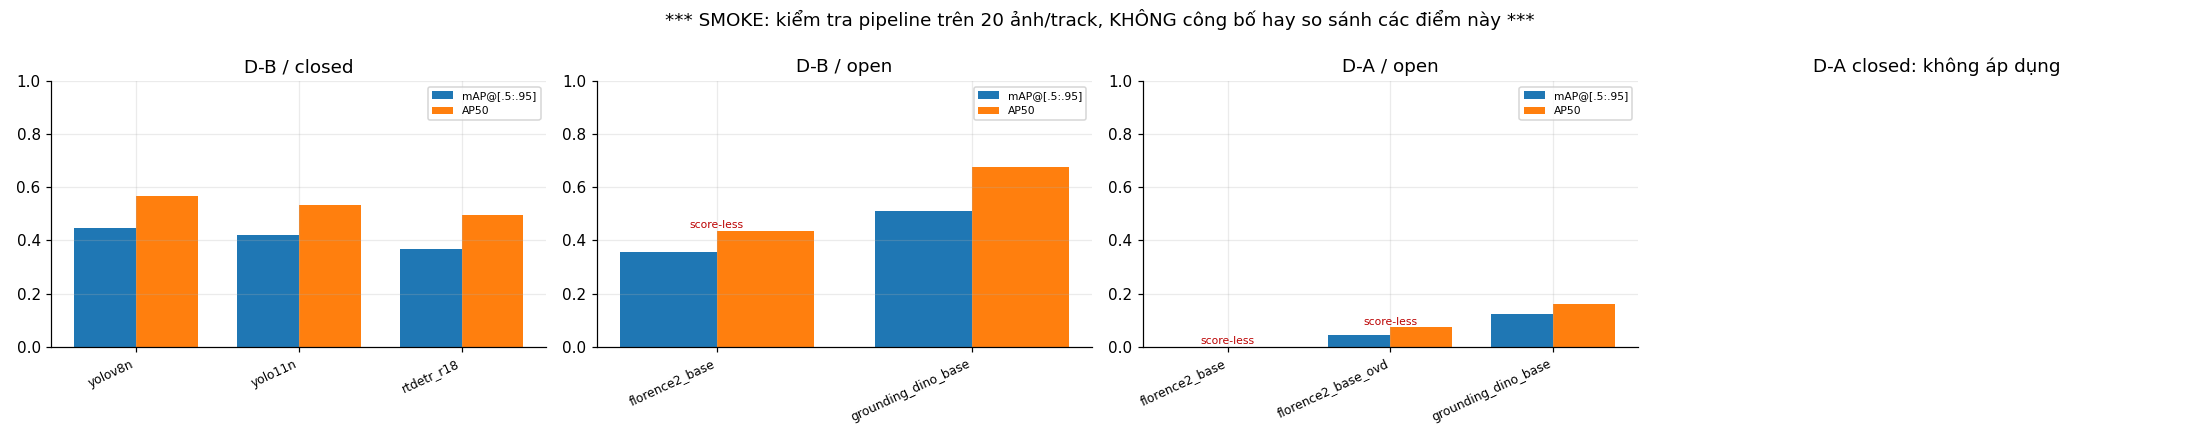

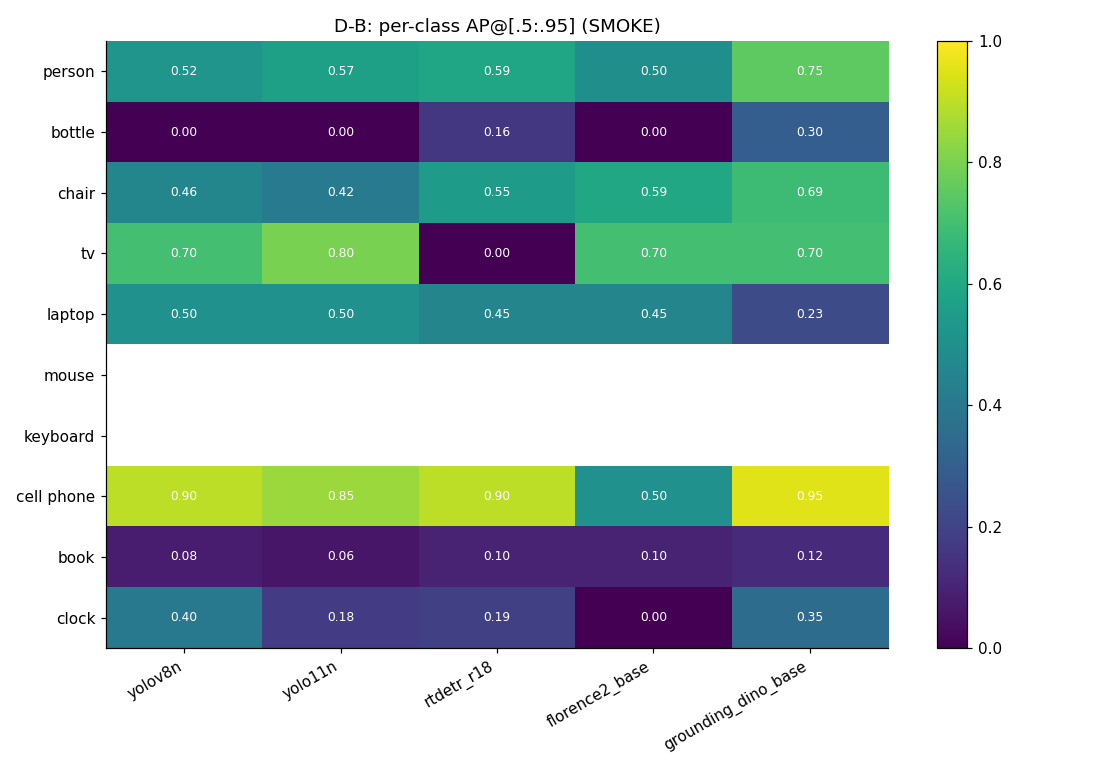

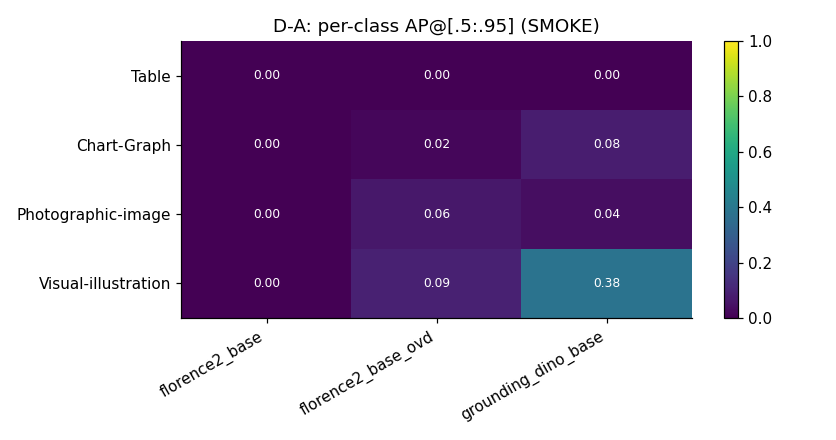

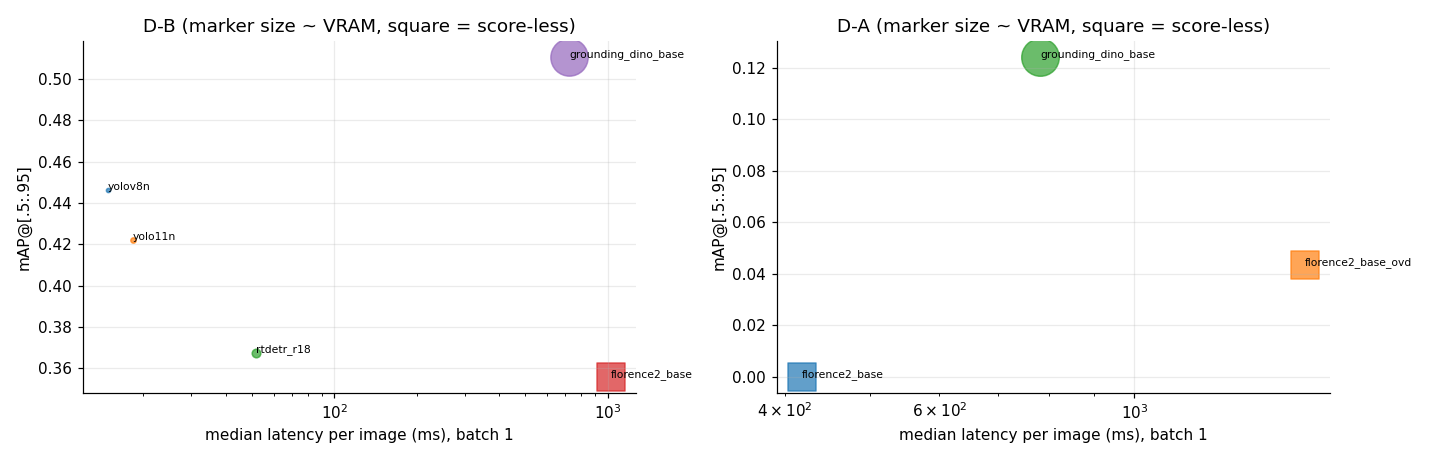


florence2_base|D-B: coverage 0.367; top predicted labels (mapped = recognised by the frozen label map)


,label,boxes,mapped
0,book,58,True
1,person,25,True
2,footwear,19,False
3,magnet,15,False
4,chair,10,True
5,sausage,8,False
6,ski,6,False
7,bowl,6,False
8,lampshade,6,False
9,woman,6,True



grounding_dino_base|D-B: coverage 1.000; top predicted labels (mapped = recognised by the frozen label map)


,label,boxes,mapped
0,person,448,True
1,book,403,True
2,chair,371,True
3,bottle,293,True
4,cell phone,122,True
5,clock,80,True
6,tv,64,True
7,mouse,58,True
8,keyboard,56,True
9,laptop,25,True



florence2_base|D-A: coverage 0.000; top predicted labels (mapped = recognised by the frozen label map)


,label,boxes,mapped
0,poster,13,False
1,person,12,False
2,human face,10,False
3,human head,6,False
4,vehicle,2,False
5,computer monitor,2,False
6,dessert,1,False
7,window,1,False
8,whiteboard,1,False
9,glasses,1,False



florence2_base_ovd|D-A: coverage 1.000; top predicted labels (mapped = recognised by the frozen label map)


,label,boxes,mapped
0,chart,29,True
1,photo,20,True
2,table,20,True
3,illustration,20,True



grounding_dino_base|D-A: coverage 1.000; top predicted labels (mapped = recognised by the frozen label map)


,label,boxes,mapped
0,photograph,429,True
1,plot,356,True
2,chart,311,True
3,cartoon,253,True
4,illustration,166,True
5,picture,141,True
6,photo,126,True
7,graph,85,True
8,data table,80,True
9,diagram,46,True


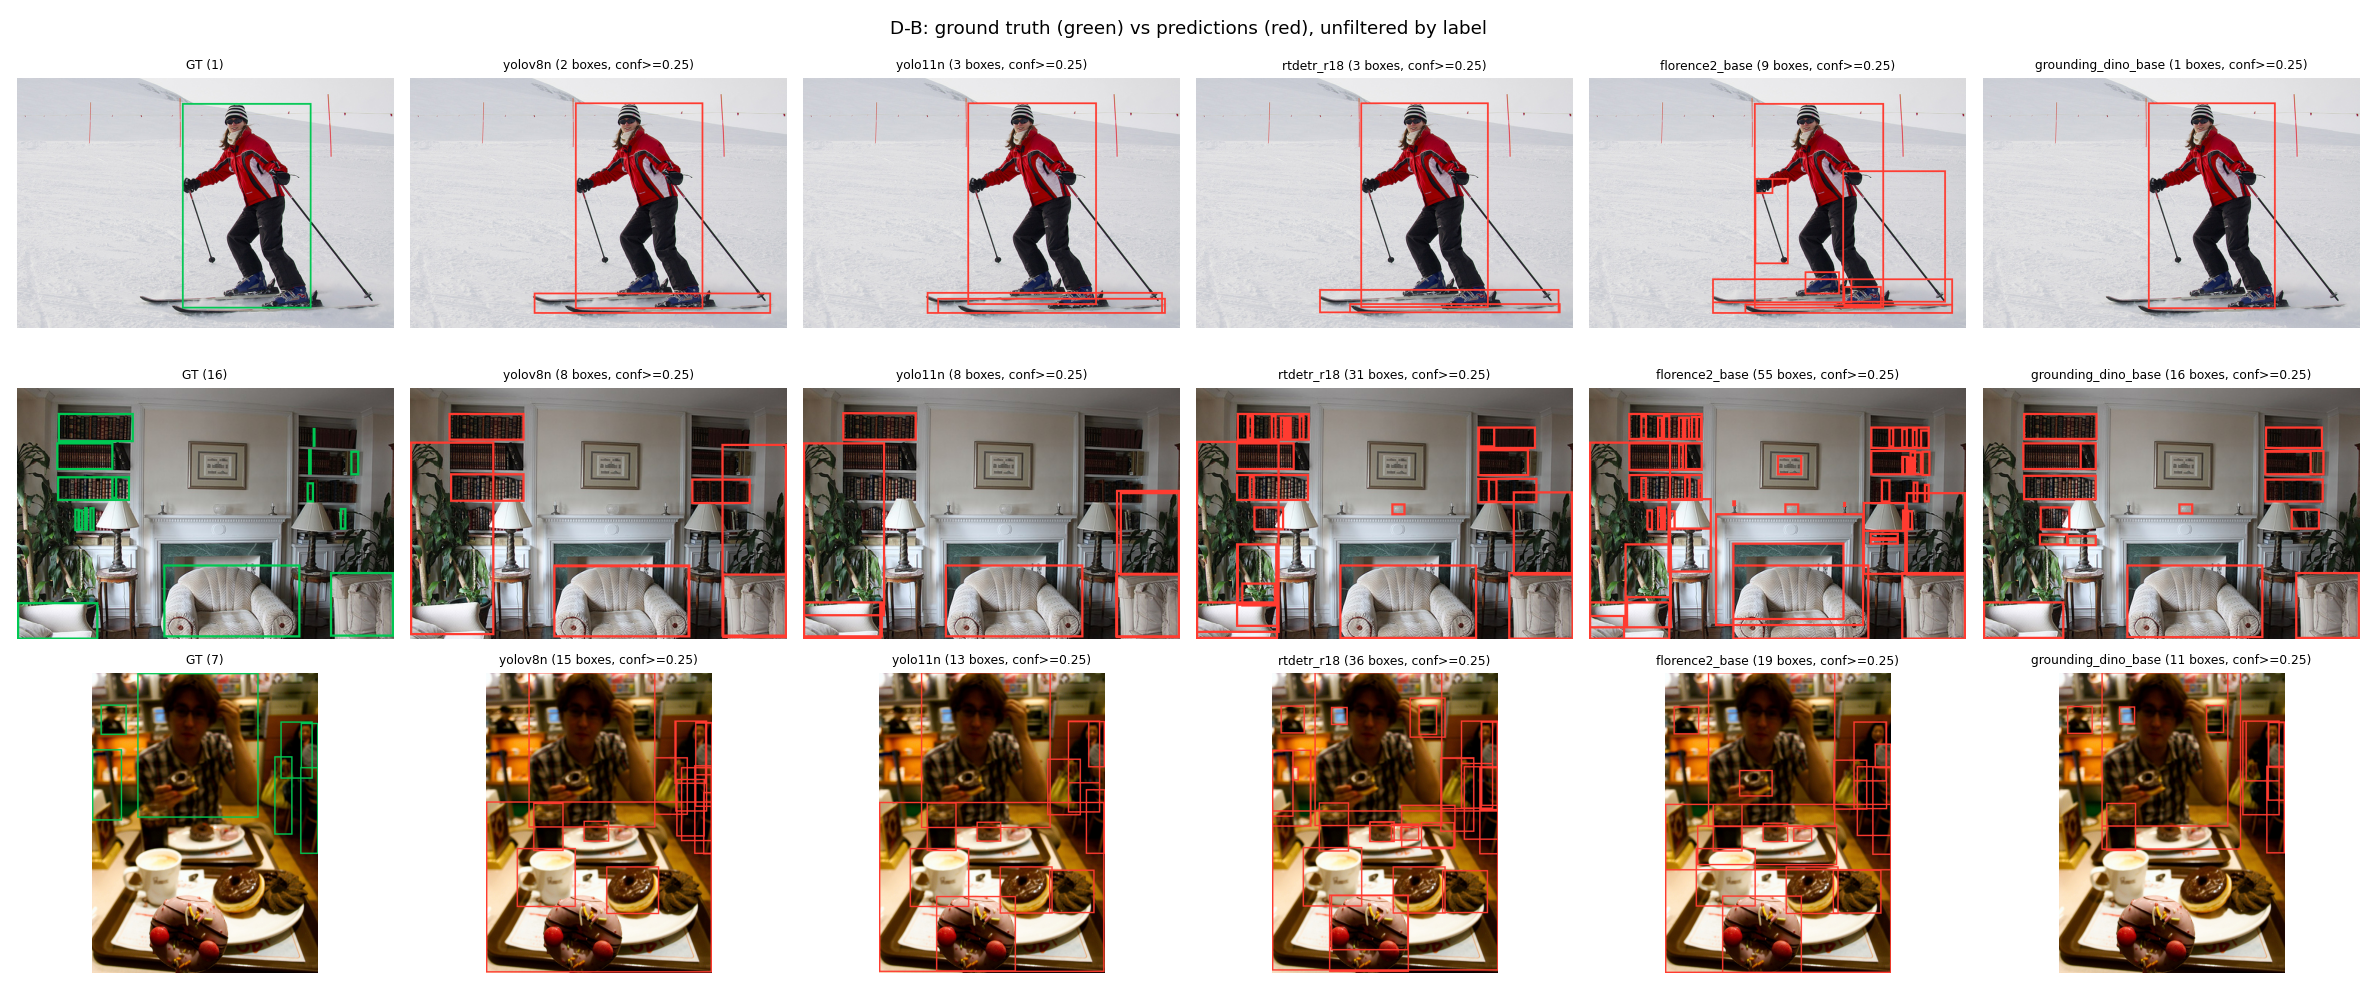

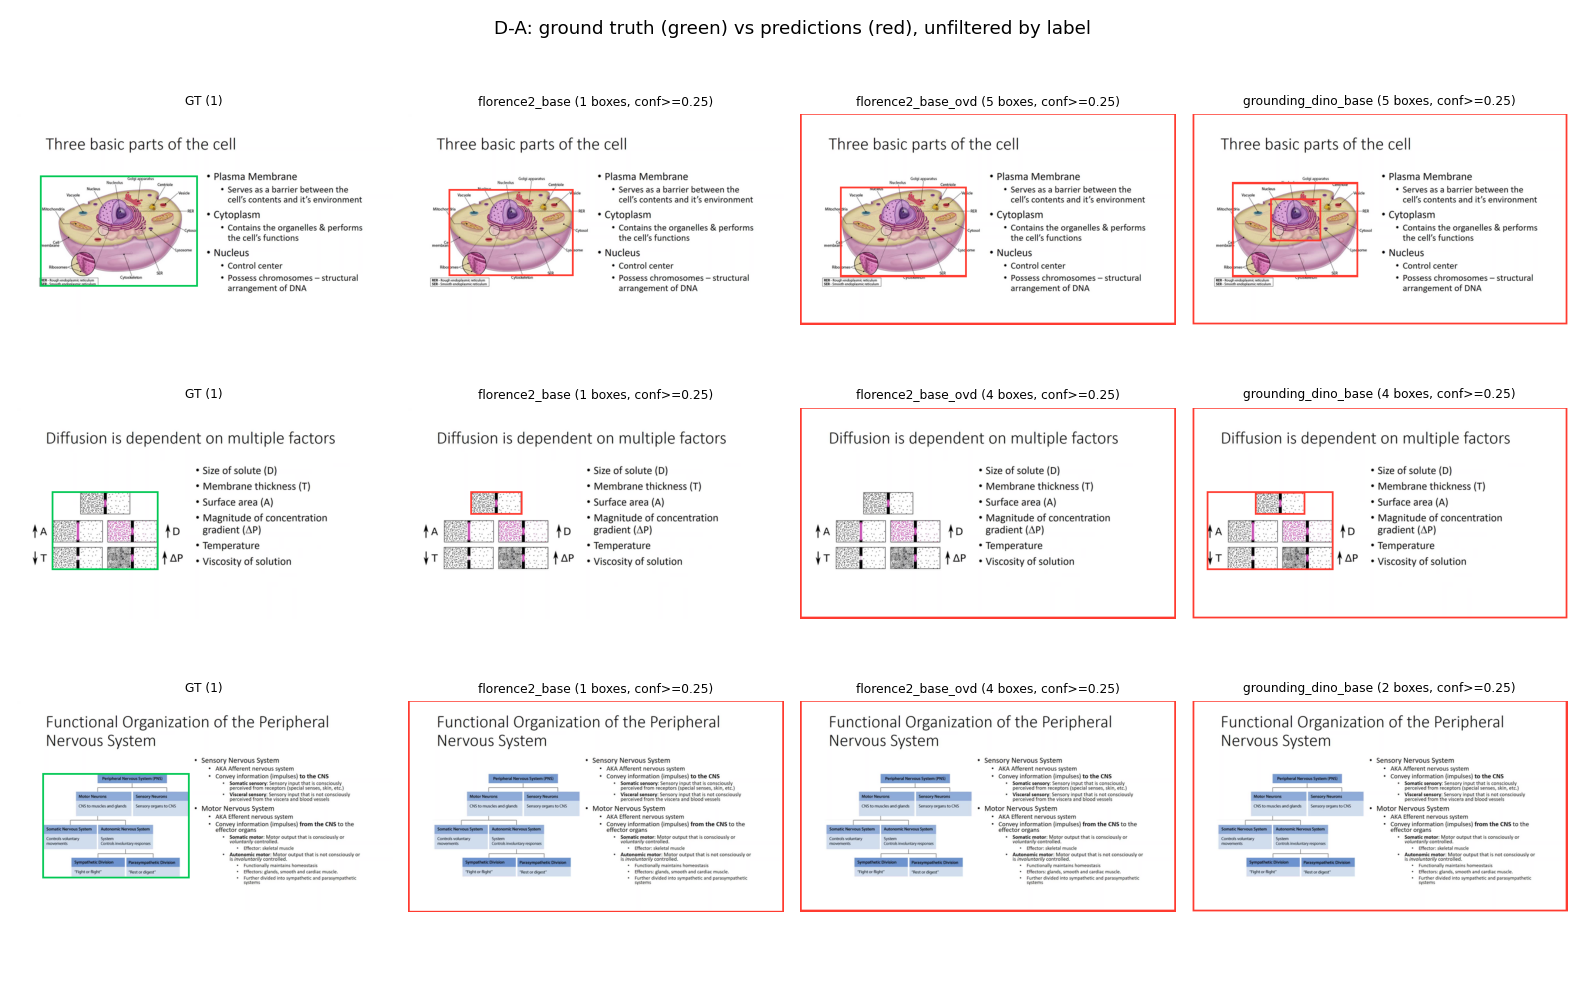

In [10]:
# ---- 1. mAP / AP50 by track (closed and open kept in separate panels) ----
fig, axes = plt.subplots(1, 4, figsize=(20, 4), squeeze=False)
for a, (track, vocab) in zip(axes[0], [('D-B', 'closed'), ('D-B', 'open'), ('D-A', 'open'), ('D-A', 'closed')]):
    t = table(track, vocab)
    if len(t) == 0:
        a.set_title(f'{track} {vocab}: không áp dụng'); a.axis('off'); continue
    x = np.arange(len(t)); w = .38
    a.bar(x - w / 2, t.mAP, w, label='mAP@[.5:.95]'); a.bar(x + w / 2, t.AP50, w, label='AP50')
    for i, sl in enumerate(t.score_less):
        if sl:
            a.text(i, max(t.AP50.iloc[i], t.mAP.iloc[i]) + .01, 'score-less', ha='center', fontsize=7, color='#b00')
    a.set_xticks(x, t.index, rotation=25, ha='right', fontsize=8); a.set_ylim(0, 1); a.set_title(f'{track} / {vocab}'); a.legend(fontsize=7)
fig.suptitle(BANNER if MODE == 'smoke' else 'Headline AP (no composite rank across tracks)')
savefig(fig, 'headline_ap.png')

# ---- 2. per-class AP heatmaps ----
for track in ('D-B', 'D-A'):
    keys = [k for k, r in RESULTS.items() if r['track'] == track]
    if not keys:
        continue
    classes = [c['name'] for c in GT[track]['categories']]
    mat = pd.DataFrame({RESULTS[k]['candidate']: pd.Series(RESULTS[k]['per_class_ap']) for k in keys}).reindex(classes)
    fig, ax = plt.subplots(figsize=(1.2 * len(keys) + 4, 0.5 * len(classes) + 2))
    im = ax.imshow(mat.values.astype(float), vmin=0, vmax=1, cmap='viridis', aspect='auto')
    ax.set_xticks(range(mat.shape[1]), mat.columns, rotation=30, ha='right'); ax.set_yticks(range(mat.shape[0]), mat.index); ax.grid(False)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.values[i, j]
            ax.text(j, i, '-' if pd.isna(v) else f'{v:.2f}', ha='center', va='center', color='w', fontsize=8)
    ax.set_title(f'{track}: per-class AP@[.5:.95]' + (' (SMOKE)' if MODE == 'smoke' else '')); fig.colorbar(im)
    savefig(fig, f'per_class_ap_{track}.png')

# ---- 3. accuracy vs latency (marker size = peak VRAM) ----
rows = [(r['candidate'], r['track'], r['scored']['ap_50_95'], r['latency'].get('median_ms'), r['peak_vram_mb'] or 100, r['score_less']) for r in RESULTS.values()]
if rows:
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    for a, track in zip(ax, ('D-B', 'D-A')):
        for name, tr, m, lat, vram, sl in rows:
            if tr == track and lat:
                a.scatter(lat, m, s=max(vram, 30) / 4, alpha=.7, marker='s' if sl else 'o'); a.annotate(name, (lat, m), fontsize=7)
        a.set_xscale('log'); a.set_xlabel('median latency per image (ms), batch 1'); a.set_ylabel('mAP@[.5:.95]'); a.set_title(f'{track} (marker size ~ VRAM, square = score-less)')
    savefig(fig, 'accuracy_vs_latency.png')

# ---- 4. what do open-vocabulary models say? (diagnoses the label map) ----
for key, r in RESULTS.items():
    if r['vocabulary'] != 'open':
        continue
    rows_ = dr.read_rows(OUT / 'preds' / f"{MODE}_{r['candidate']}_{r['track']}.jsonl")
    labels = Counter(norm for row in rows_ if row['ok'] for d in row['dets'] for norm in [ds.normalise_label(d['label'])])
    lookup = {ds.normalise_label(s) for ss in TAX[r['track']].values() for s in ss} | {ds.normalise_label(k) for k in TAX[r['track']]}
    top = pd.DataFrame([dict(label=l, boxes=n, mapped=l in lookup) for l, n in labels.most_common(15)])
    print(f"\n{key}: coverage {r['mapping']['coverage']:.3f}; top predicted labels (mapped = recognised by the frozen label map)")
    display(top)

# ---- 5. GT vs predictions on the same images ----
def draw(im, boxes, color, width=3):
    d = ImageDraw.Draw(im)
    for x, y, w, h in boxes:
        d.rectangle((x, y, x + w, y + h), outline=color, width=width)
    return im

for track in ('D-B', 'D-A'):
    keys = [k for k, r in RESULTS.items() if r['track'] == track]
    if not keys:
        continue
    ids = track_ids(track)[:3]
    fig, axes = plt.subplots(len(ids), len(keys) + 1, figsize=(3.6 * (len(keys) + 1), 3.0 * len(ids)), squeeze=False)
    for r_i, iid in enumerate(ids):
        base = Image.open(IMG[track][iid]).convert('RGB'); base.thumbnail((640, 640)); scale = base.width / GT[track]['images'][[im['id'] for im in GT[track]['images']].index(iid)]['width']
        gt_boxes = [[v * scale for v in a['bbox']] for a in GT[track]['annotations'] if a['image_id'] == iid]
        axes[r_i, 0].imshow(draw(base.copy(), gt_boxes, '#00c853')); axes[r_i, 0].set_title(f'GT ({len(gt_boxes)})', fontsize=8); axes[r_i, 0].axis('off')
        for c_i, k in enumerate(keys, start=1):
            rows_ = {row['image_id']: row for row in dr.read_rows(OUT / 'preds' / f"{MODE}_{RESULTS[k]['candidate']}_{track}.jsonl")}
            dets = [d for d in rows_.get(iid, {}).get('dets', []) if d['score'] >= (0.25 if not RESULTS[k]['score_less'] else 0)]
            axes[r_i, c_i].imshow(draw(base.copy(), [[v * scale for v in d['bbox']] for d in dets], '#ff3b30'))
            axes[r_i, c_i].set_title(f"{RESULTS[k]['candidate']} ({len(dets)} boxes, conf>=0.25)", fontsize=8); axes[r_i, c_i].axis('off')
    fig.suptitle(f'{track}: ground truth (green) vs predictions (red), unfiltered by label'); savefig(fig, f'overlays_{track}.png')

## 7. Cổng ngân sách
Ước tính GPU-giờ của full run từ latency smoke.

In [11]:
# Budget gate: extrapolate the measured smoke latency to the full cohorts.
full_n = {'D-B': len(GT['D-B']['images']), 'D-A': len(GT['D-A']['images'])}
med = {k: r['latency']['median_ms'] for k, r in RESULTS.items() if r['latency'].get('median_ms')}
est = dr.estimate_gpu_hours(med, full_n)
est_df = pd.Series(est['per_job_hours']).rename('gpu_hours').to_frame()
display(est_df.round(2))
print(f"Ước tính full run 03a: {est['total_hours']:.2f} GPU-giờ trên {GPU or 'CPU (không đáng tin)'} | trần chung 03a+03b = {GPU_BUDGET_HOURS} GPU-giờ")
if MODE == 'smoke':
    gate = dict(estimated_total_hours=est['total_hours'], per_job=est['per_job_hours'], gpu=GPU, budget=GPU_BUDGET_HOURS,
                over_budget=est['total_hours'] > GPU_BUDGET_HOURS, n_smoke=N_SMOKE, valid=GPU is not None,
                finished_utc=datetime.now(timezone.utc).isoformat())
    write_json(OUT / 'smoke-budget-gate.json', gate)
    if not gate['valid']:
        print('Ước tính KHÔNG hợp lệ: smoke chạy trên CPU. Chạy lại smoke trên GPU (Colab T4) trước khi chạy full.')
    elif gate['over_budget']:
        print('DỪNG: ước tính vượt trần. Báo kết quả này cho người duyệt ngân sách; không tự cắt phạm vi.')
    else:
        print('Trong ngân sách (03b chưa tính). Có thể đặt MODE = "full" và chạy lại từ đầu notebook.')

,gpu_hours
yolov8n|D-B,0.06
yolo11n|D-B,0.06
rtdetr_r18|D-B,0.09
florence2_base|D-B,0.79
grounding_dino_base|D-B,0.57
florence2_base|D-A,0.20
florence2_base_ovd|D-A,0.61
grounding_dino_base|D-A,0.33


Ước tính full run 03a: 2.72 GPU-giờ trên Tesla T4 | trần chung 03a+03b = 15.0 GPU-giờ
Trong ngân sách (03b chưa tính). Có thể đặt MODE = "full" và chạy lại từ đầu notebook.


## 8. So sánh cặp (chỉ full)
Bootstrap theo cụm 10.000 lần; kết luận chỉ khi CI cặp loại trừ 0 và |ΔmAP| ≥ 0.02.

In [12]:
# Paired bootstrap (full run only): same resamples for every system, units = images (D-B) or source groups (D-A).
if MODE == 'full':
    DECISIONS = {}
    for track in ('D-B', 'D-A'):
        for vocab in ('closed', 'open'):
            keys = [k for k, r in RESULTS.items() if r['track'] == track and r['vocabulary'] == vocab]
            if len(keys) < 2:
                continue
            ids = track_ids(track)
            groups = None if track == 'D-B' else [LVVO_GROUPS[i] for i in ids]
            mult = pb.cluster_multiplicities(len(ids), groups, 10000, SEED)
            caches = {}
            for k in keys:
                c = next(c for c in dr.CANDIDATES if c.id == RESULTS[k]['candidate'])
                rows_ = dr.read_rows(OUT / 'preds' / f'full_{c.id}_{track}.jsonl')
                name_to_id = {x['name']: x['id'] for x in GT[track]['categories']}
                raw = [dict(image_id=r['image_id'], label=d['label'], bbox=d['bbox'], score=d['score']) for r in rows_ if r['ok'] for d in r['dets']]
                mapped = (ds.map_open_vocab(raw, TAX[track], name_to_id)['preds'] if vocab == 'open' else
                          [dict(image_id=p['image_id'], category_id=name_to_id[p['label']], bbox=p['bbox'], score=p['score']) for p in raw if p['label'] in name_to_id])
                failed = {r['image_id'] for r in rows_ if not r['ok']}
                caches[k] = ds.DetectionCache(GT[track], [p for p in mapped if p['image_id'] not in failed], ids)
            out = []
            for a_i in range(len(keys)):
                for b_i in range(a_i + 1, len(keys)):
                    ka, kb = keys[a_i], keys[b_i]
                    res = pb.paired_bootstrap(caches[ka].map_fn(), caches[kb].map_fn(), mult)
                    verdict = pb.decide_difference(res, 0.02)
                    out.append(dict(a=RESULTS[ka]['candidate'], b=RESULTS[kb]['candidate'], mAP_a=res['a'], mAP_b=res['b'], delta=res['delta'],
                                    ci_lo=res['delta_lo'], ci_hi=res['delta_hi'], verdict=verdict,
                                    note='score-less baseline: not ranked' if any(RESULTS[k]['score_less'] for k in (ka, kb)) else ''))
            df = pd.DataFrame(out)
            print(f'\n=== paired comparison {track}/{vocab} (unit: {"image" if track == "D-B" else "source group"}, 10,000 resamples, threshold 0.02) ===')
            display(df.round(4)); df.to_csv(OUT / 'tables' / f'full_pairs_{track}_{vocab}.csv', index=False)
            DECISIONS[f'{track}|{vocab}'] = df.to_dict('records')
    write_json(OUT / 'tables' / 'full_decisions.json', DECISIONS)
else:
    print('Paired bootstrap chỉ chạy ở MODE = "full".')

Paired bootstrap chỉ chạy ở MODE = "full".


## 9. Lưu kết quả

In [13]:
import importlib.metadata as md
def ver(n):
    try:
        return md.version(n)
    except Exception:
        return None
manifest = dict(
    run_id=RUN_ID, mode=MODE, finished_utc=datetime.now(timezone.utc).isoformat(), gpu=GPU, python=platform.python_version(),
    libraries={n: ver(n) for n in ('torch', 'torchvision', 'transformers', 'ultralytics', 'pycocotools', 'numpy', 'timm', 'einops', 'Pillow')},
    defaults=dr.DEFAULTS, candidates=[dict(id=c.id, family=c.family, vocabulary=c.vocabulary, params=c.params, score_less=c.score_less, tracks=c.tracks) for c in dr.CANDIDATES],
    skipped=SKIPPED, florence_assets_verified=FLORENCE_OK, florence_asset_checks=FLORENCE_VERIFY, source_digests=DIGESTS,
    frozen_gt_sha=dict(lvvo=REG['lvvo']['gt_coco_canonical_sha256'], coco=REG['coco']['gt_coco_canonical_sha256']),
    sample_ids=SAMPLE if MODE == 'smoke' else None,
    preds_sha256={p.name: q.sha256_file(p) for p in sorted((OUT / 'preds').glob(f'{MODE}_*.jsonl'))},
    reportable=(MODE == 'full'), note='smoke results validate the pipeline only' if MODE == 'smoke' else 'frozen protocol, all frozen images')
write_json(OUT / f'{MODE}_manifest.json', manifest)
bundle = OUT / f'bundle_{MODE}.zip'
with zipfile.ZipFile(bundle, 'w', zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(OUT.rglob('*')):
        if path.is_file() and path.suffix in {'.json', '.csv', '.png', '.jsonl'} and not path.name.startswith('bundle_'):
            zf.write(path, path.relative_to(OUT))
print('Bundle:', bundle, f'{bundle.stat().st_size / 1e6:.1f} MB')

Bundle: /content/drive/MyDrive/DetTrack/det-03a-261026-v1/bundle_smoke.zip 1.4 MB
